In [ ]:
# %pip install pandas numpy seaborn scikit-learn scipy statsmodels catboost optuna xgboost ipywidgets

# Bank Marketing Dataset

## Data Initialization

In [407]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import chi2_contingency, spearmanr
from scipy.stats.contingency import association
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.rcParams["figure.figsize"] = (10, 6)

In [3]:
df = pd.read_csv("bank-full.csv")
df_old = df[df["pdays"] != -1]
df_new = df[df["pdays"] == -1]
df["y_numeric"] = df["y"].map({"no": 0, "yes": 1})
df_old["y_numeric"] = df_old["y"].map({"no": 0, "yes": 1})
df_new["y_numeric"] = df_new["y"].map({"no": 0, "yes": 1})

In [4]:
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,y_numeric
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes,1
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes,1
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes,1
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
 17  y_numeric  45211 non-null  int64
dtypes: int64(8), str(10)
memory usage: 6.2 MB


## Exploratory Data Analysis

### Univariate Analysis

#### Target Variable

In [6]:
y_counts = df["y"].value_counts()
y_counts

y
no     39922
yes     5289
Name: count, dtype: int64

In [7]:
y_counts / y_counts.sum() * 100

y
no     88.30152
yes    11.69848
Name: count, dtype: float64

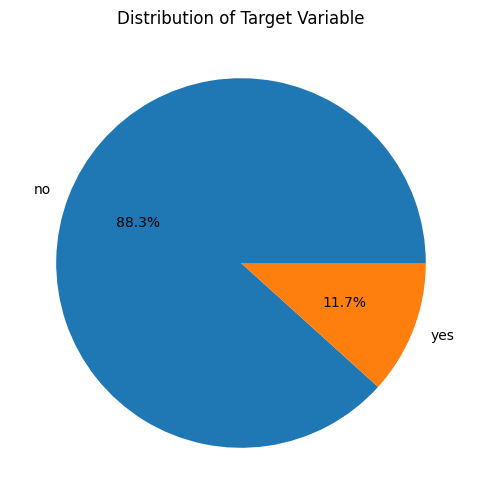

In [8]:
plt.pie(y_counts, labels=y_counts.index, autopct="%1.1f%%")
plt.title("Distribution of Target Variable")
plt.show()

There is a class imbalance in target variable. It is a normal behaviour for a marketing campaign that there are more people to decline than accept the offer.

In [9]:
y_old_counts = df_old["y"].value_counts()
y_old_counts

y
no     6352
yes    1905
Name: count, dtype: int64

In [10]:
y_old_counts / y_old_counts.sum() * 100

y
no     76.928667
yes    23.071333
Name: count, dtype: float64

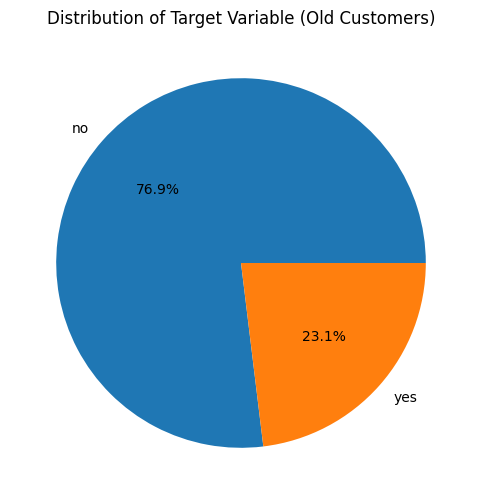

In [11]:
plt.pie(y_old_counts, labels=y_old_counts.index, autopct="%1.1f%%")
plt.title("Distribution of Target Variable (Old Customers)")
plt.show()

In [12]:
y_new_counts = df_new["y"].value_counts()
y_new_counts

y
no     33570
yes     3384
Name: count, dtype: int64

In [13]:
y_new_counts / y_new_counts.sum() * 100

y
no     90.842669
yes     9.157331
Name: count, dtype: float64

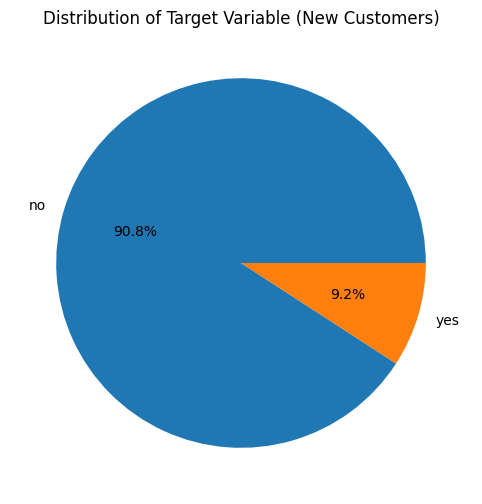

In [14]:
plt.pie(y_new_counts, labels=y_new_counts.index, autopct="%1.1f%%")
plt.title("Distribution of Target Variable (New Customers)")
plt.show()

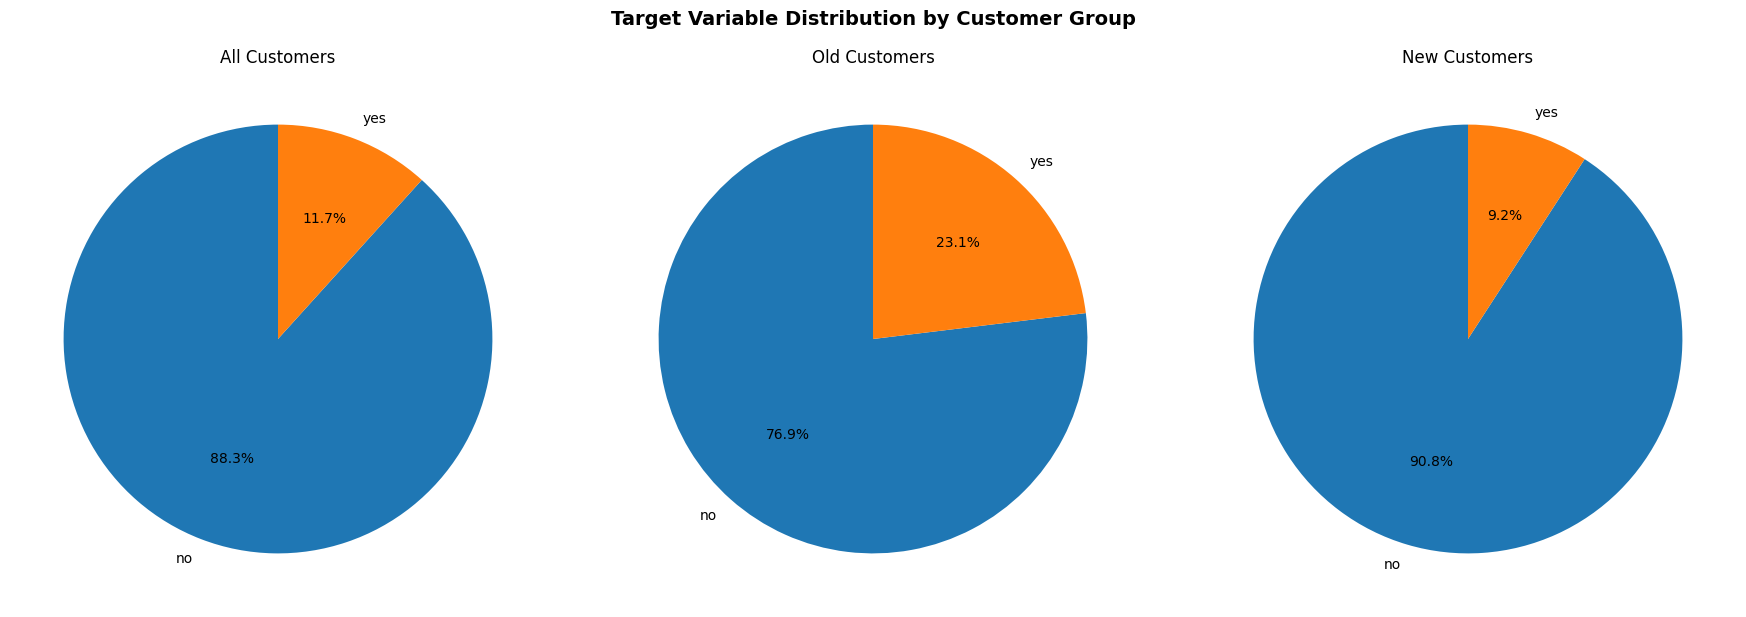

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (data, title) in zip(
    axes,
    [
        (y_counts, "All Customers"),
        (y_old_counts, "Old Customers"),
        (y_new_counts, "New Customers"),
    ],
):
    ax.pie(data, labels=data.index, autopct="%1.1f%%", startangle=90)
    ax.set_title(f"{title}")

plt.suptitle(
    "Target Variable Distribution by Customer Group",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

After seperation, the class imbalance for old customers is decreased, but for new ones it further increased slightly

#### Binary Features

##### default

In [16]:
default_counts = df["default"].value_counts()
default_counts

default
no     44396
yes      815
Name: count, dtype: int64

In [17]:
default_counts / default_counts.sum() * 100

default
no     98.197341
yes     1.802659
Name: count, dtype: float64

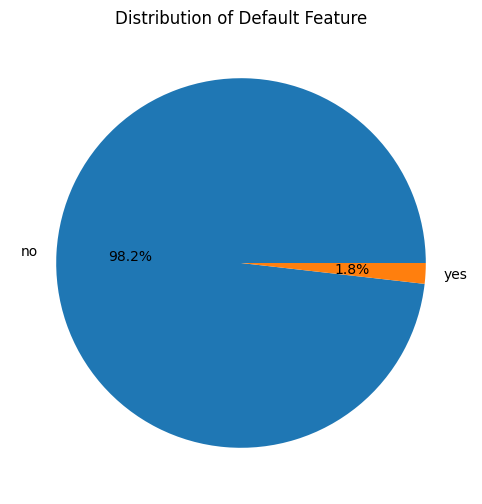

In [18]:
plt.pie(default_counts, labels=default_counts.index, autopct="%1.1f%%")
plt.title("Distribution of Default Feature")
plt.show()

Most people don't have previous credit default which means they are more likely to make deposit than who has failed to pay their loan

In [19]:
default_old_counts = df_old["default"].value_counts()
default_old_counts

default
no     8200
yes      57
Name: count, dtype: int64

In [20]:
default_old_counts / default_old_counts.sum() * 100

default
no     99.309677
yes     0.690323
Name: count, dtype: float64

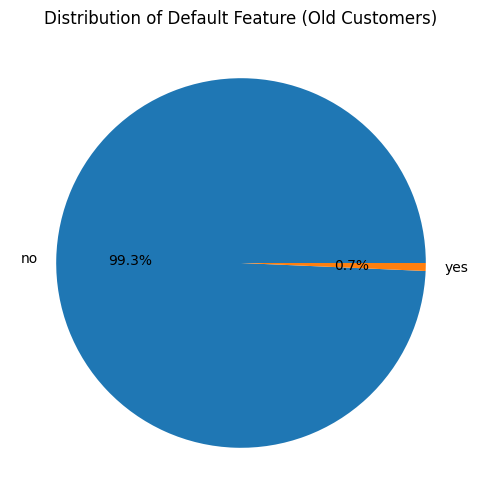

In [21]:
plt.pie(default_old_counts, labels=default_old_counts.index, autopct="%1.1f%%")
plt.title("Distribution of Default Feature (Old Customers)")
plt.show()

In [22]:
default_new_counts = df_new["default"].value_counts()
default_new_counts

default
no     36196
yes      758
Name: count, dtype: int64

In [23]:
default_new_counts / default_new_counts.sum() * 100

default
no     97.948801
yes     2.051199
Name: count, dtype: float64

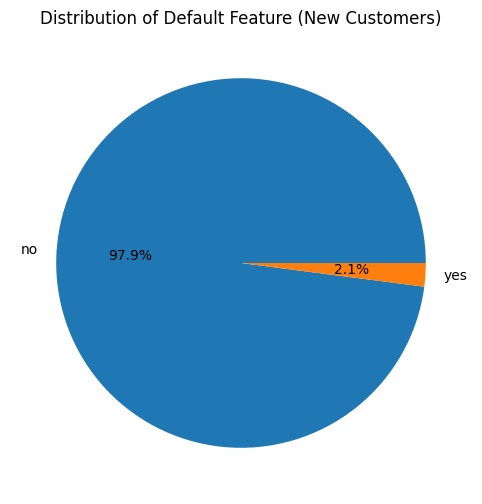

In [24]:
plt.pie(default_new_counts, labels=default_new_counts.index, autopct="%1.1f%%")
plt.title("Distribution of Default Feature (New Customers)")
plt.show()

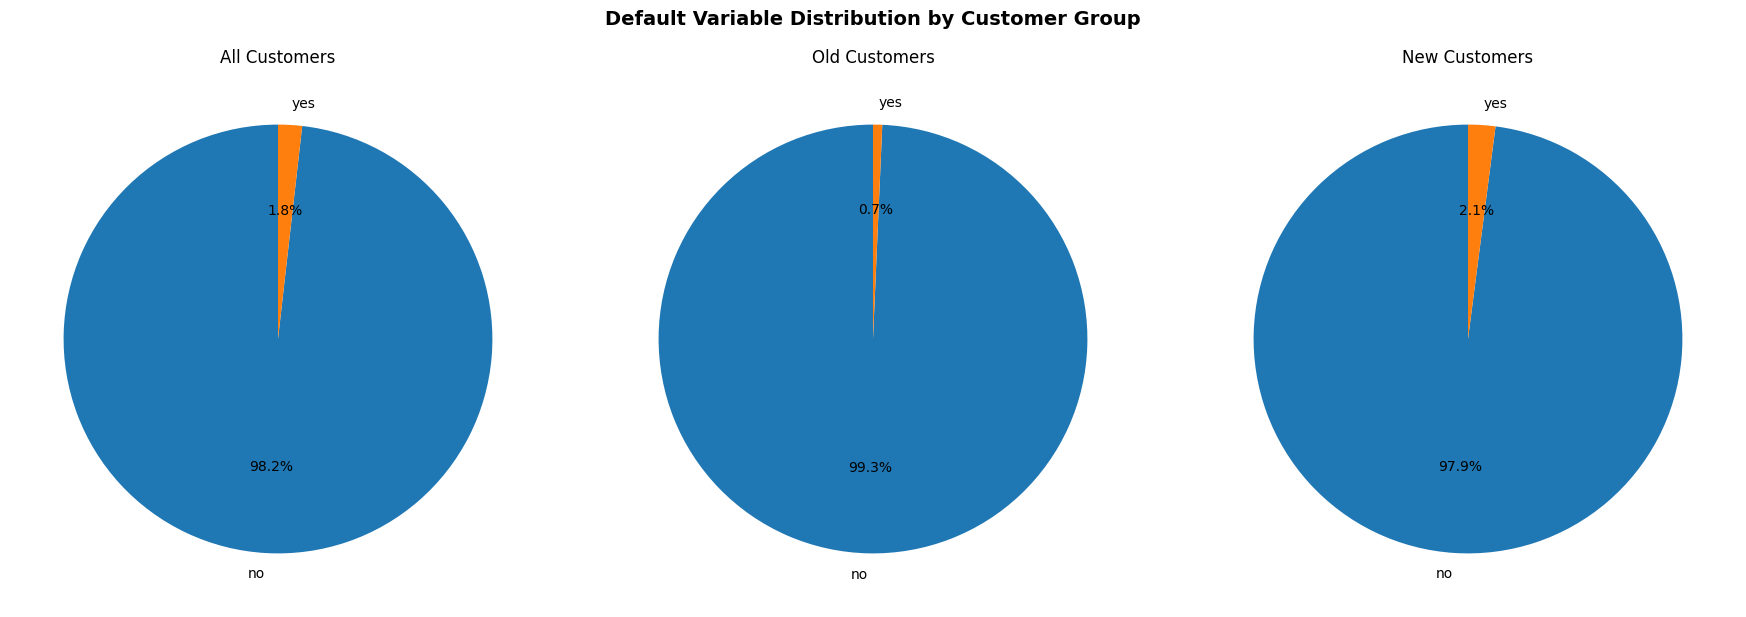

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (data, title) in zip(
    axes,
    [
        (default_counts, "All Customers"),
        (default_old_counts, "Old Customers"),
        (default_new_counts, "New Customers"),
    ],
):
    ax.pie(data, labels=data.index, autopct="%1.1f%%", startangle=90)
    ax.set_title(f"{title}")

plt.suptitle(
    "Default Variable Distribution by Customer Group",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

This feature is still imbalanced after seperation and probably will be dismissed

##### housing

In [26]:
housing_counts = df["housing"].value_counts()
housing_counts

housing
yes    25130
no     20081
Name: count, dtype: int64

In [27]:
housing_counts / housing_counts.sum() * 100

housing
yes    55.583818
no     44.416182
Name: count, dtype: float64

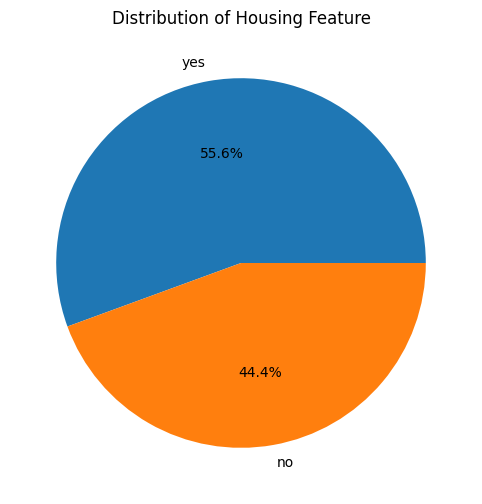

In [28]:
plt.pie(housing_counts, labels=housing_counts.index, autopct="%1.1f%%")
plt.title("Distribution of Housing Feature")
plt.show()

This feature is more balanced and it is more likely that people who don't have housing loan to make a deposit.

In [29]:
housing_old_counts = df_old["housing"].value_counts()
housing_old_counts

housing
yes    5142
no     3115
Name: count, dtype: int64

In [30]:
housing_old_counts / housing_old_counts.sum() * 100

housing
yes    62.274434
no     37.725566
Name: count, dtype: float64

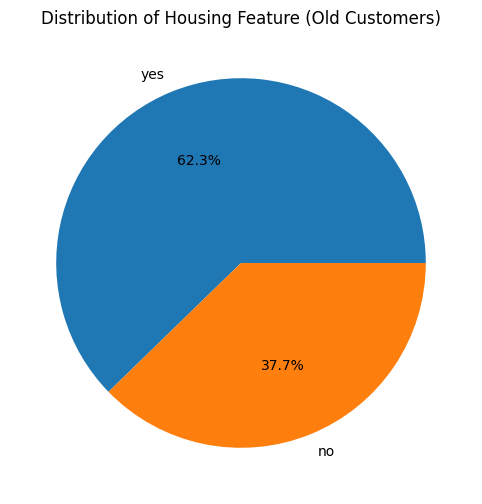

In [31]:
plt.pie(housing_old_counts, labels=housing_old_counts.index, autopct="%1.1f%%")
plt.title("Distribution of Housing Feature (Old Customers)")
plt.show()

In [32]:
housing_new_counts = df_new["housing"].value_counts()
housing_new_counts

housing
yes    19988
no     16966
Name: count, dtype: int64

In [33]:
housing_new_counts / housing_new_counts.sum() * 100

housing
yes    54.088867
no     45.911133
Name: count, dtype: float64

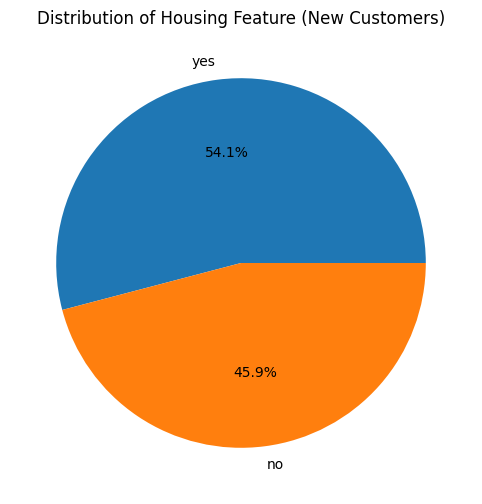

In [34]:
plt.pie(housing_new_counts, labels=housing_new_counts.index, autopct="%1.1f%%")
plt.title("Distribution of Housing Feature (New Customers)")
plt.show()

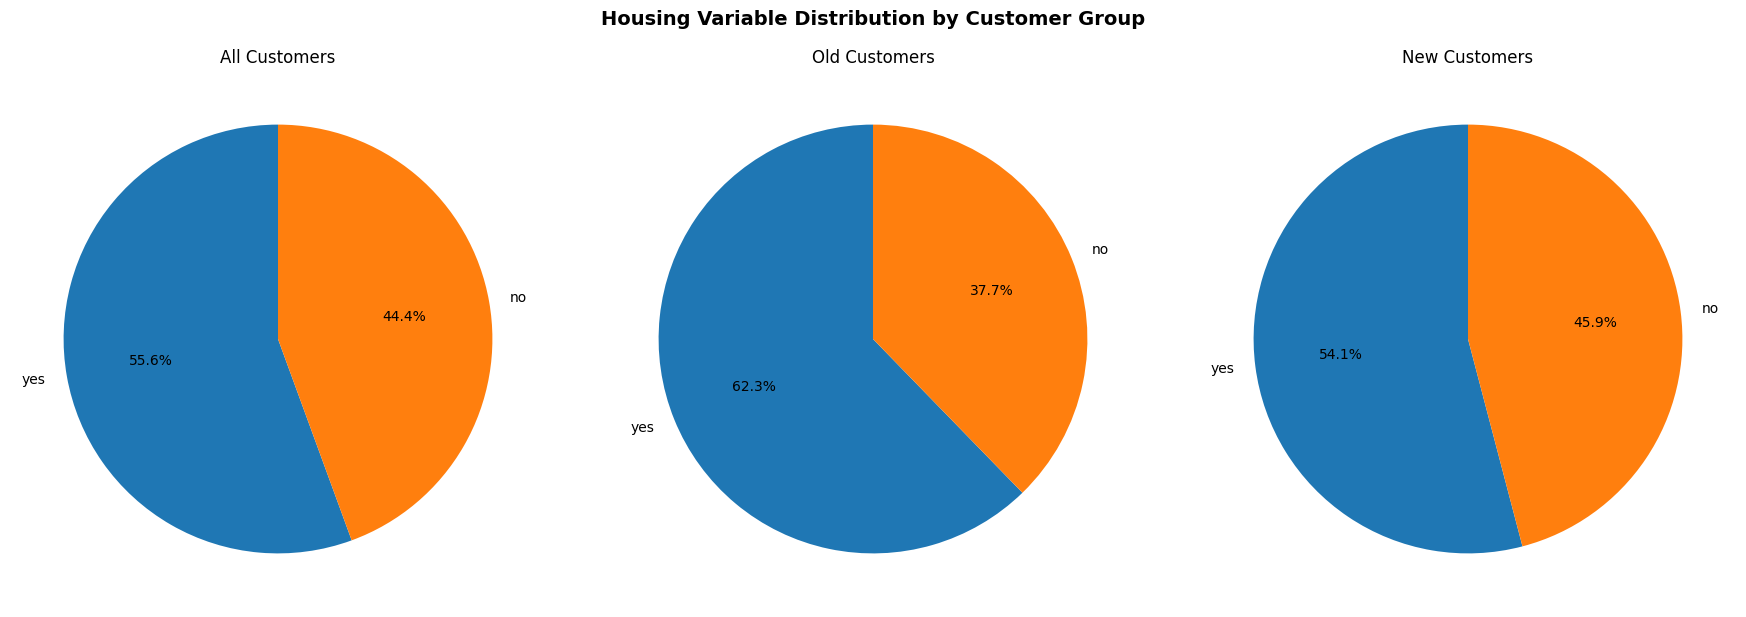

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (data, title) in zip(
    axes,
    [
        (housing_counts, "All Customers"),
        (housing_old_counts, "Old Customers"),
        (housing_new_counts, "New Customers"),
    ],
):
    ax.pie(data, labels=data.index, autopct="%1.1f%%", startangle=90)
    ax.set_title(f"{title}")

plt.suptitle(
    "Housing Variable Distribution by Customer Group",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

The feature is still somewhat balanced after seperation

##### loan

In [36]:
loan_counts = df["loan"].value_counts()
loan_counts

loan
no     37967
yes     7244
Name: count, dtype: int64

In [37]:
loan_counts / loan_counts.sum() * 100

loan
no     83.977351
yes    16.022649
Name: count, dtype: float64

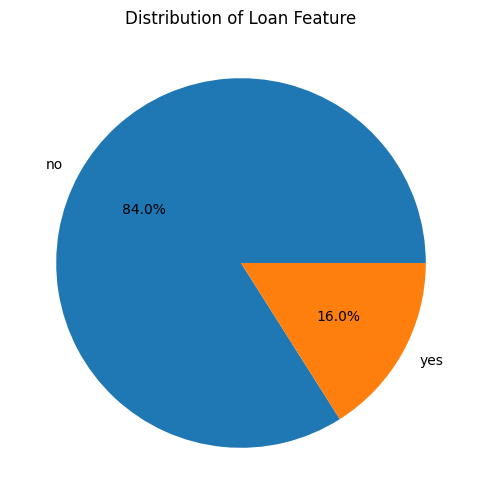

In [38]:
plt.pie(loan_counts, labels=loan_counts.index, autopct="%1.1f%%")
plt.title("Distribution of Loan Feature")
plt.show()

The same principle is applied here

In [39]:
loan_old_counts = df_old["loan"].value_counts()
loan_old_counts

loan
no     7134
yes    1123
Name: count, dtype: int64

In [40]:
loan_old_counts / loan_old_counts.sum() * 100

loan
no     86.399419
yes    13.600581
Name: count, dtype: float64

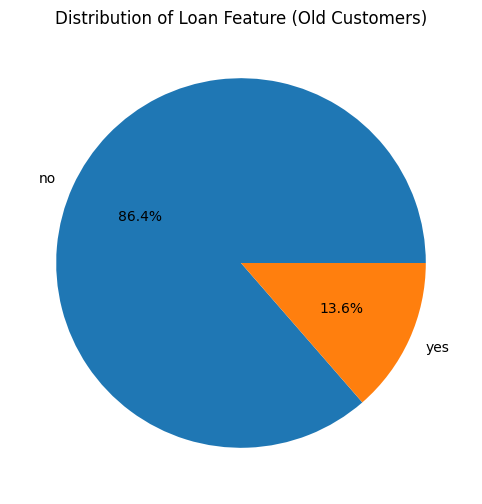

In [41]:
plt.pie(loan_old_counts, labels=loan_old_counts.index, autopct="%1.1f%%")
plt.title("Distribution of Loan Feature (Old Customers)")
plt.show()

In [42]:
loan_new_counts = df_new["loan"].value_counts()
loan_new_counts

loan
no     30833
yes     6121
Name: count, dtype: int64

In [43]:
loan_new_counts / loan_new_counts.sum() * 100

loan
no     83.436164
yes    16.563836
Name: count, dtype: float64

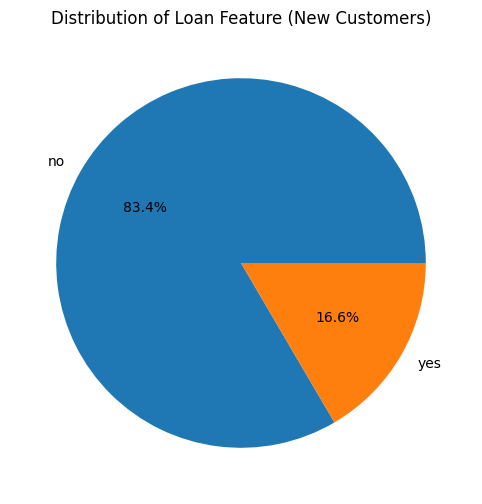

In [44]:
plt.pie(loan_new_counts, labels=loan_new_counts.index, autopct="%1.1f%%")
plt.title("Distribution of Loan Feature (New Customers)")
plt.show()

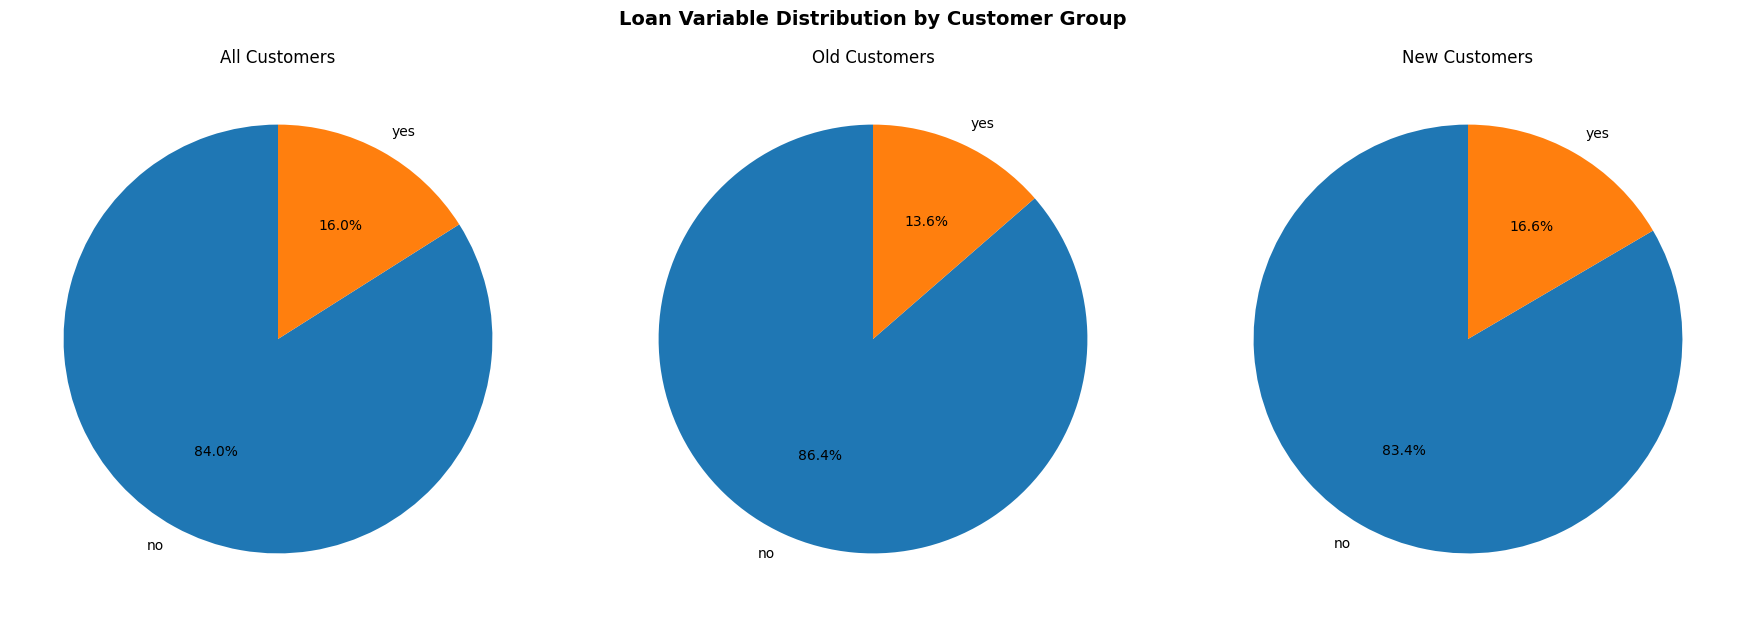

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (data, title) in zip(
    axes,
    [
        (loan_counts, "All Customers"),
        (loan_old_counts, "Old Customers"),
        (loan_new_counts, "New Customers"),
    ],
):
    ax.pie(data, labels=data.index, autopct="%1.1f%%", startangle=90)
    ax.set_title(f"{title}")

plt.suptitle(
    "Loan Variable Distribution by Customer Group",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

Again, the distribution haven't changed much

#### Categorical Features

##### job

In [46]:
job_counts = df["job"].value_counts()
job_counts

job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64

In [47]:
job_counts / job_counts.sum() * 100

job
blue-collar      21.525735
management       20.919688
technician       16.803433
admin.           11.437482
services          9.188029
retired           5.007631
self-employed     3.492513
entrepreneur      3.289023
unemployed        2.882042
housemaid         2.742695
student           2.074716
unknown           0.637013
Name: count, dtype: float64

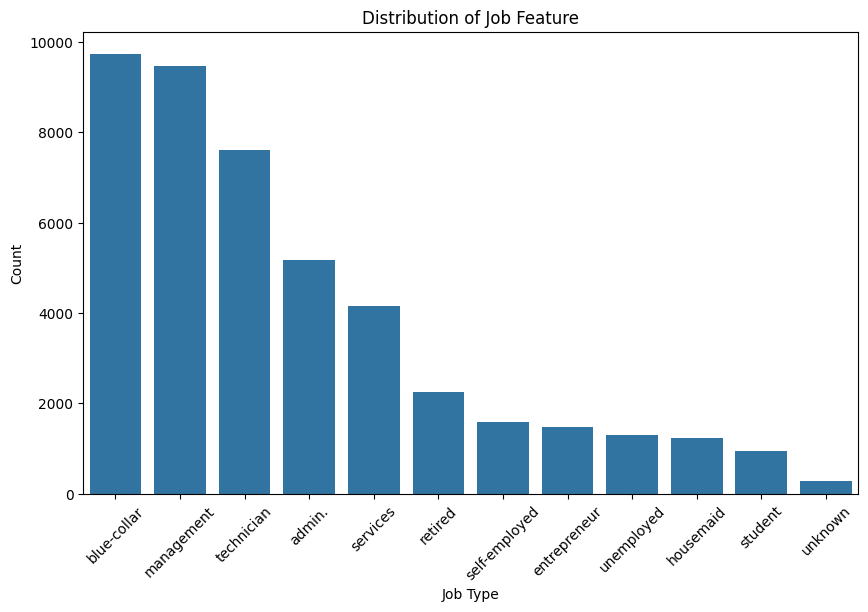

In [48]:
sns.barplot(x=job_counts.index, y=job_counts.values)
plt.title("Distribution of Job Feature")
plt.xlabel("Job Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

Among these job types, it is less likely for unemployed and students to make a deposit (it needs to be verified though)

In [49]:
job_old_counts = df_old["job"].value_counts()
job_old_counts

job
management       1826
blue-collar      1617
technician       1342
admin.           1089
services          706
retired           488
student           285
self-employed     281
entrepreneur      225
unemployed        213
housemaid         152
unknown            33
Name: count, dtype: int64

In [50]:
job_old_counts / job_old_counts.sum() * 100

job
management       22.114569
blue-collar      19.583384
technician       16.252876
admin.           13.188809
services          8.550321
retired           5.910137
student           3.451617
self-employed     3.403173
entrepreneur      2.724961
unemployed        2.579629
housemaid         1.840862
unknown           0.399661
Name: count, dtype: float64

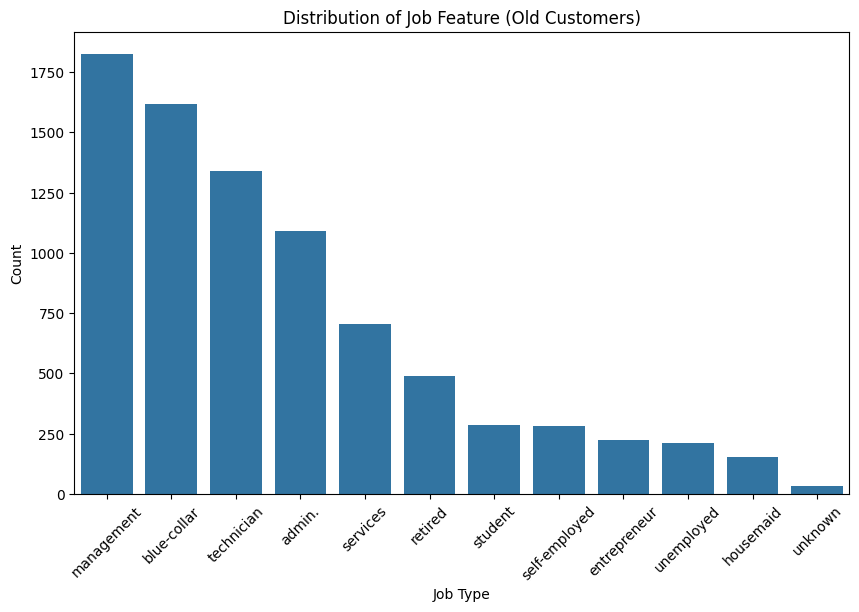

In [51]:
sns.barplot(x=job_old_counts.index, y=job_old_counts.values)
plt.title("Distribution of Job Feature (Old Customers)")
plt.xlabel("Job Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

In [52]:
job_new_counts = df_new["job"].value_counts()
job_new_counts

job
blue-collar      8115
management       7632
technician       6255
admin.           4082
services         3448
retired          1776
self-employed    1298
entrepreneur     1262
unemployed       1090
housemaid        1088
student           653
unknown           255
Name: count, dtype: int64

In [53]:
job_new_counts / job_new_counts.sum() * 100

job
blue-collar      21.959734
management       20.652703
technician       16.926449
admin.           11.046166
services          9.330519
retired           4.805975
self-employed     3.512475
entrepreneur      3.415057
unemployed        2.949613
housemaid         2.944201
student           1.767062
unknown           0.690047
Name: count, dtype: float64

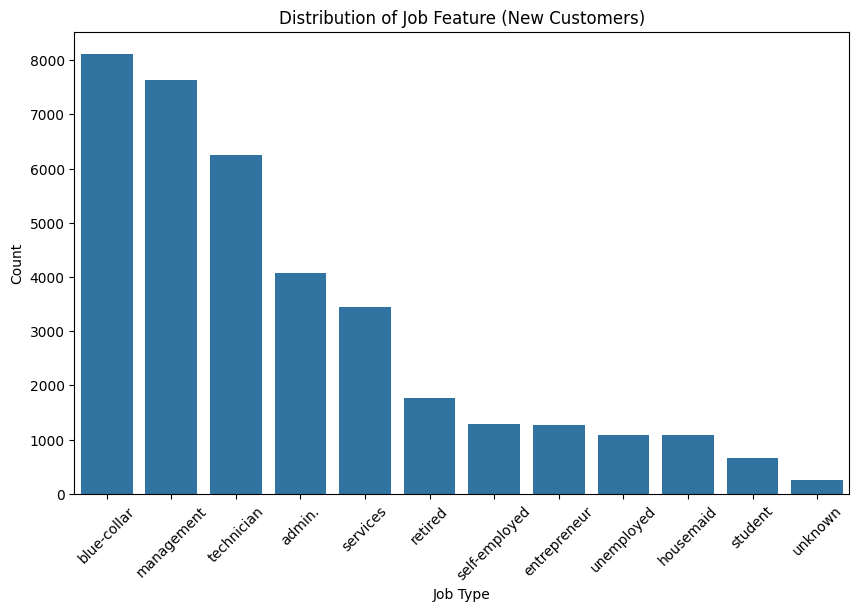

In [54]:
sns.barplot(x=job_new_counts.index, y=job_new_counts.values)
plt.title("Distribution of Job Feature (New Customers)")
plt.xlabel("Job Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

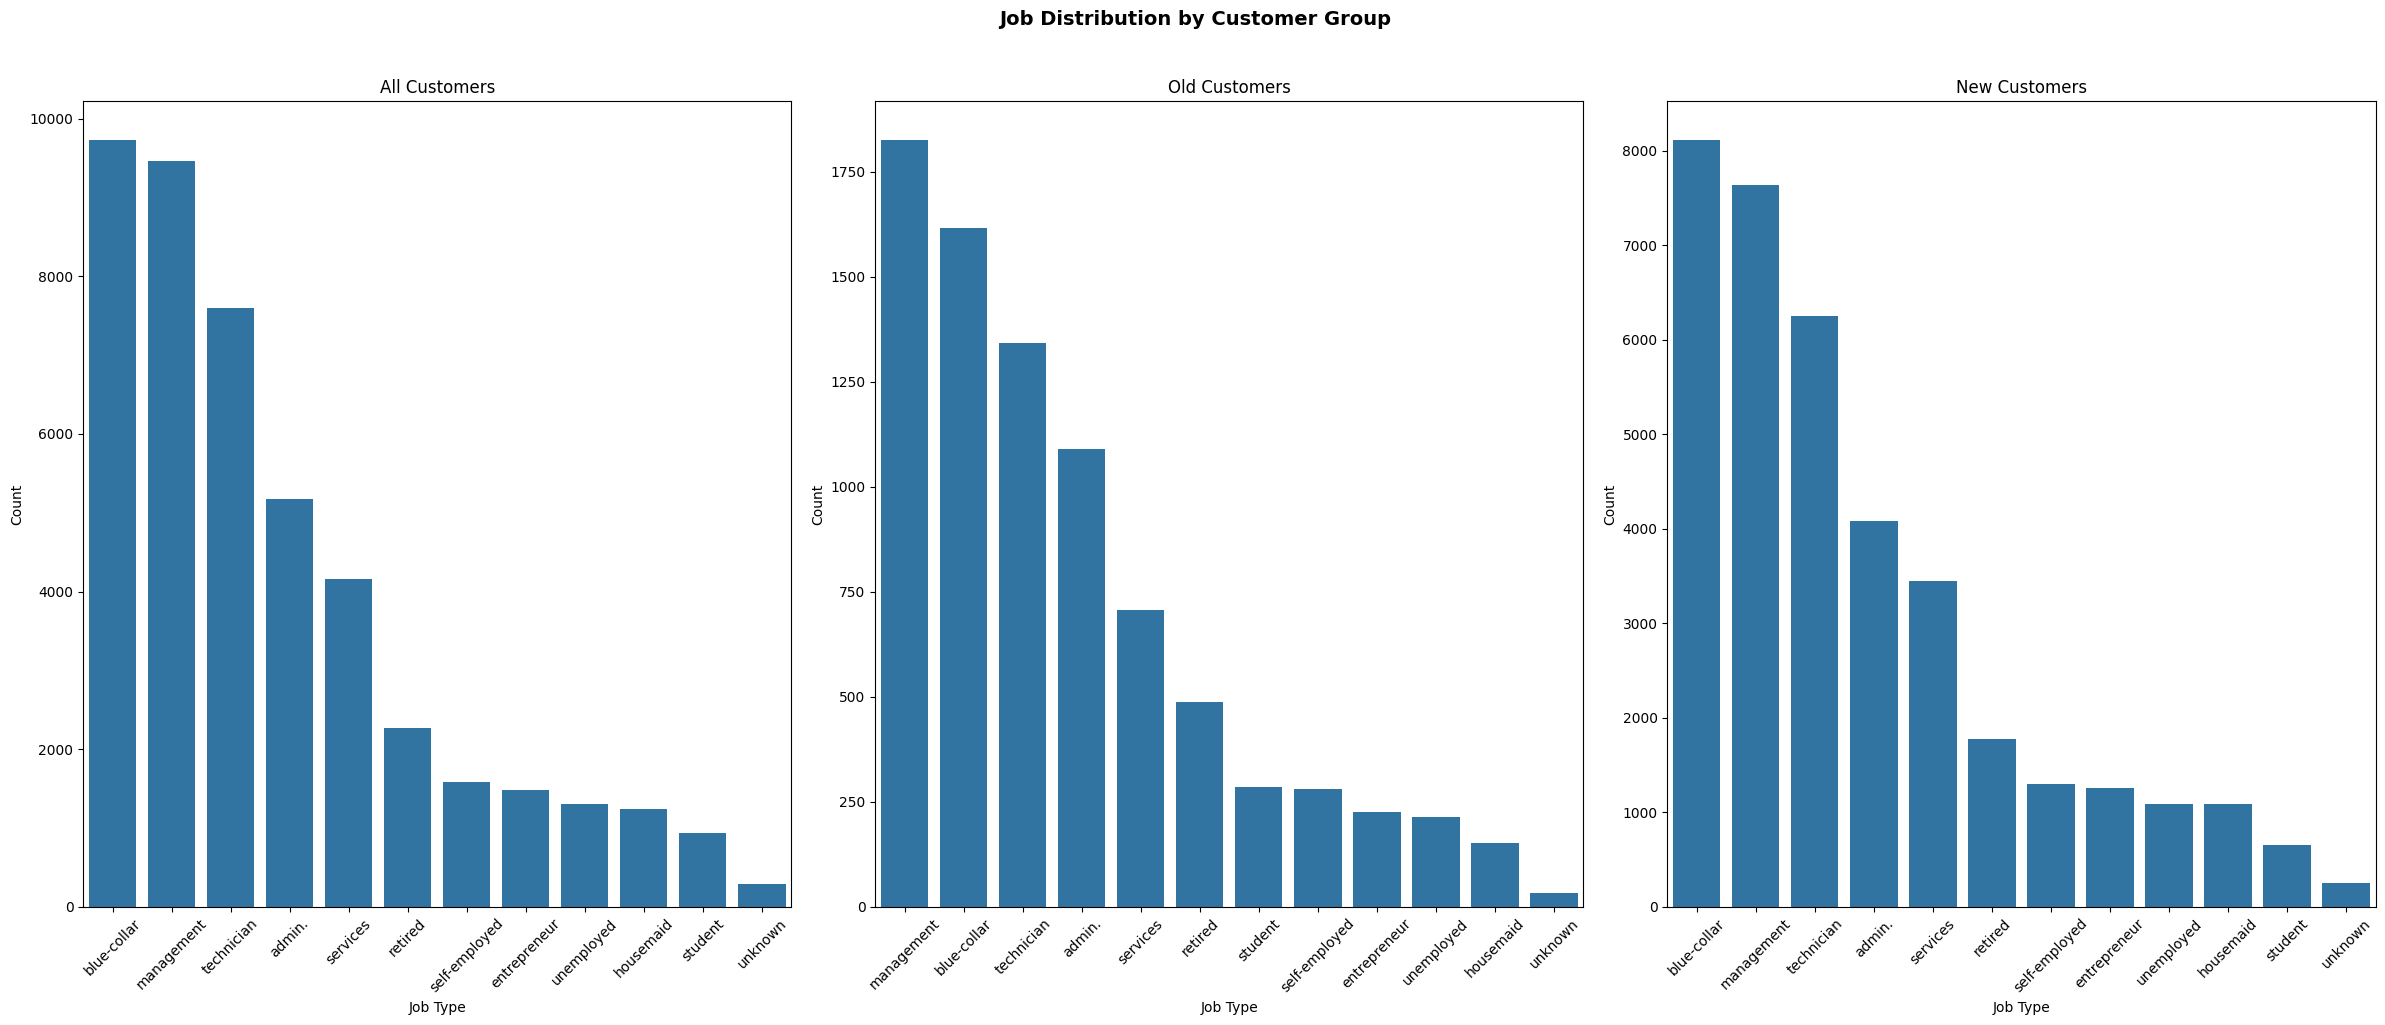

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(24, 10))

for ax, (data, title) in zip(
    axes,
    [
        (job_counts, "All Customers"),
        (job_old_counts, "Old Customers"),
        (job_new_counts, "New Customers"),
    ],
):
    sns.barplot(x=data.index, y=data.values, ax=ax)
    ax.set_title(f"{title}")
    ax.set_xlabel("Job Type")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle(
    "Job Distribution by Customer Group", fontsize=14, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

Distribution haven't changed for new customers, but slightly changed for old ones

##### marital

In [56]:
marital_counts = df["marital"].value_counts()
marital_counts

marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64

In [57]:
marital_counts / marital_counts.sum() * 100

marital
married     60.193316
single      28.289576
divorced    11.517109
Name: count, dtype: float64

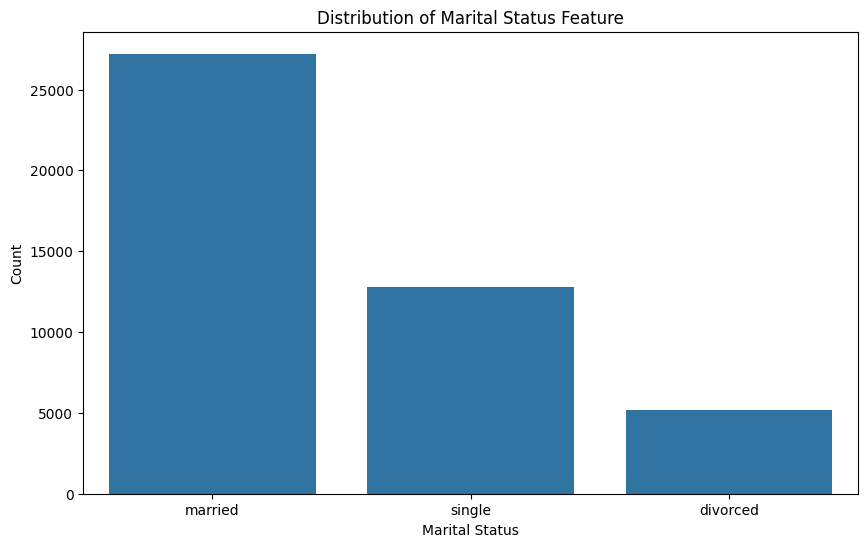

In [58]:
sns.barplot(x=marital_counts.index, y=marital_counts.values)
plt.title("Distribution of Marital Status Feature")
plt.xlabel("Marital Status")
plt.ylabel("Count")
plt.show()

Most people contacted are married which are more likely to have a stable financial situation. But there is nothing obvious to assume in advance

In [59]:
marital_old_counts = df_old["marital"].value_counts()
marital_old_counts

marital
married     4745
single      2581
divorced     931
Name: count, dtype: int64

In [60]:
marital_old_counts / marital_old_counts.sum() * 100

marital
married     57.466392
single      31.258326
divorced    11.275282
Name: count, dtype: float64

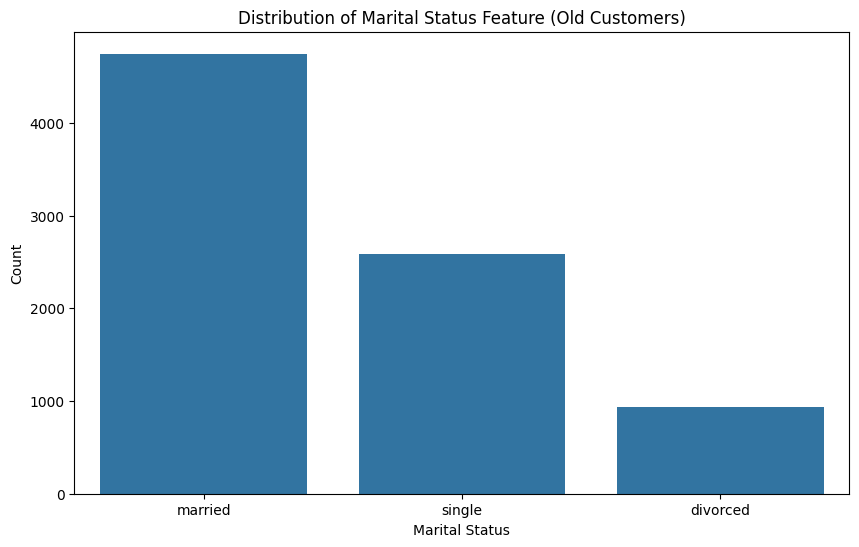

In [61]:
sns.barplot(x=marital_old_counts.index, y=marital_old_counts.values)
plt.title("Distribution of Marital Status Feature (Old Customers)")
plt.xlabel("Marital Status")
plt.ylabel("Count")
plt.show()

In [62]:
marital_new_counts = df_new["marital"].value_counts()
marital_new_counts

marital
married     22469
single      10209
divorced     4276
Name: count, dtype: int64

In [63]:
marital_new_counts / marital_new_counts.sum() * 100

marital
married     60.802619
single      27.626238
divorced    11.571143
Name: count, dtype: float64

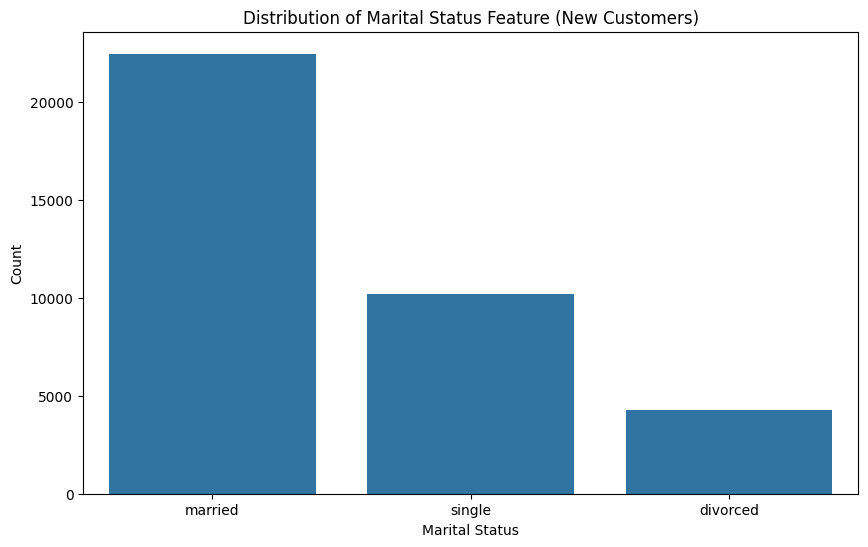

In [64]:
sns.barplot(x=marital_new_counts.index, y=marital_new_counts.values)
plt.title("Distribution of Marital Status Feature (New Customers)")
plt.xlabel("Marital Status")
plt.ylabel("Count")
plt.show()

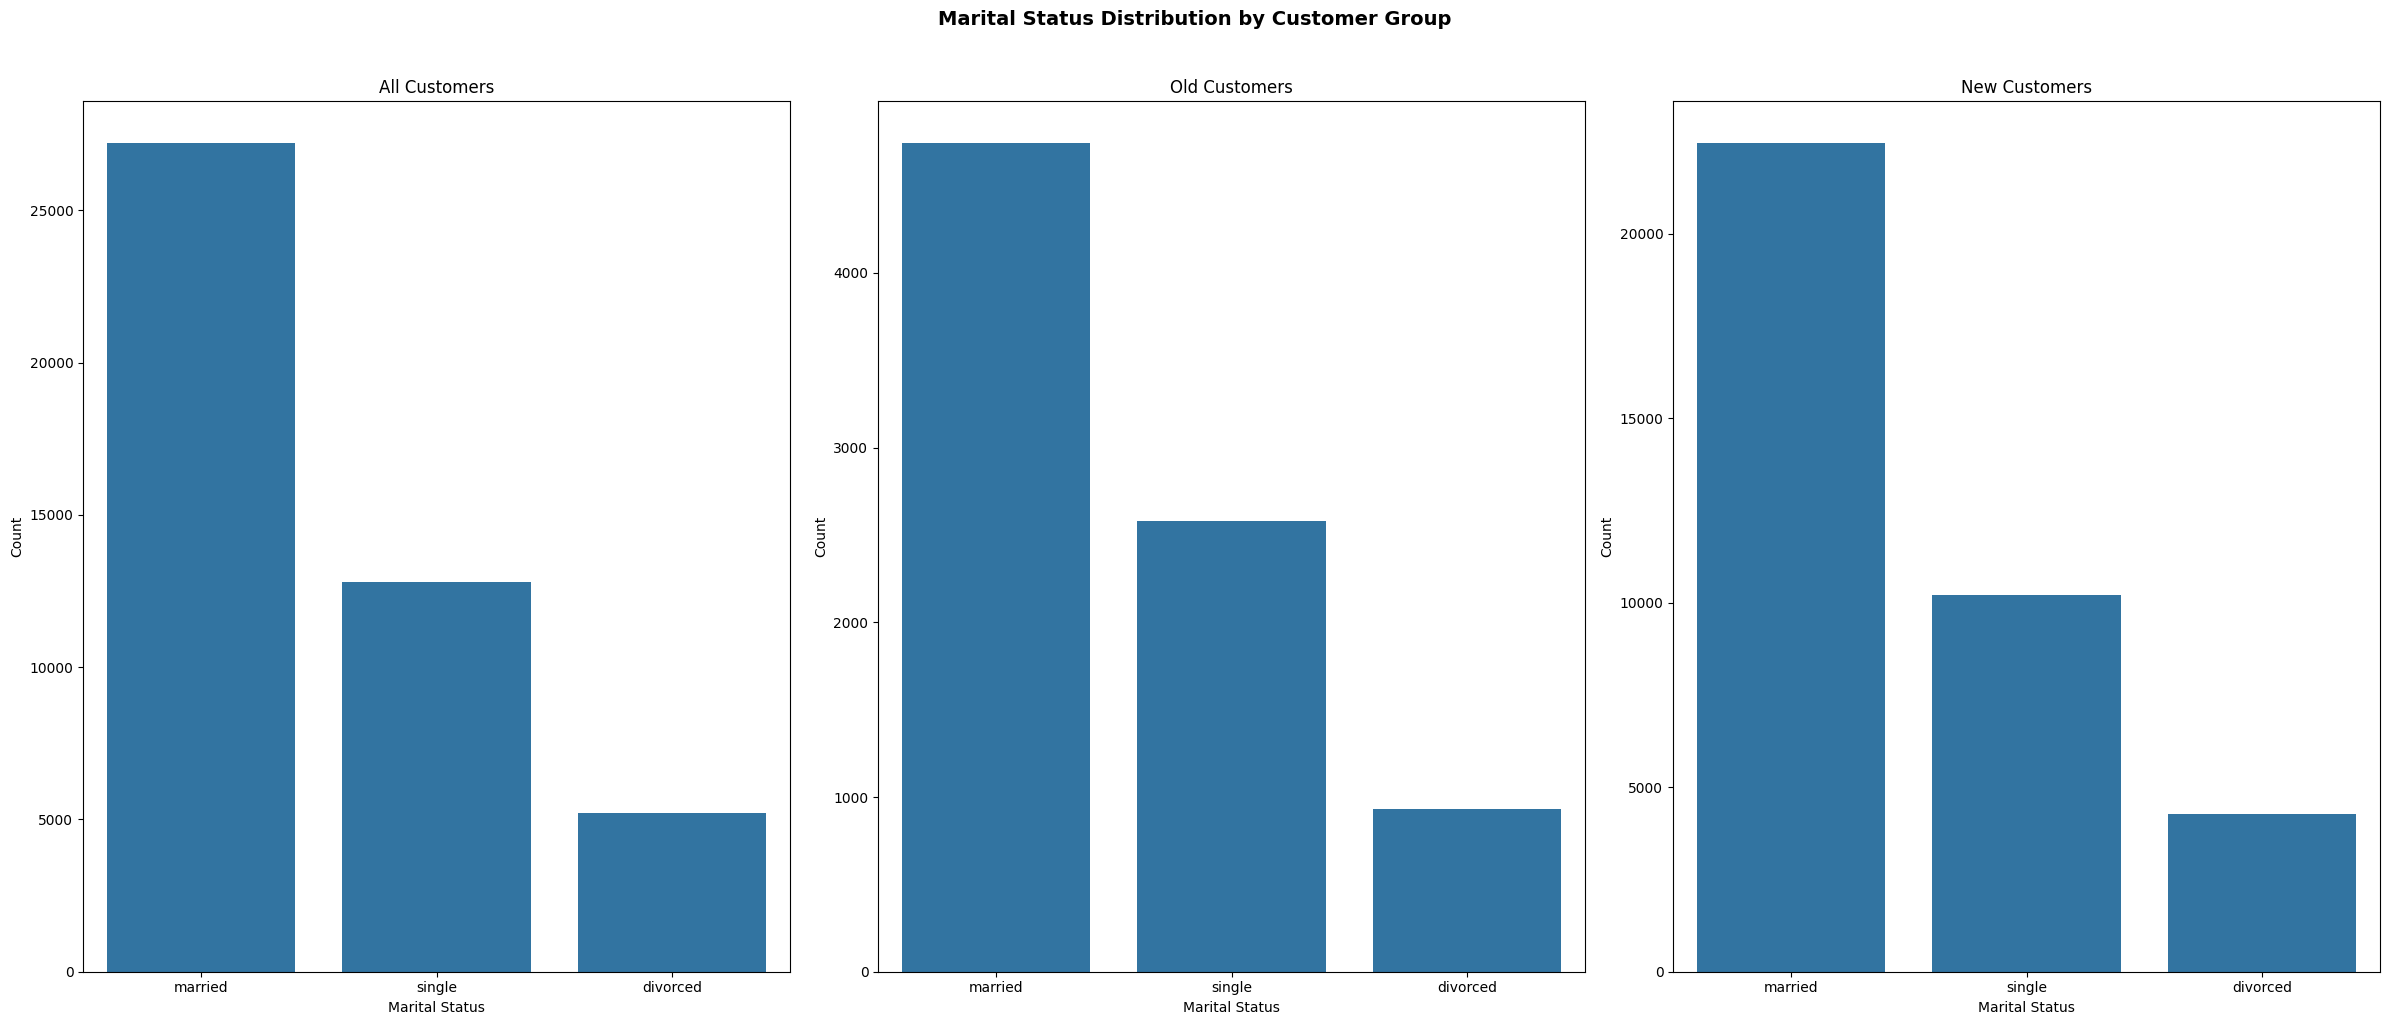

In [65]:
fig, axes = plt.subplots(1, 3, figsize=(24, 10))

for ax, (data, title) in zip(
    axes,
    [
        (marital_counts, "All Customers"),
        (marital_old_counts, "Old Customers"),
        (marital_new_counts, "New Customers"),
    ],
):
    sns.barplot(x=data.index, y=data.values, ax=ax)
    ax.set_title(f"{title}")
    ax.set_xlabel("Marital Status")
    ax.set_ylabel("Count")

plt.suptitle(
    "Marital Status Distribution by Customer Group",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

Distribution have stayed similar for this feature

##### education

In [66]:
education_counts = df["education"].value_counts()
education_counts

education
secondary    23202
tertiary     13301
primary       6851
unknown       1857
Name: count, dtype: int64

In [67]:
education_counts / education_counts.sum() * 100

education
secondary    51.319369
tertiary     29.419831
primary      15.153392
unknown       4.107407
Name: count, dtype: float64

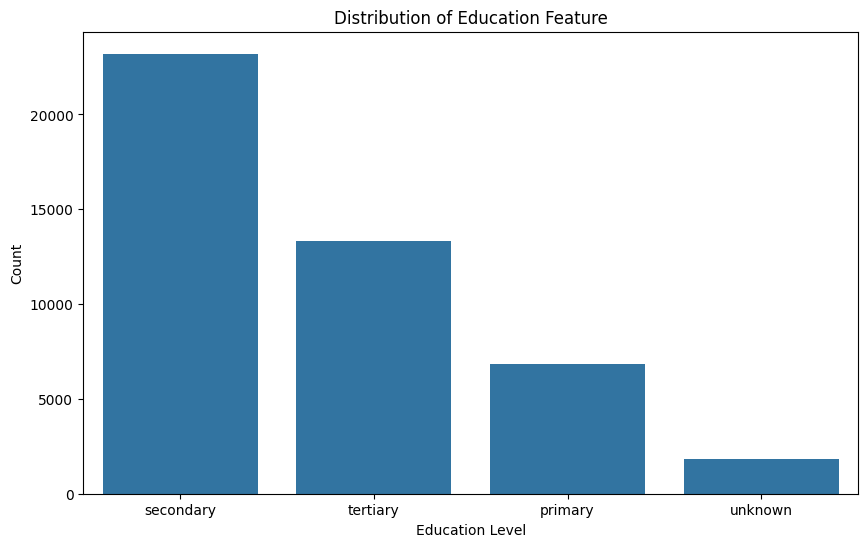

In [68]:
sns.barplot(x=education_counts.index, y=education_counts.values)
plt.title("Distribution of Education Feature")
plt.xlabel("Education Level")
plt.ylabel("Count")
plt.show()

Again, there is nothing strong to assume about financial situation of people based on their education level, even though it can be checked whether people who have tertiary education is more likely to have more stable income or not and consequently, more likely to deposit

In [69]:
education_old_counts = df_old["education"].value_counts()
education_old_counts

education
secondary    4254
tertiary     2660
primary      1020
unknown       323
Name: count, dtype: int64

In [70]:
education_old_counts / education_old_counts.sum() * 100

education
secondary    51.519922
tertiary     32.215090
primary      12.353155
unknown       3.911832
Name: count, dtype: float64

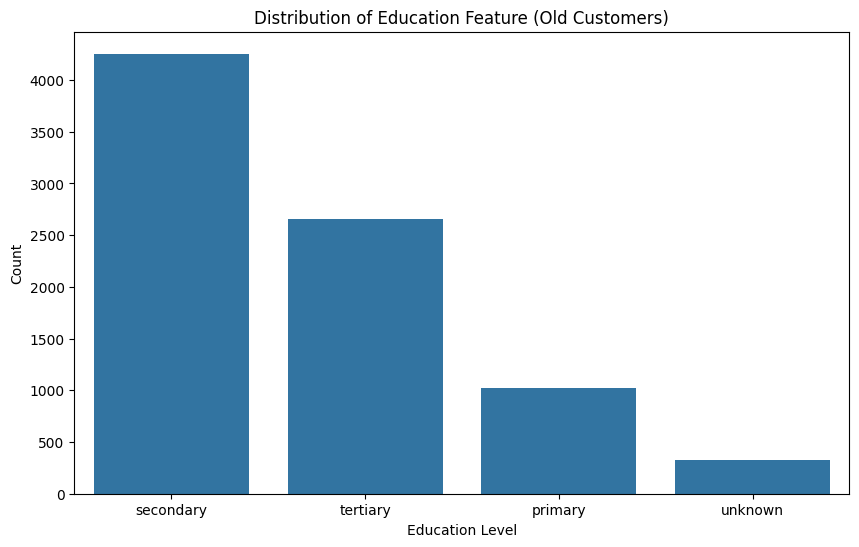

In [71]:
sns.barplot(x=education_old_counts.index, y=education_old_counts.values)
plt.title("Distribution of Education Feature (Old Customers)")
plt.xlabel("Education Level")
plt.ylabel("Count")
plt.show()

In [72]:
education_new_counts = df_new["education"].value_counts()
education_new_counts

education
secondary    18948
tertiary     10641
primary       5831
unknown       1534
Name: count, dtype: int64

In [73]:
education_new_counts / education_new_counts.sum() * 100

education
secondary    51.274558
tertiary     28.795259
primary      15.779077
unknown       4.151107
Name: count, dtype: float64

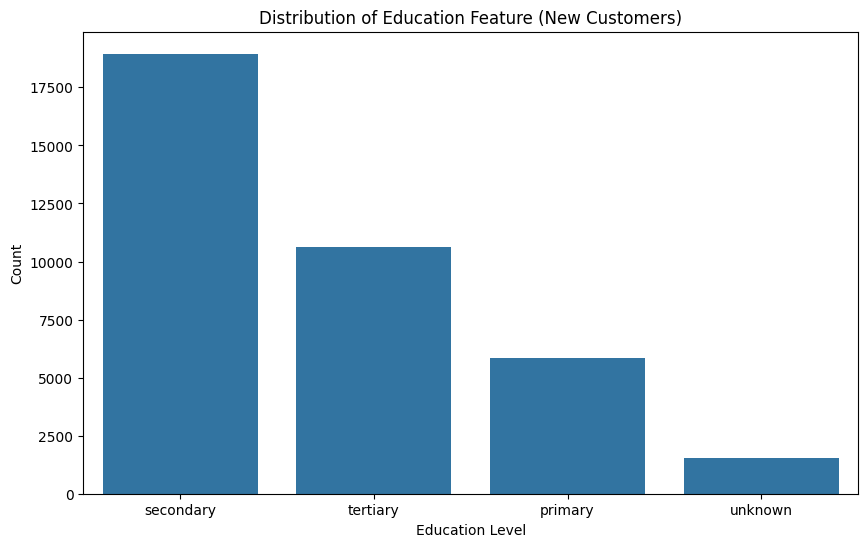

In [74]:
sns.barplot(x=education_new_counts.index, y=education_new_counts.values)
plt.title("Distribution of Education Feature (New Customers)")
plt.xlabel("Education Level")
plt.ylabel("Count")
plt.show()

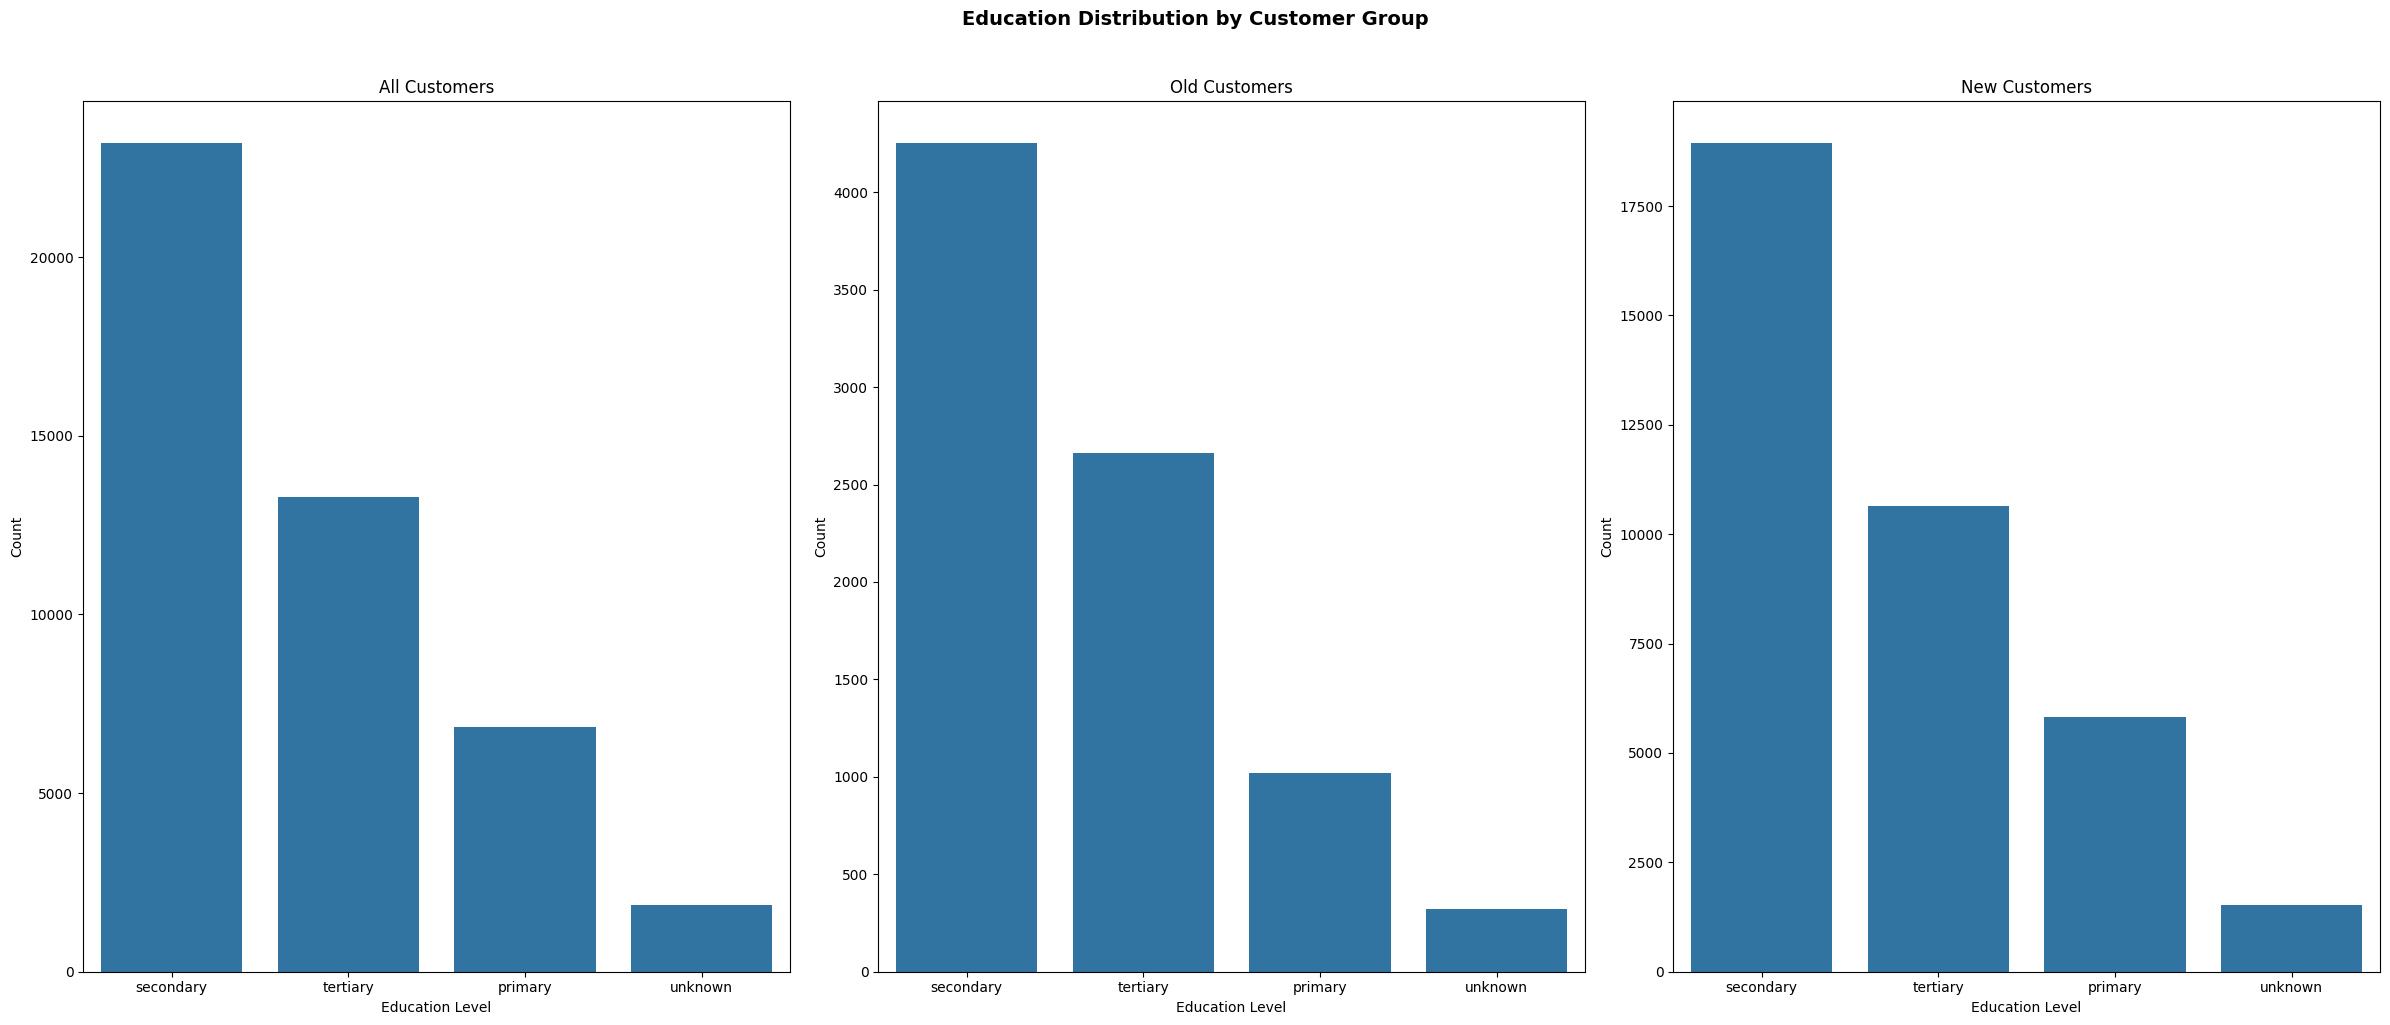

In [75]:
fig, axes = plt.subplots(1, 3, figsize=(24, 10))

for ax, (data, title) in zip(
    axes,
    [
        (education_counts, "All Customers"),
        (education_old_counts, "Old Customers"),
        (education_new_counts, "New Customers"),
    ],
):
    sns.barplot(x=data.index, y=data.values, ax=ax)
    ax.set_title(f"{title}")
    ax.set_xlabel("Education Level")
    ax.set_ylabel("Count")

plt.suptitle(
    "Education Distribution by Customer Group", fontsize=14, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

Distribution havent changed for this feature either

##### contact

In [76]:
contact_counts = df["contact"].value_counts()
contact_counts

contact
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64

In [77]:
contact_counts / contact_counts.sum() * 100

contact
cellular     64.774059
unknown      28.798301
telephone     6.427639
Name: count, dtype: float64

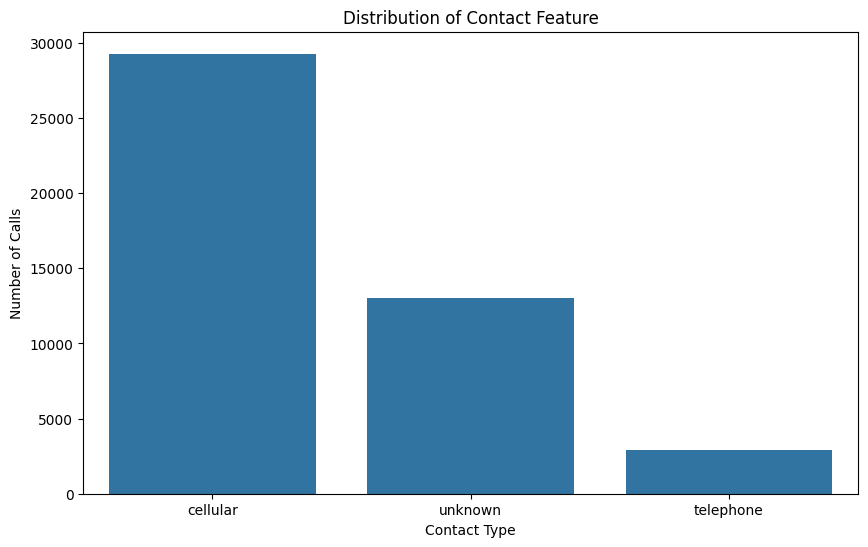

In [78]:
sns.barplot(x=contact_counts.index, y=contact_counts.values)
plt.title("Distribution of Contact Feature")
plt.xlabel("Contact Type")
plt.ylabel("Number of Calls")
plt.show()

There are lots of entries in unknown contact type which potentially makes this feature less reliable

In [79]:
contact_old_counts = df_old["contact"].value_counts()
contact_old_counts

contact
cellular     7556
telephone     631
unknown        70
Name: count, dtype: int64

In [80]:
contact_old_counts / contact_old_counts.sum() * 100

contact
cellular     91.510234
telephone     7.642001
unknown       0.847766
Name: count, dtype: float64

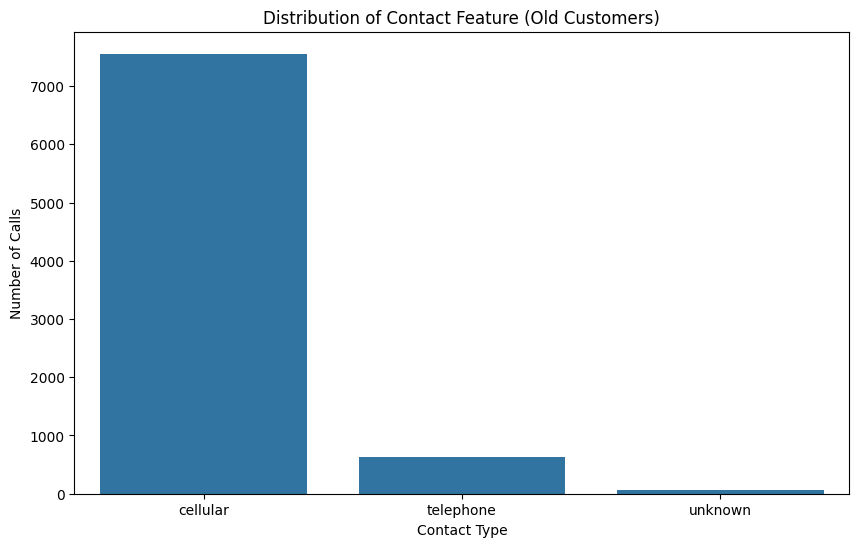

In [81]:
sns.barplot(x=contact_old_counts.index, y=contact_old_counts.values)
plt.title("Distribution of Contact Feature (Old Customers)")
plt.xlabel("Contact Type")
plt.ylabel("Number of Calls")
plt.show()

In [82]:
contact_new_counts = df_new["contact"].value_counts()
contact_new_counts

contact
cellular     21729
unknown      12950
telephone     2275
Name: count, dtype: int64

In [83]:
contact_new_counts / contact_new_counts.sum() * 100

contact
cellular     58.800130
unknown      35.043568
telephone     6.156302
Name: count, dtype: float64

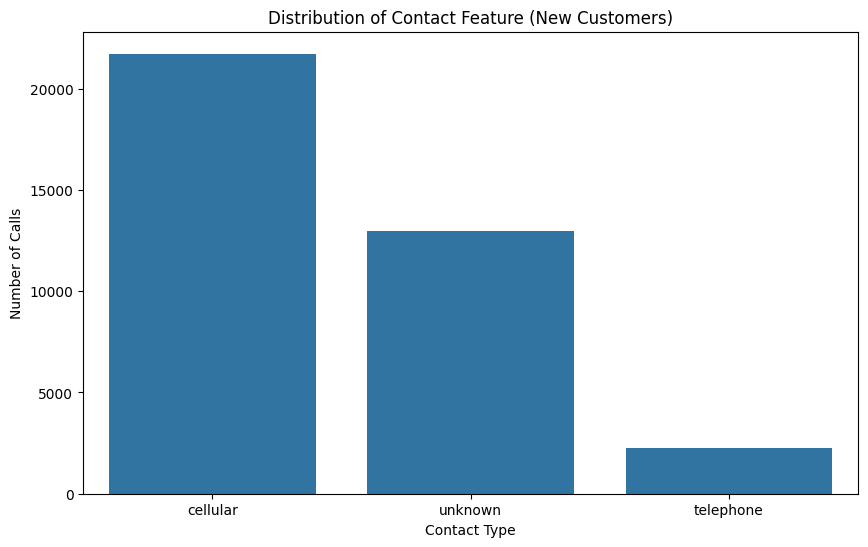

In [84]:
sns.barplot(x=contact_new_counts.index, y=contact_new_counts.values)
plt.title("Distribution of Contact Feature (New Customers)")
plt.xlabel("Contact Type")
plt.ylabel("Number of Calls")
plt.show()

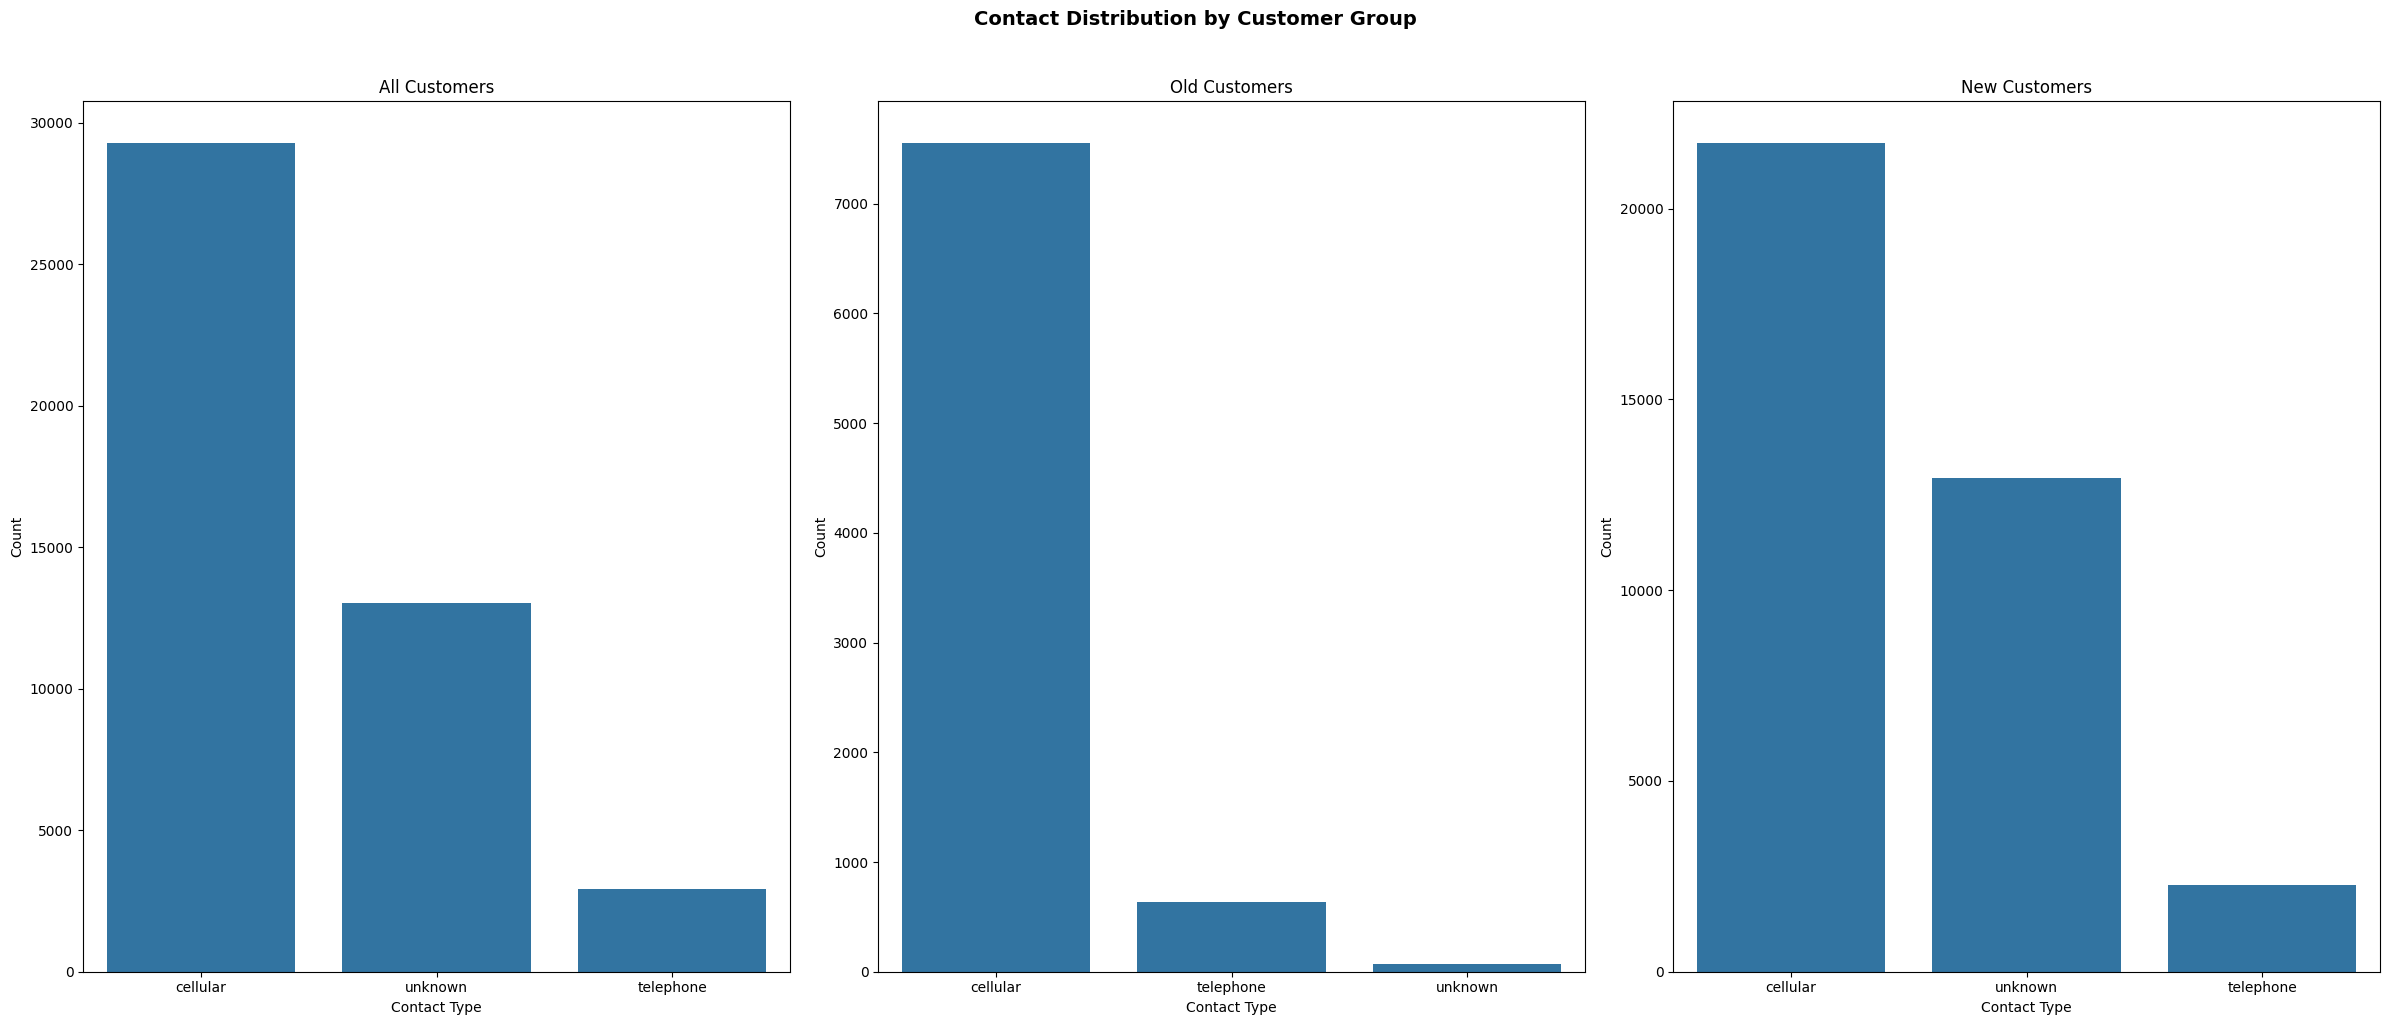

In [85]:
fig, axes = plt.subplots(1, 3, figsize=(24, 10))

for ax, (data, title) in zip(
    axes,
    [
        (contact_counts, "All Customers"),
        (contact_old_counts, "Old Customers"),
        (contact_new_counts, "New Customers"),
    ],
):
    sns.barplot(x=data.index, y=data.values, ax=ax)
    ax.set_title(f"{title}")
    ax.set_xlabel("Contact Type")
    ax.set_ylabel("Count")

plt.suptitle(
    "Contact Distribution by Customer Group", fontsize=14, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

There are so few elements for unknown type for old customers. Maybe we'll need to impute this values.

##### month

In [86]:
month_counts = df["month"].value_counts()
month_counts

month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403
oct      738
sep      579
mar      477
dec      214
Name: count, dtype: int64

In [87]:
month_counts / month_counts.sum() * 100

month
may    30.448342
jul    15.250713
aug    13.817434
jun    11.813497
nov     8.781049
apr     6.485147
feb     5.859194
jan     3.103227
oct     1.632346
sep     1.280662
mar     1.055053
dec     0.473336
Name: count, dtype: float64

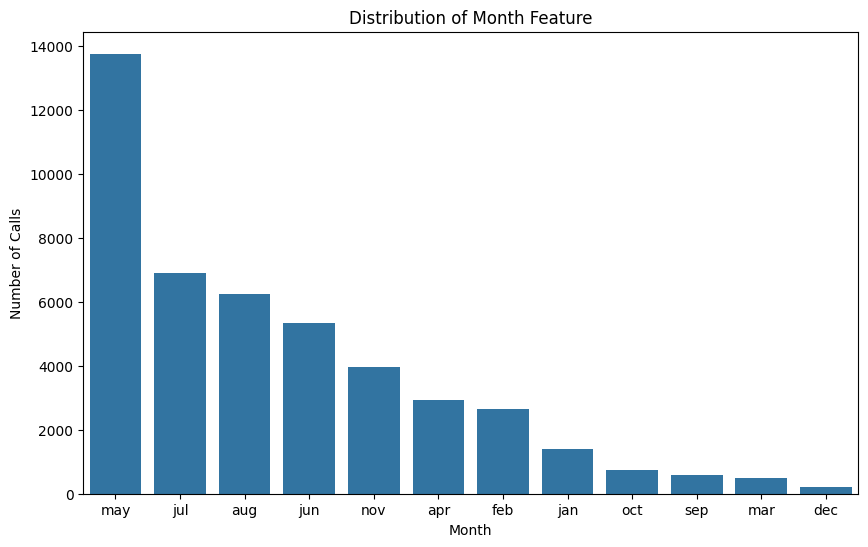

In [88]:
sns.barplot(x=month_counts.index, y=month_counts.values)
plt.title("Distribution of Month Feature")
plt.xlabel("Month")
plt.ylabel("Number of Calls")
plt.show()

In [89]:
month_old_counts = df_old["month"].value_counts()
month_old_counts

month
may    2514
nov    1150
apr    1118
feb     924
aug     531
jan     498
oct     342
jun     322
sep     313
jul     254
mar     173
dec     118
Name: count, dtype: int64

In [90]:
month_old_counts / month_old_counts.sum() * 100

month
may    30.446894
nov    13.927577
apr    13.540027
feb    11.190505
aug     6.430907
jan     6.031246
oct     4.141940
jun     3.899721
sep     3.790723
jul     3.076178
mar     2.095192
dec     1.429090
Name: count, dtype: float64

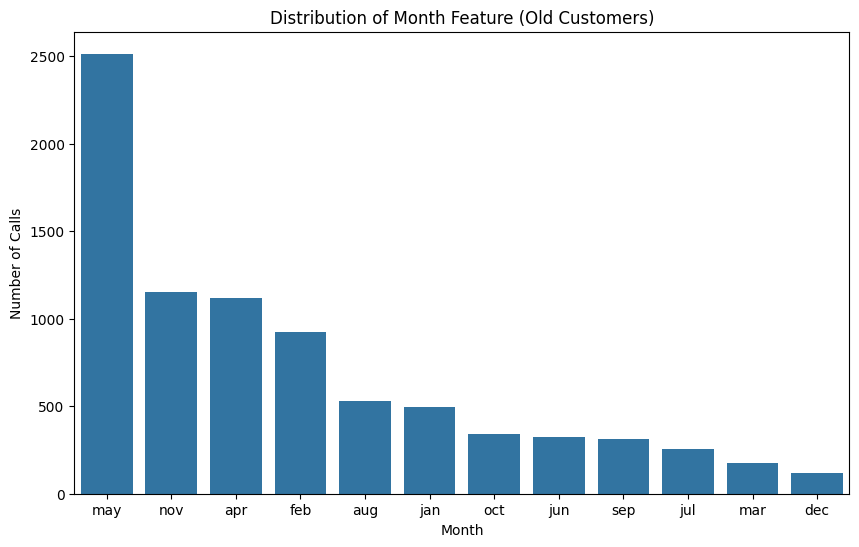

In [91]:
sns.barplot(x=month_old_counts.index, y=month_old_counts.values)
plt.title("Distribution of Month Feature (Old Customers)")
plt.xlabel("Month")
plt.ylabel("Number of Calls")
plt.show()

In [92]:
month_new_counts = df_new["month"].value_counts()
month_new_counts

month
may    11252
jul     6641
aug     5716
jun     5019
nov     2820
apr     1814
feb     1725
jan      905
oct      396
mar      304
sep      266
dec       96
Name: count, dtype: int64

In [93]:
month_new_counts / month_new_counts.sum() * 100

month
may    30.448666
jul    17.970991
aug    15.467879
jun    13.581750
nov     7.631109
apr     4.908806
feb     4.667966
jan     2.448991
oct     1.071603
mar     0.822644
sep     0.719814
dec     0.259782
Name: count, dtype: float64

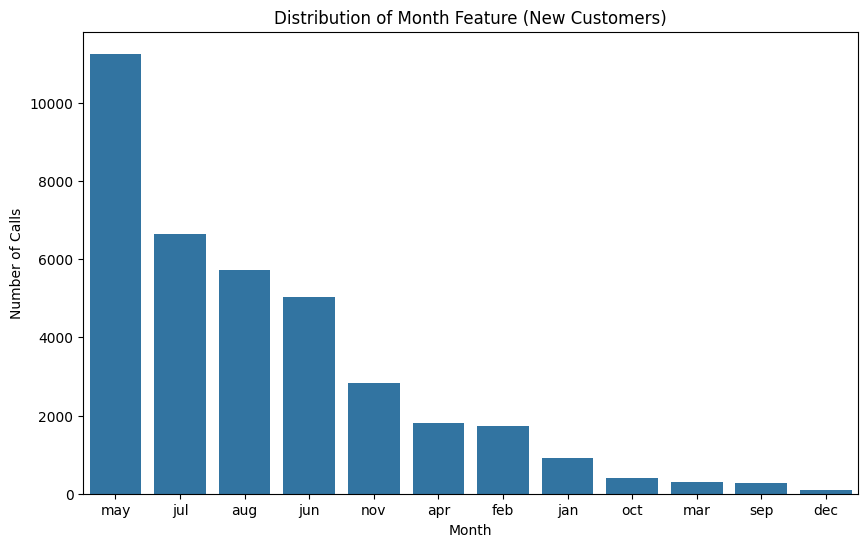

In [94]:
sns.barplot(x=month_new_counts.index, y=month_new_counts.values)
plt.title("Distribution of Month Feature (New Customers)")
plt.xlabel("Month")
plt.ylabel("Number of Calls")
plt.show()

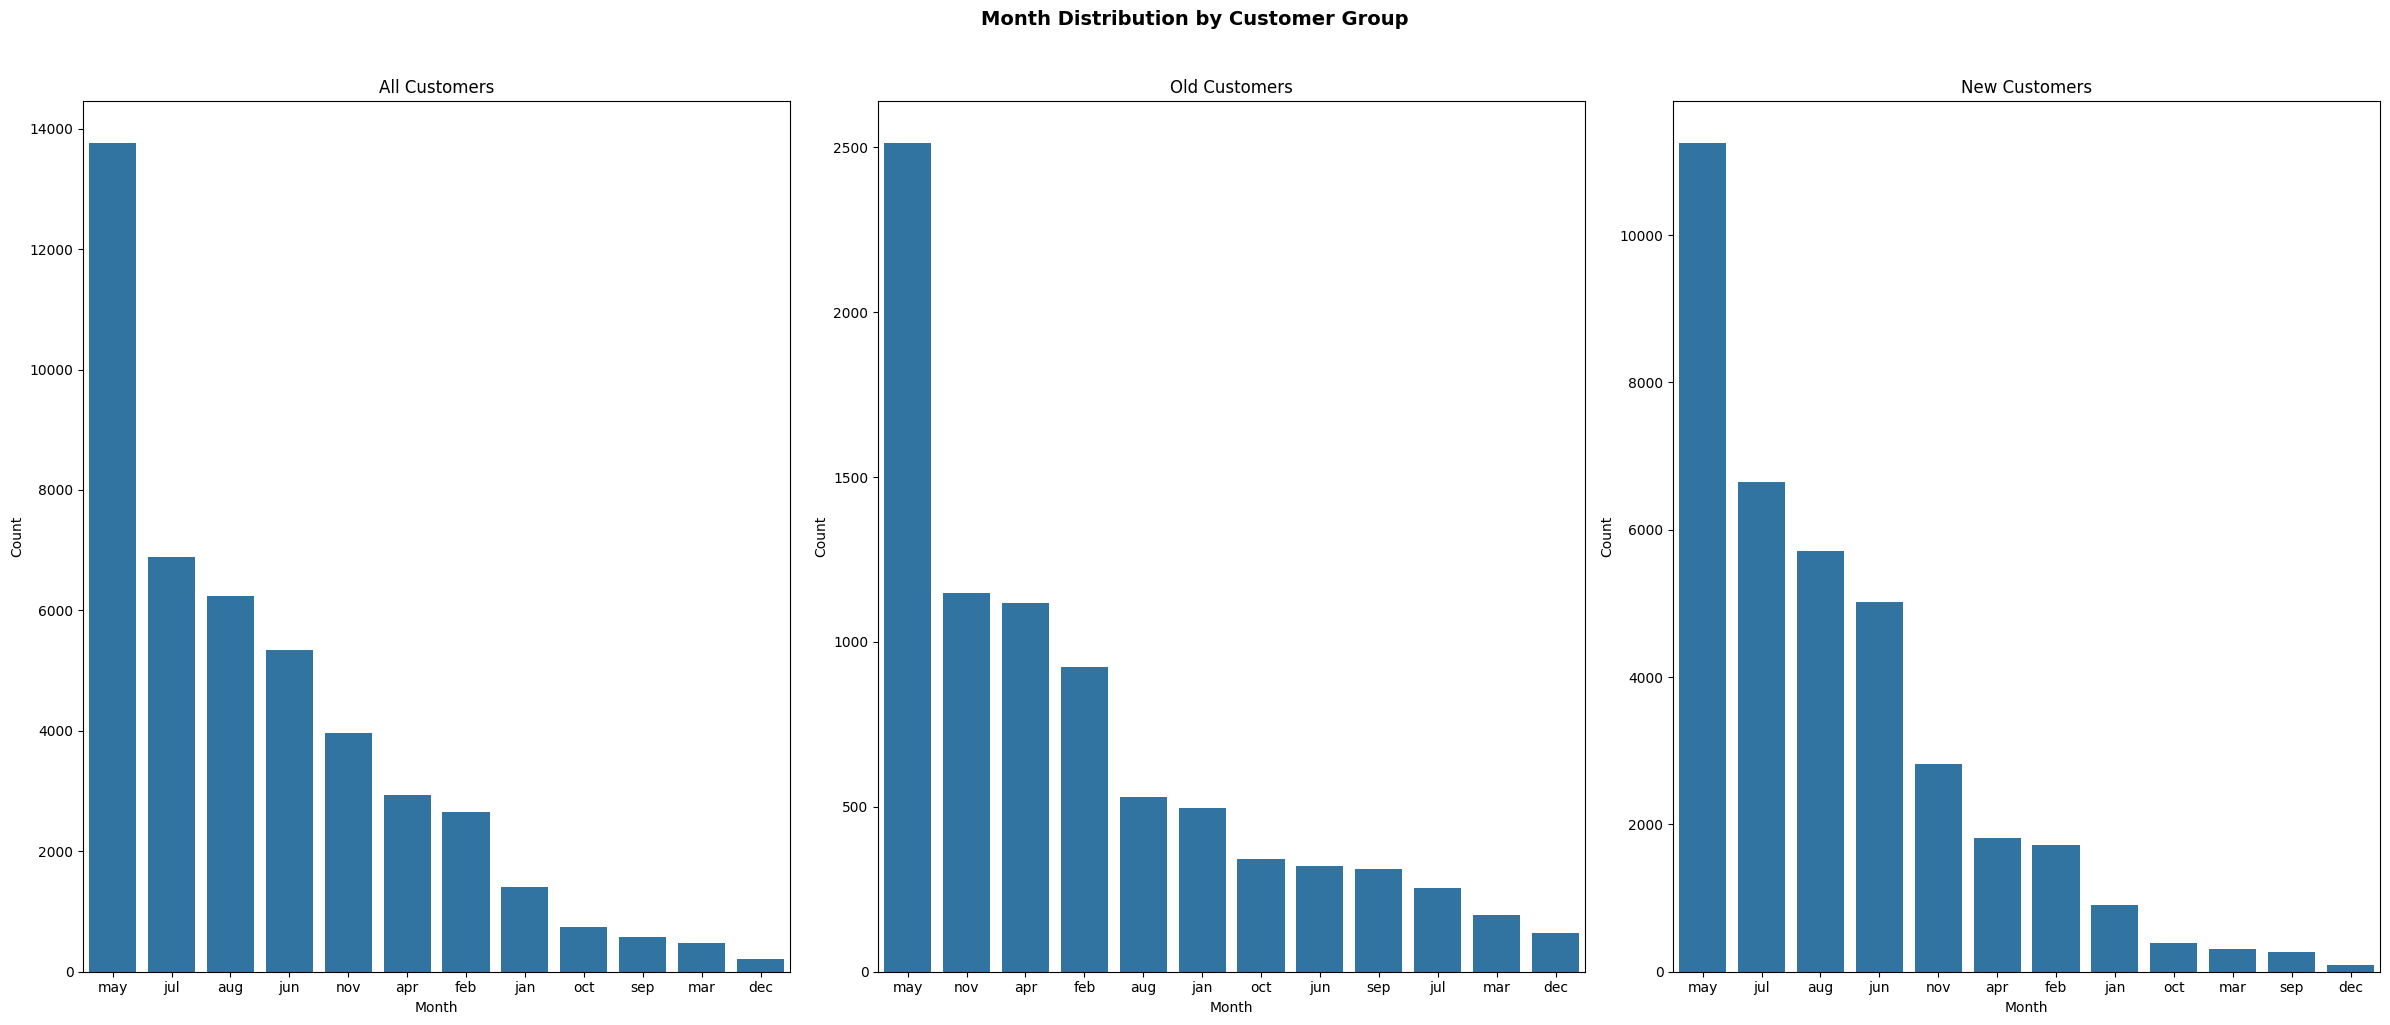

In [95]:
fig, axes = plt.subplots(1, 3, figsize=(24, 10))

for ax, (data, title) in zip(
    axes,
    [
        (month_counts, "All Customers"),
        (month_old_counts, "Old Customers"),
        (month_new_counts, "New Customers"),
    ],
):
    sns.barplot(x=data.index, y=data.values, ax=ax)
    ax.set_title(f"{title}")
    ax.set_xlabel("Month")
    ax.set_ylabel("Count")

plt.suptitle(
    "Month Distribution by Customer Group", fontsize=14, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

##### poutcome

In [96]:
poutcome_counts = df["poutcome"].value_counts()
poutcome_counts

poutcome
unknown    36959
failure     4901
other       1840
success     1511
Name: count, dtype: int64

In [97]:
poutcome_counts / poutcome_counts.sum() * 100

poutcome
unknown    81.747805
failure    10.840282
other       4.069806
success     3.342107
Name: count, dtype: float64

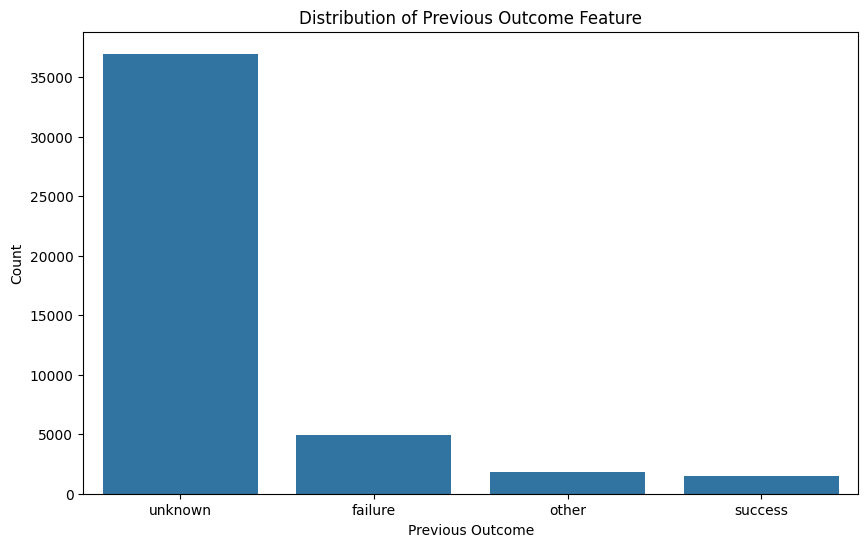

In [98]:
sns.barplot(x=poutcome_counts.index, y=poutcome_counts.values)
plt.title("Distribution of Previous Outcome Feature")
plt.xlabel("Previous Outcome")
plt.ylabel("Count")
plt.show()

In [99]:
poutcome_old_counts = df_old["poutcome"].value_counts()
poutcome_old_counts

poutcome
failure    4901
other      1840
success    1511
unknown       5
Name: count, dtype: int64

It does make sense to merge unkown and other columns in this case

In [100]:
df_old["poutcome"] = df_old["poutcome"].replace("unknown", "other")
poutcome_old_counts = df_old["poutcome"].value_counts()
poutcome_old_counts

poutcome
failure    4901
other      1845
success    1511
Name: count, dtype: int64

In [101]:
poutcome_old_counts / poutcome_old_counts.sum() * 100

poutcome
failure    59.355698
other      22.344677
success    18.299625
Name: count, dtype: float64

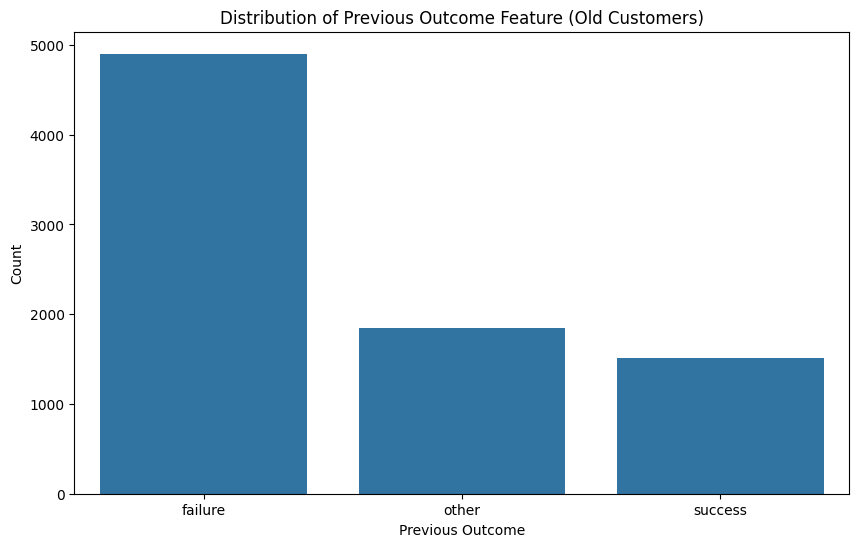

In [102]:
sns.barplot(x=poutcome_old_counts.index, y=poutcome_old_counts.values)
plt.title("Distribution of Previous Outcome Feature (Old Customers)")
plt.xlabel("Previous Outcome")
plt.ylabel("Count")
plt.show()

In [103]:
poutcome_new_counts = df_new["poutcome"].value_counts()
poutcome_new_counts

poutcome
unknown    36954
Name: count, dtype: int64

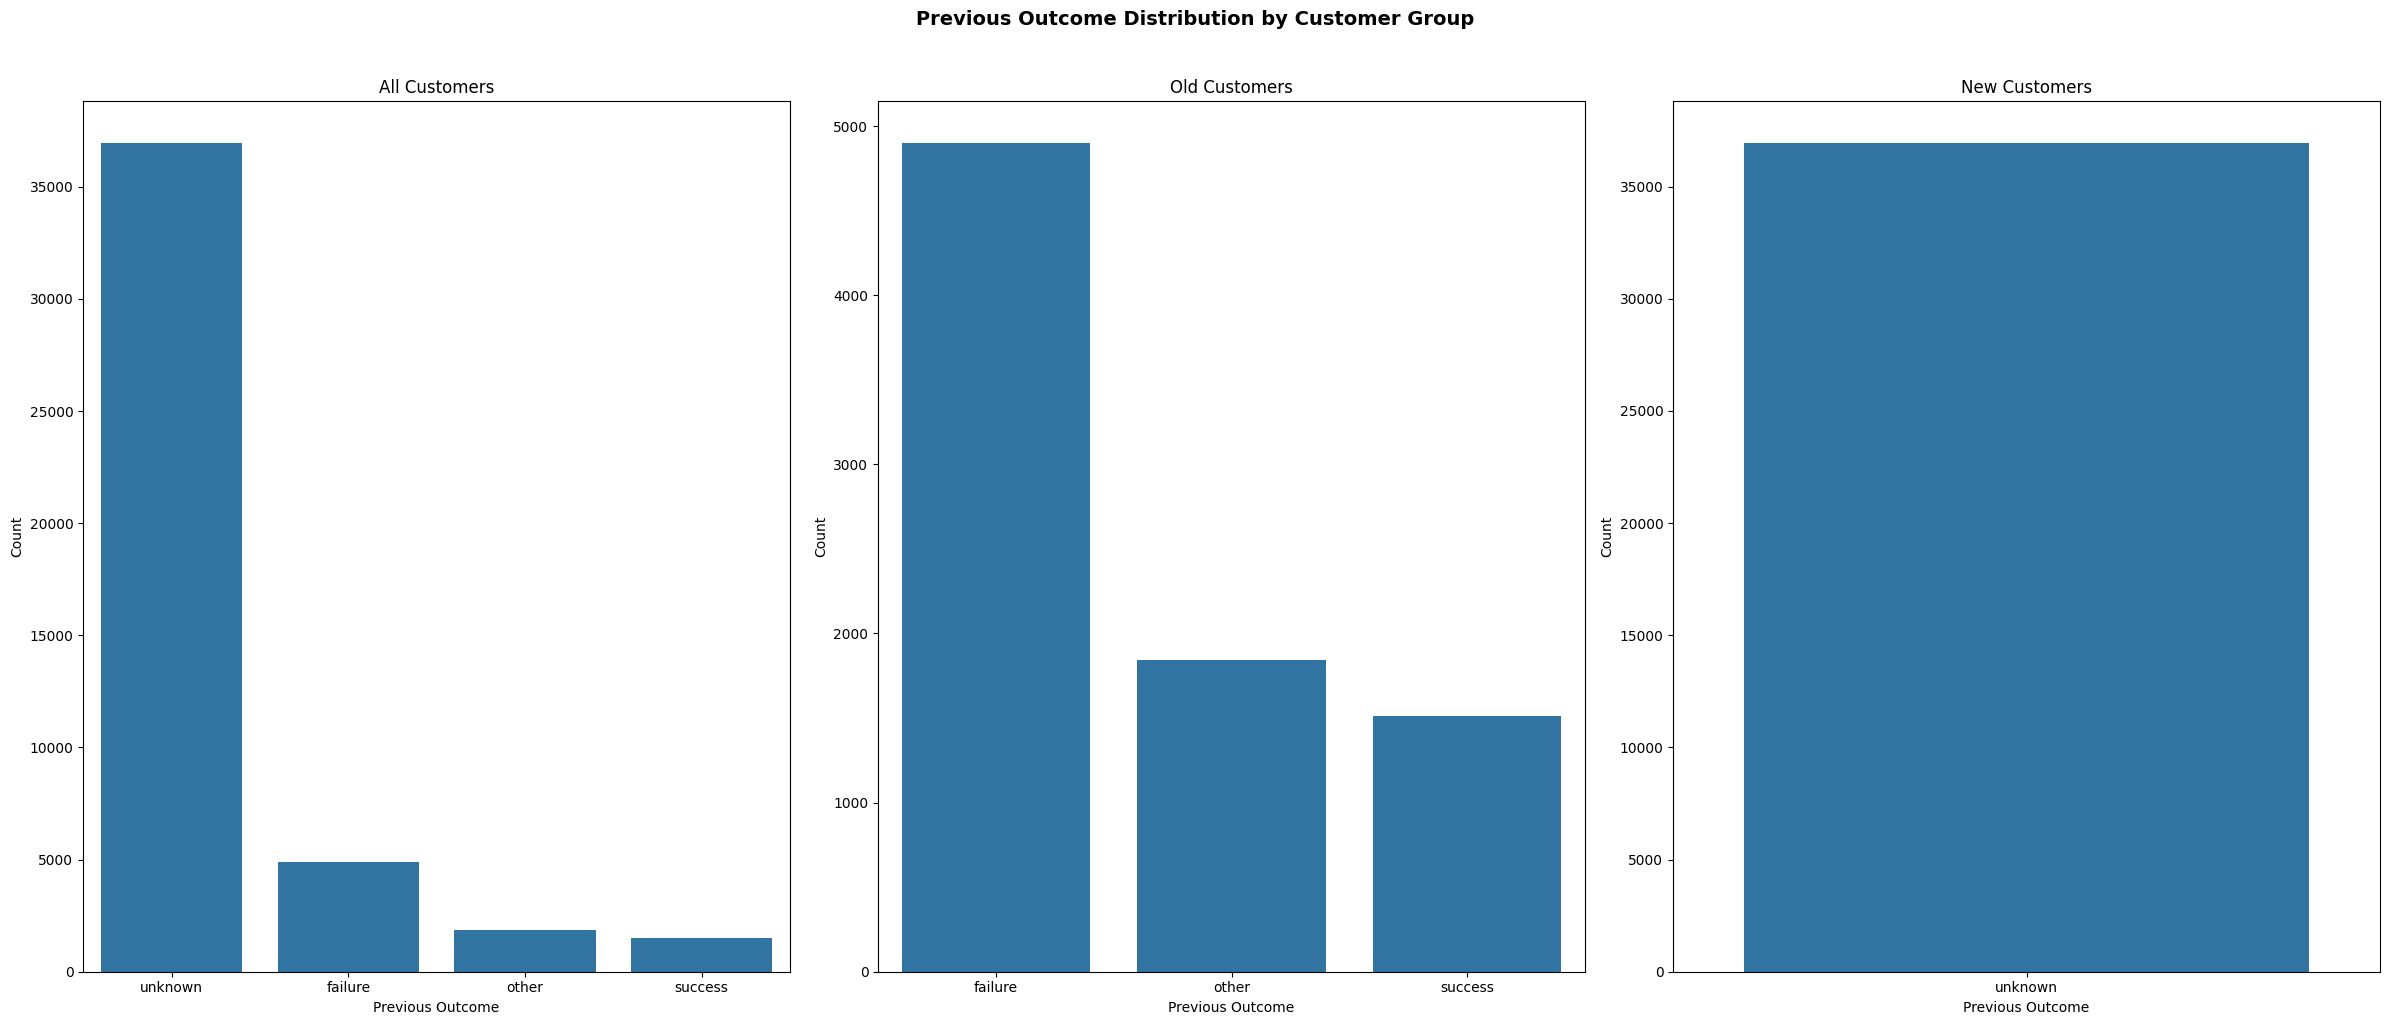

In [104]:
fig, axes = plt.subplots(1, 3, figsize=(24, 10))

for ax, (data, title) in zip(
    axes,
    [
        (poutcome_counts, "All Customers"),
        (poutcome_old_counts, "Old Customers"),
        (poutcome_new_counts, "New Customers"),
    ],
):
    sns.barplot(x=data.index, y=data.values, ax=ax)
    ax.set_title(f"{title}")
    ax.set_xlabel("Previous Outcome")
    ax.set_ylabel("Count")

plt.suptitle(
    "Previous Outcome Distribution by Customer Group",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

We need to merge unknown value into other and remove poutcome feature from new customers entirely 

#### Numerical Features

##### age

In [105]:
df["age"].nunique()

77

In [106]:
df["age"].describe()

count    45211.000000
mean        40.936210
std         10.618762
min         18.000000
25%         33.000000
50%         39.000000
75%         48.000000
max         95.000000
Name: age, dtype: float64

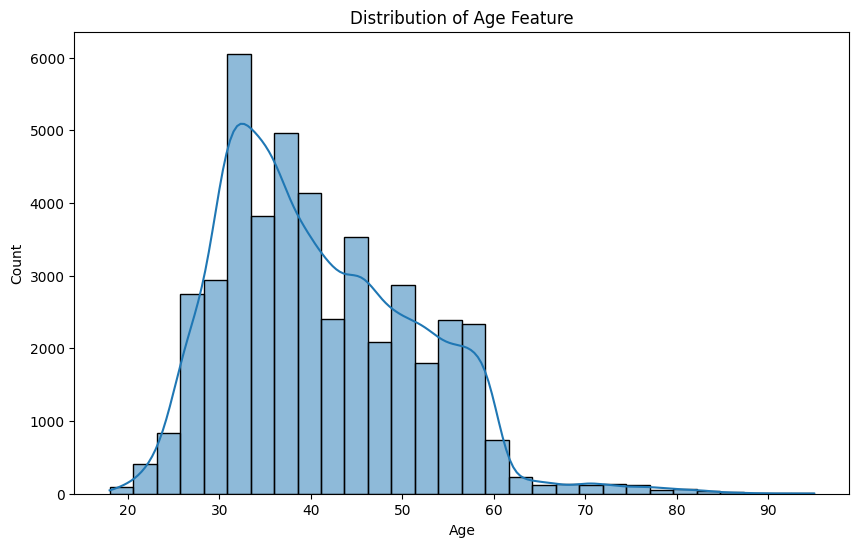

In [107]:
sns.histplot(df["age"], bins=30, kde=True)
plt.title("Distribution of Age Feature")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

The data is right-skewed and the behaviour can be seen more detailly using box plot

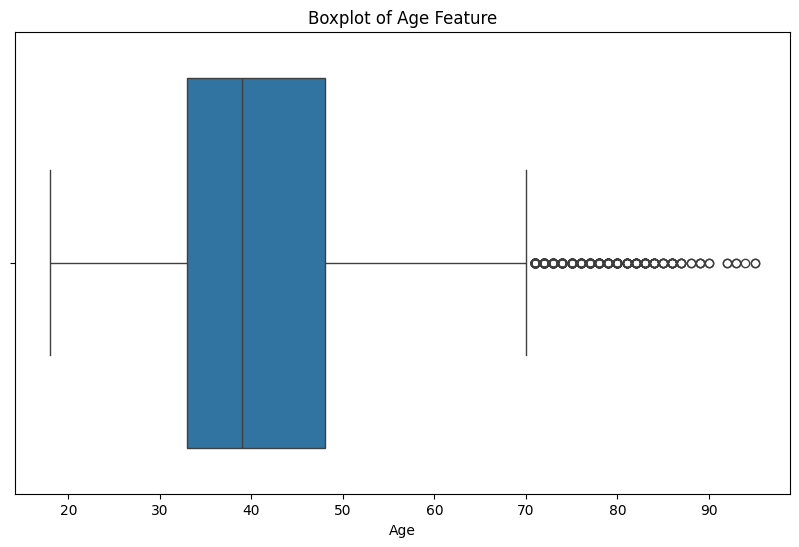

In [108]:
sns.boxplot(x=df["age"])
plt.title("Boxplot of Age Feature")
plt.xlabel("Age")
plt.show()

In [109]:
df_old["age"].nunique()

72

In [110]:
df_old["age"].describe()

count    8257.000000
mean       40.953131
std        11.425180
min        18.000000
25%        33.000000
50%        38.000000
75%        48.000000
max        93.000000
Name: age, dtype: float64

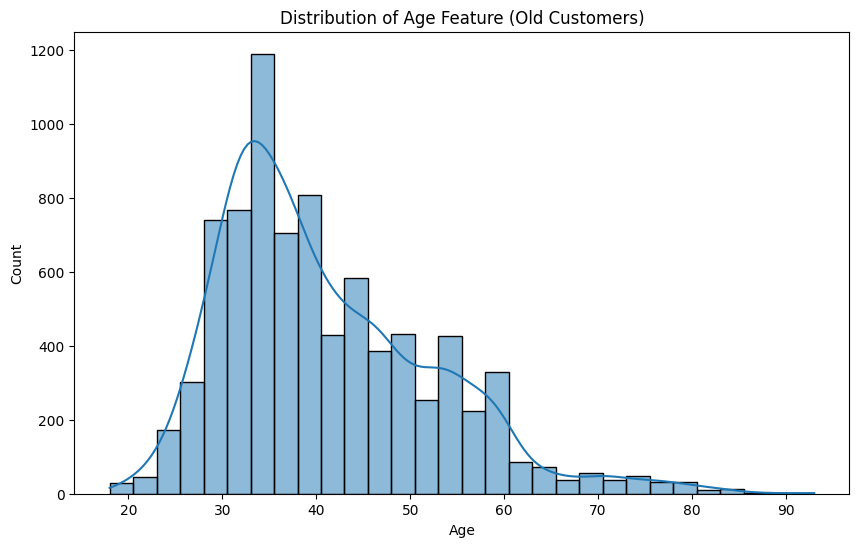

In [111]:
sns.histplot(df_old["age"], bins=30, kde=True)
plt.title("Distribution of Age Feature (Old Customers)")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

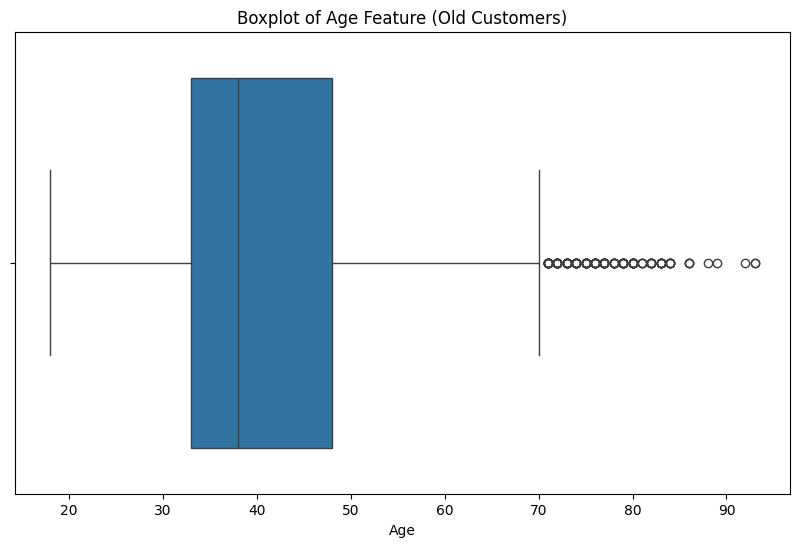

In [112]:
sns.boxplot(x=df_old["age"])
plt.title("Boxplot of Age Feature (Old Customers)")
plt.xlabel("Age")
plt.show()

In [113]:
df_new["age"].nunique()

76

In [114]:
df_new["age"].describe()

count    36954.000000
mean        40.932430
std         10.430218
min         18.000000
25%         33.000000
50%         39.000000
75%         49.000000
max         95.000000
Name: age, dtype: float64

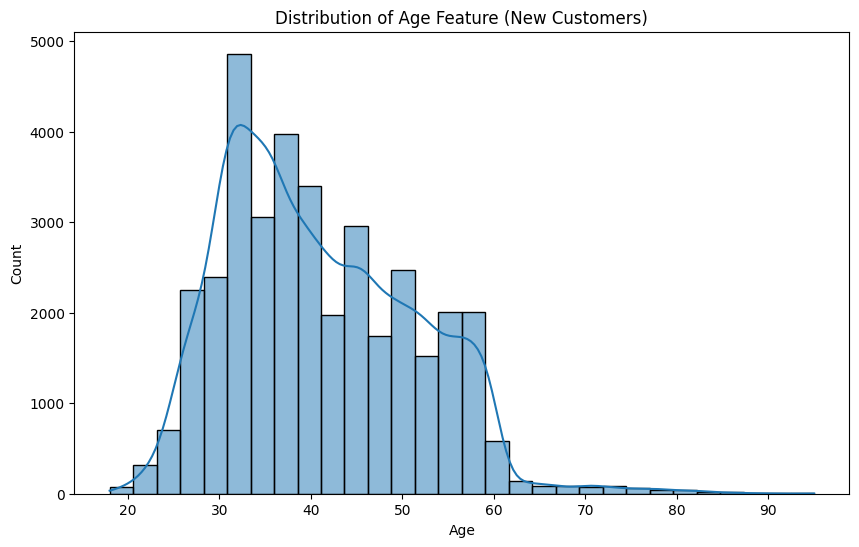

In [115]:
sns.histplot(df_new["age"], bins=30, kde=True)
plt.title("Distribution of Age Feature (New Customers)")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

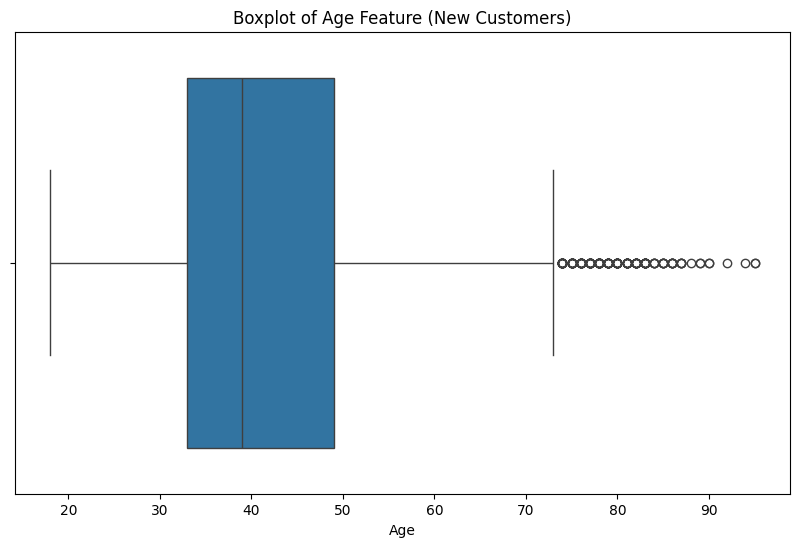

In [116]:
sns.boxplot(x=df_new["age"])
plt.title("Boxplot of Age Feature (New Customers)")
plt.xlabel("Age")
plt.show()

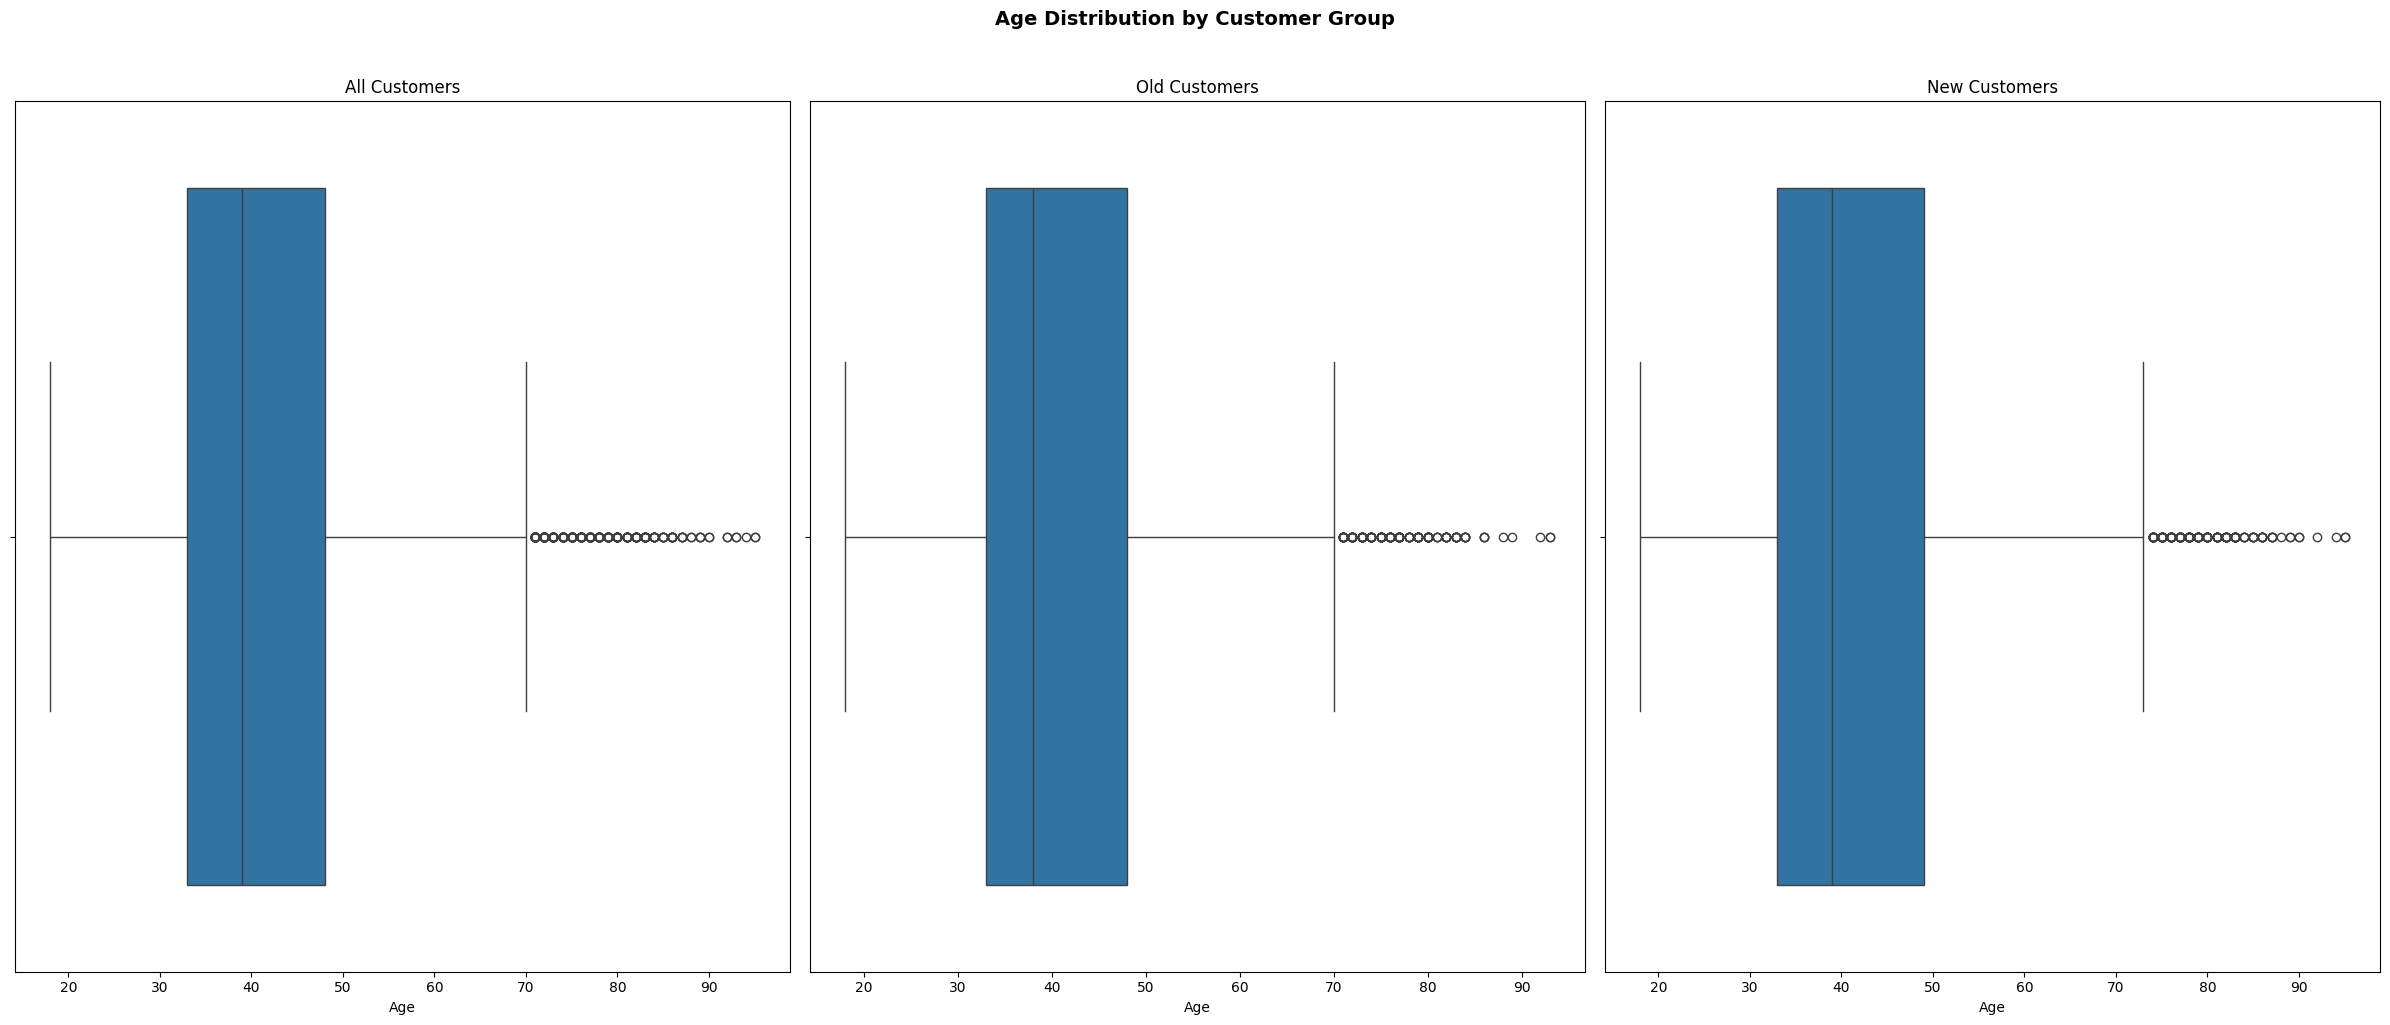

In [117]:
fig, axes = plt.subplots(1, 3, figsize=(24, 10))

for ax, (data, title) in zip(
    axes,
    [
        (df["age"], "All Customers"),
        (df_old["age"], "Old Customers"),
        (df_new["age"], "New Customers"),
    ],
):
    sns.boxplot(x=data, ax=ax)
    ax.set_title(f"{title}")
    ax.set_xlabel("Age")

plt.suptitle(
    "Age Distribution by Customer Group", fontsize=14, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

Distribution is similar for all cases

##### balance

In [118]:
df["balance"].describe()

count     45211.000000
mean       1362.272058
std        3044.765829
min       -8019.000000
25%          72.000000
50%         448.000000
75%        1428.000000
max      102127.000000
Name: balance, dtype: float64

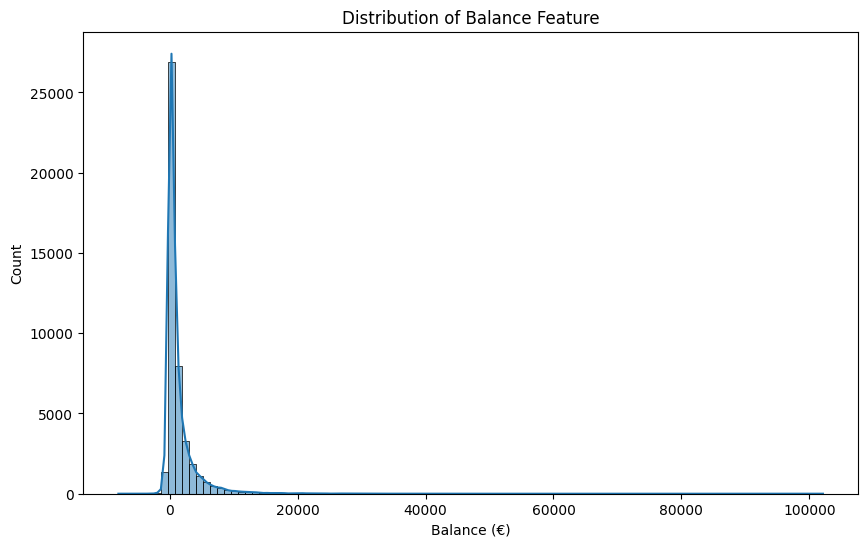

In [119]:
sns.histplot(df["balance"], bins=100, kde=True)
plt.title("Distribution of Balance Feature")
plt.xlabel("Balance (€)")
plt.ylabel("Count")
plt.show()

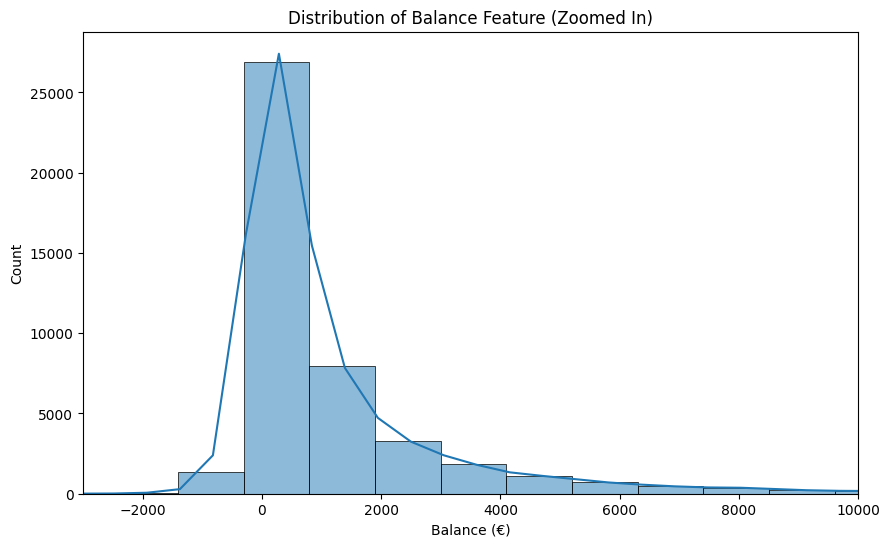

In [120]:
sns.histplot(df["balance"], bins=100, kde=True)
plt.title("Distribution of Balance Feature (Zoomed In)")
plt.xlabel("Balance (€)")
plt.ylabel("Count")
plt.xlim(-3000, 10000)
plt.show()

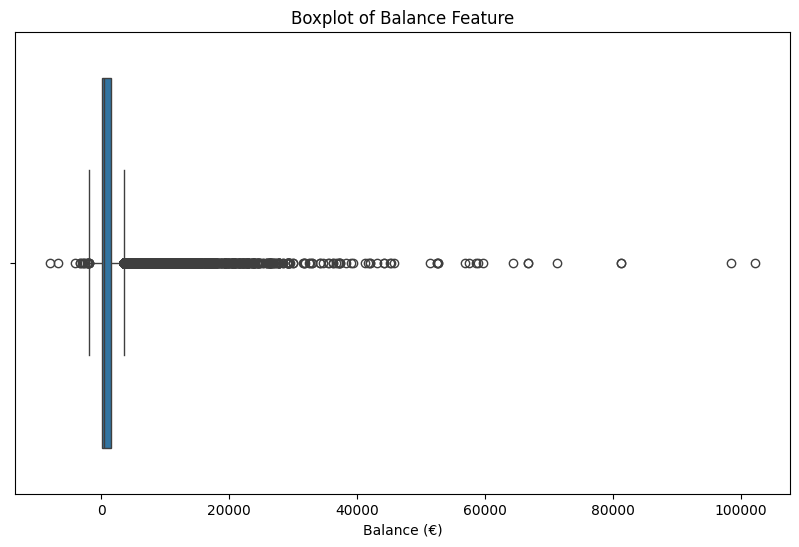

In [121]:
sns.boxplot(x=df["balance"])
plt.title("Boxplot of Balance Feature")
plt.xlabel("Balance (€)")
plt.show()

In [122]:
IQR_balance = df["balance"].quantile(0.75) - df["balance"].quantile(0.25)
lower_bound_balance = df["balance"].quantile(0.25) - 1.5 * IQR_balance
upper_bound_balance = df["balance"].quantile(0.75) + 1.5 * IQR_balance
print((lower_bound_balance, upper_bound_balance))

(np.float64(-1962.0), np.float64(3462.0))


Most values are between around -2000 and 3500 euros, which mostly explains the imbalance in our target

In [123]:
df_old["balance"].describe()

count     8257.000000
mean      1556.880102
std       3060.593186
min      -1884.000000
25%        168.000000
50%        602.000000
75%       1743.000000
max      81204.000000
Name: balance, dtype: float64

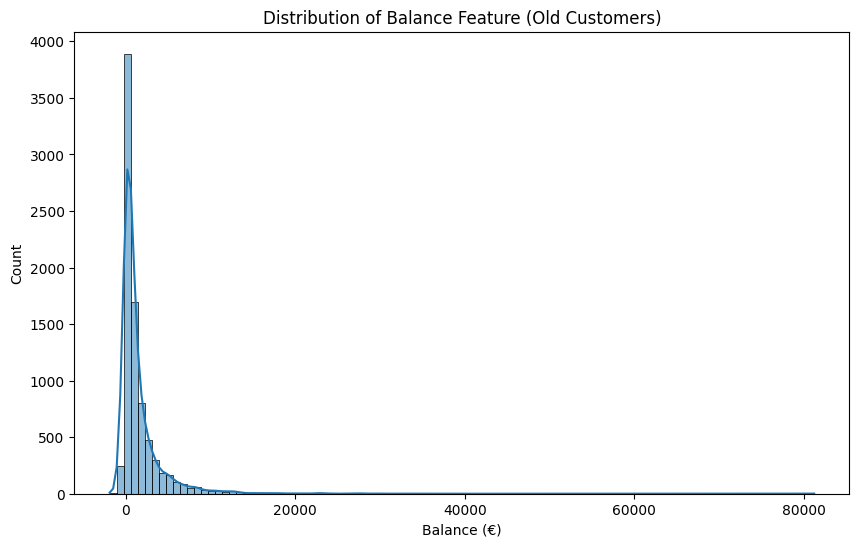

In [124]:
sns.histplot(df_old["balance"], bins=100, kde=True)
plt.title("Distribution of Balance Feature (Old Customers)")
plt.xlabel("Balance (€)")
plt.ylabel("Count")
plt.show()

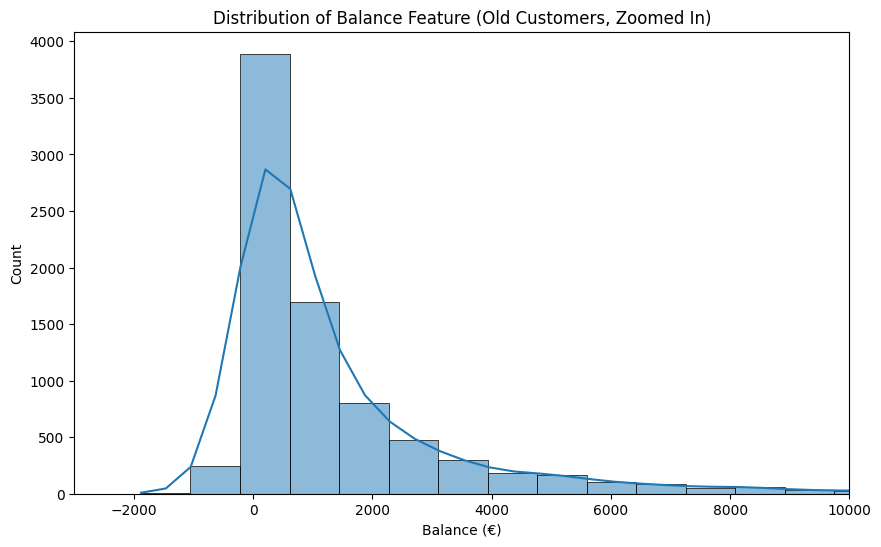

In [125]:
sns.histplot(df_old["balance"], bins=100, kde=True)
plt.title("Distribution of Balance Feature (Old Customers, Zoomed In)")
plt.xlabel("Balance (€)")
plt.ylabel("Count")
plt.xlim(-3000, 10000)
plt.show()

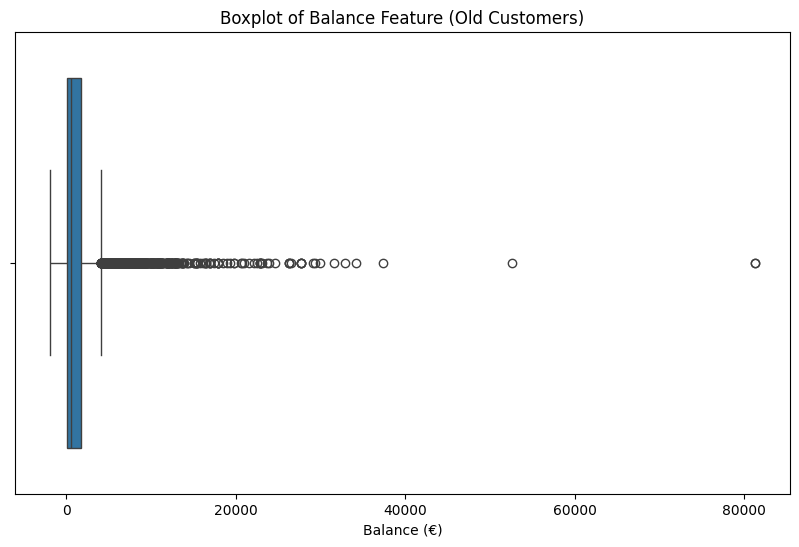

In [126]:
sns.boxplot(x=df_old["balance"])
plt.title("Boxplot of Balance Feature (Old Customers)")
plt.xlabel("Balance (€)")
plt.show()

In [127]:
df_new["balance"].describe()

count     36954.000000
mean       1318.788846
std        3039.557077
min       -8019.000000
25%          55.000000
50%         414.000000
75%        1358.000000
max      102127.000000
Name: balance, dtype: float64

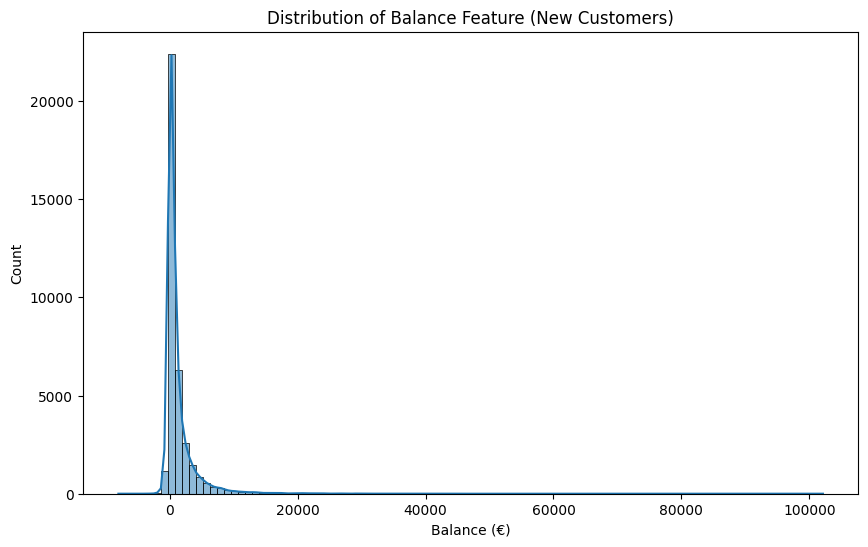

In [128]:
sns.histplot(df_new["balance"], bins=100, kde=True)
plt.title("Distribution of Balance Feature (New Customers)")
plt.xlabel("Balance (€)")
plt.ylabel("Count")
plt.show()

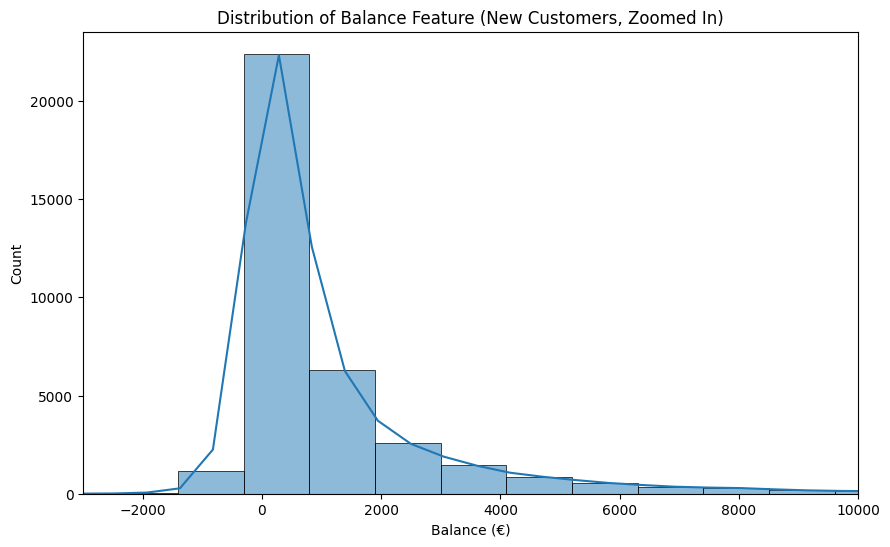

In [129]:
sns.histplot(df_new["balance"], bins=100, kde=True)
plt.title("Distribution of Balance Feature (New Customers, Zoomed In)")
plt.xlabel("Balance (€)")
plt.ylabel("Count")
plt.xlim(-3000, 10000)
plt.show()

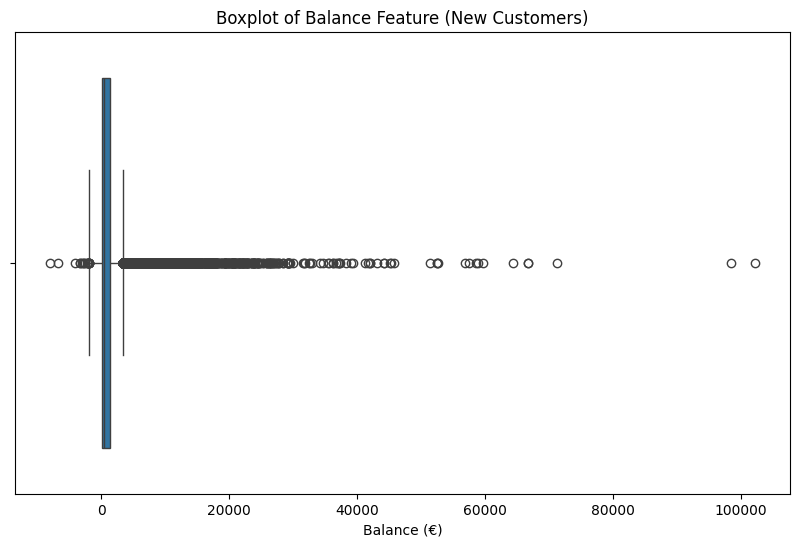

In [130]:
sns.boxplot(x=df_new["balance"])
plt.title("Boxplot of Balance Feature (New Customers)")
plt.xlabel("Balance (€)")
plt.show()

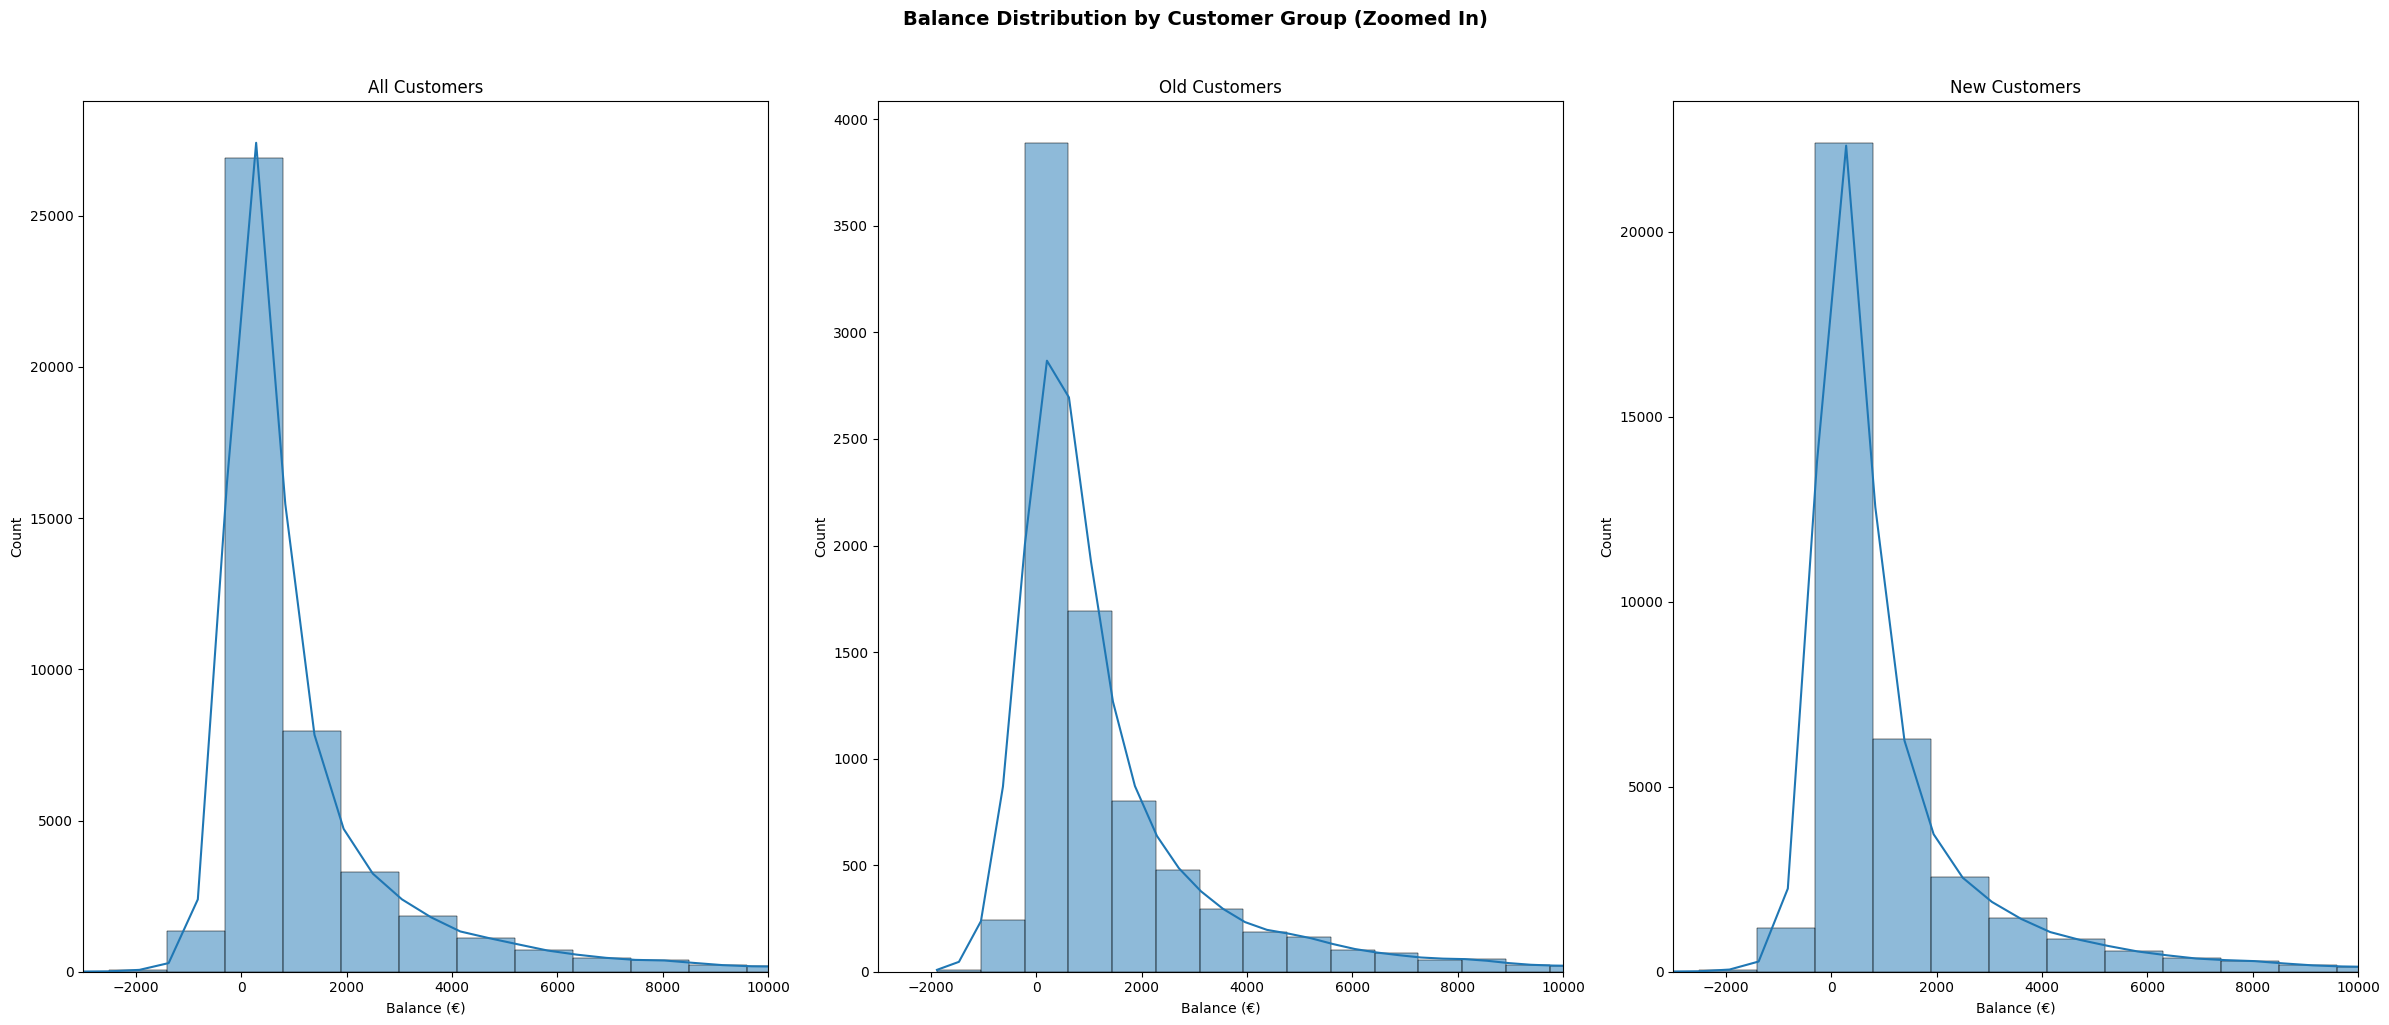

In [131]:
fig, axes = plt.subplots(1, 3, figsize=(24, 10))

for ax, (data, title) in zip(
    axes,
    [
        (df["balance"], "All Customers"),
        (df_old["balance"], "Old Customers"),
        (df_new["balance"], "New Customers"),
    ],
):
    sns.histplot(x=data, ax=ax, bins=100, kde=True)
    ax.set_title(f"{title}")
    ax.set_xlabel("Balance (€)")
    ax.set_ylabel("Count")
    ax.set_xlim(-3000, 10000)

plt.suptitle(
    "Balance Distribution by Customer Group (Zoomed In)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

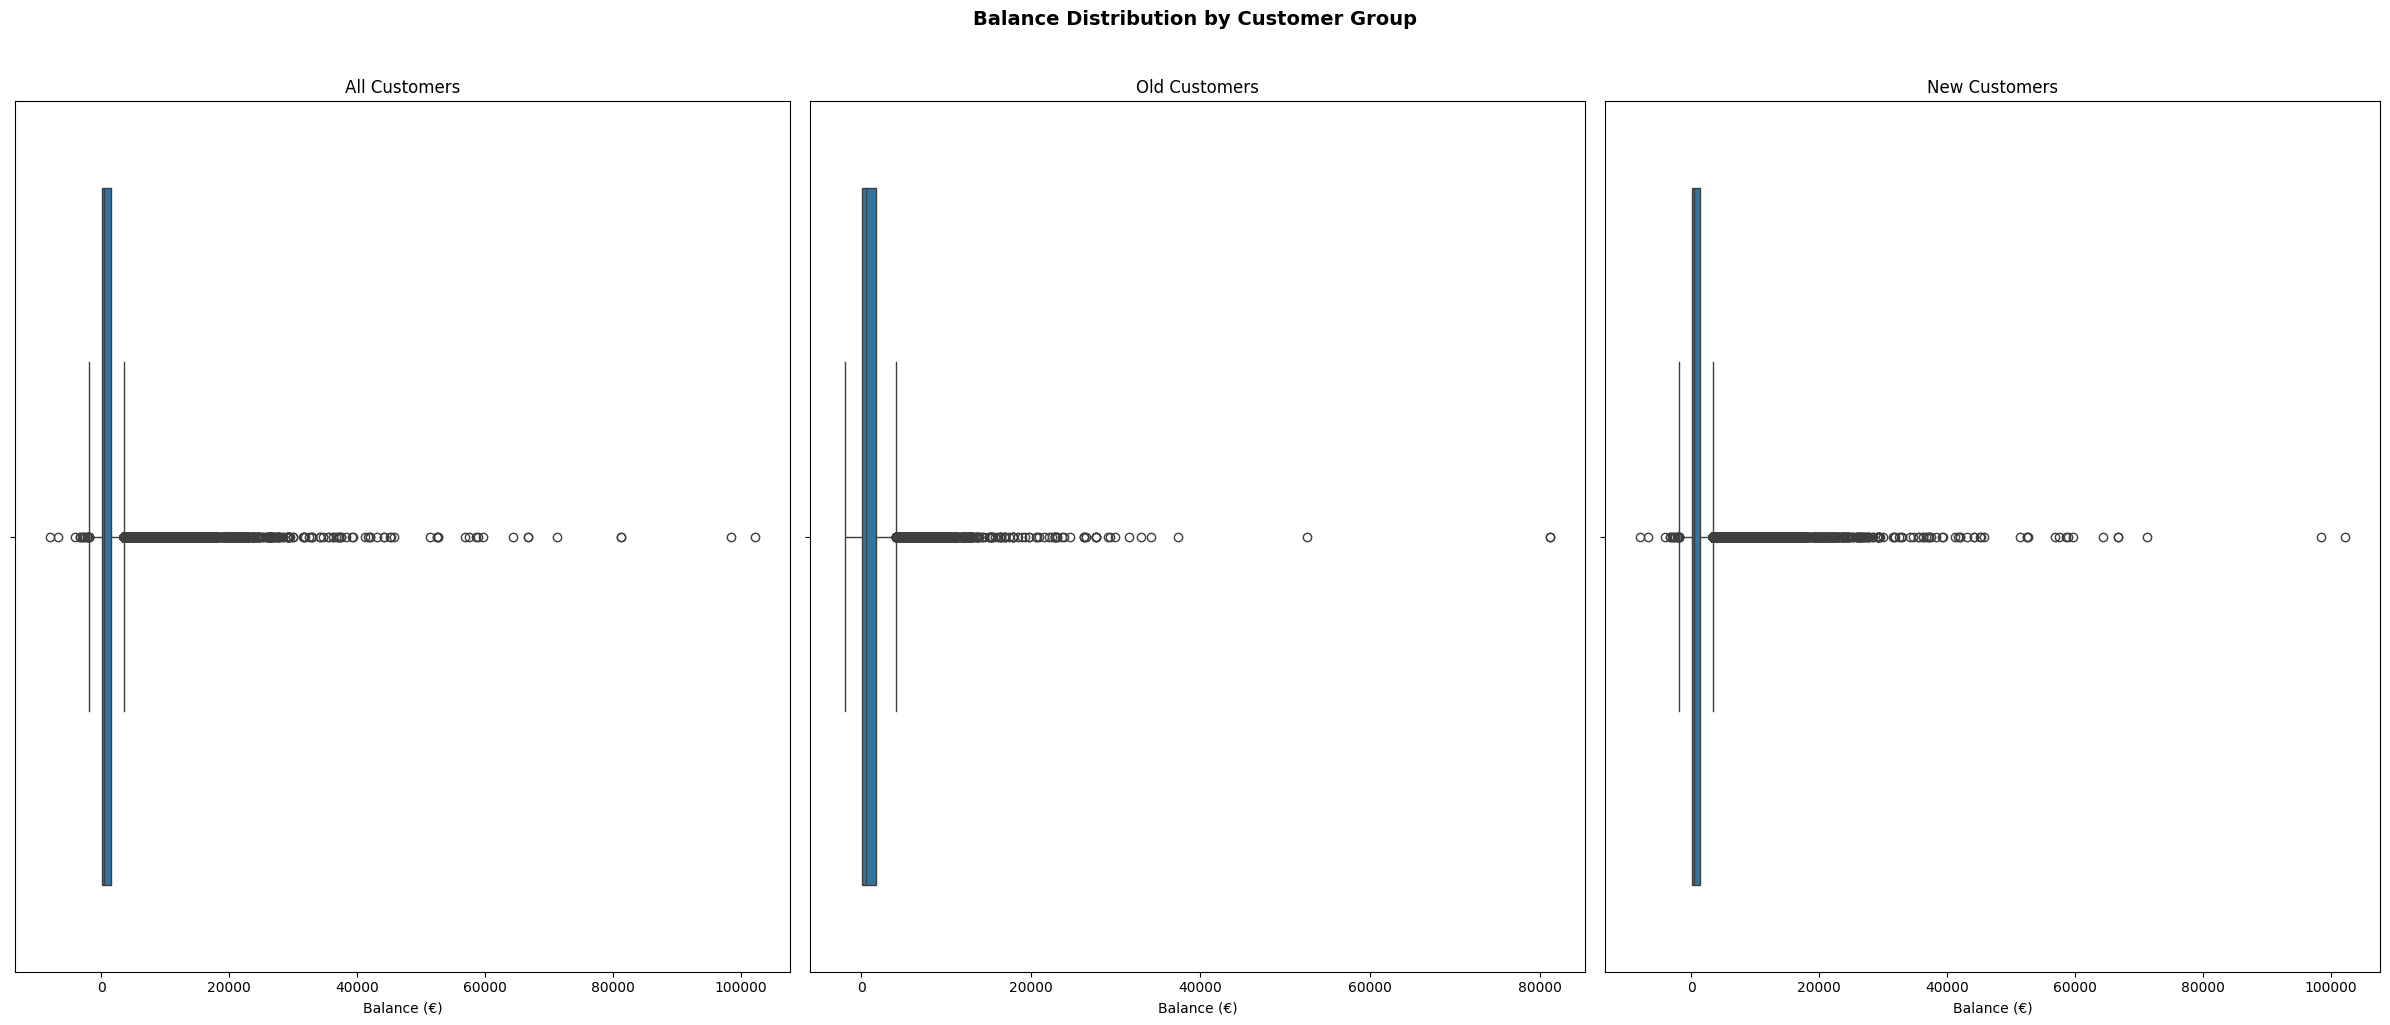

In [132]:
fig, axes = plt.subplots(1, 3, figsize=(24, 10))

for ax, (data, title) in zip(
    axes,
    [
        (df["balance"], "All Customers"),
        (df_old["balance"], "Old Customers"),
        (df_new["balance"], "New Customers"),
    ],
):
    sns.boxplot(x=data, ax=ax)
    ax.set_title(f"{title}")
    ax.set_xlabel("Balance (€)")

plt.suptitle(
    "Balance Distribution by Customer Group", fontsize=14, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

##### day

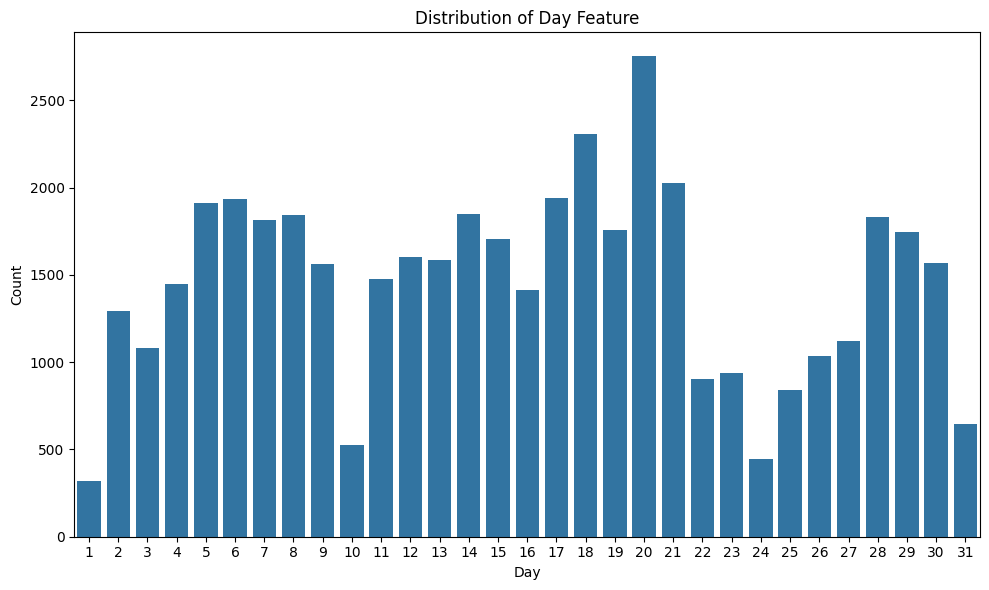

In [133]:
day_counts = df["day"].value_counts()
sns.barplot(x=day_counts.index, y=day_counts.values)
plt.title("Distribution of Day Feature")
plt.xlabel("Day")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

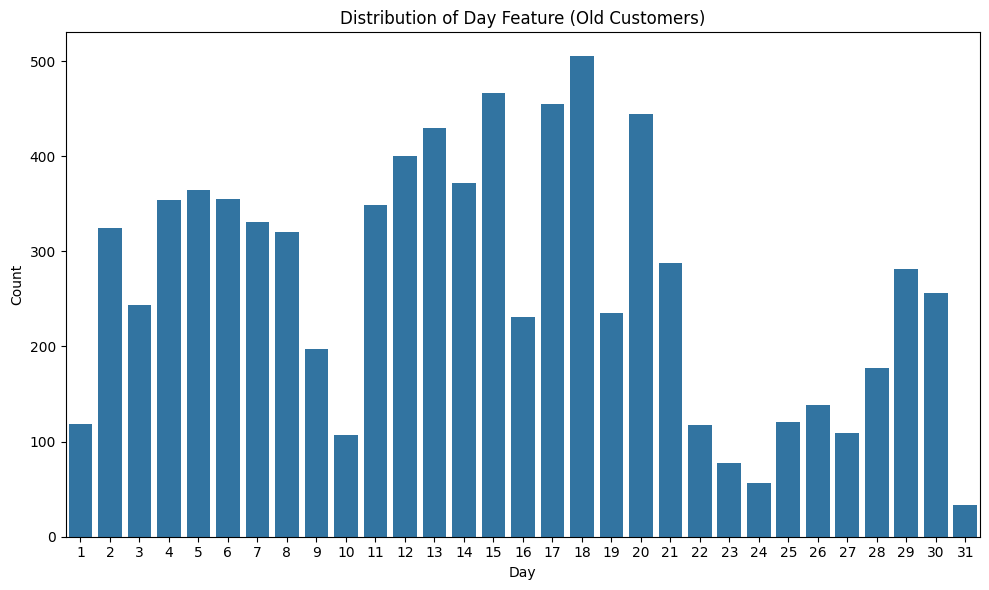

In [134]:
day_old_counts = df_old["day"].value_counts()
sns.barplot(x=day_old_counts.index, y=day_old_counts.values)
plt.title("Distribution of Day Feature (Old Customers)")
plt.xlabel("Day")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

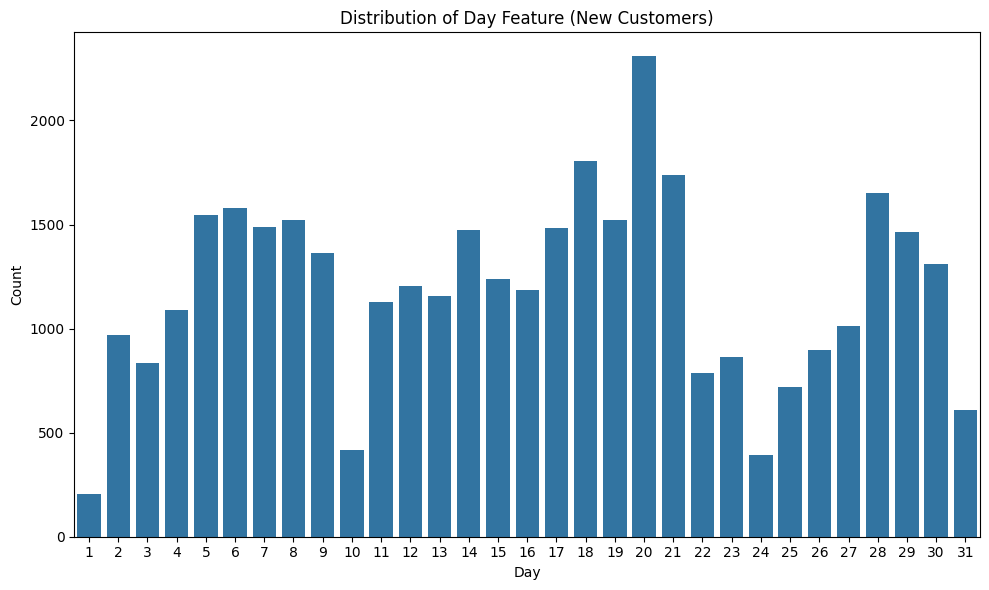

In [135]:
day_new_counts = df_new["day"].value_counts()
sns.barplot(x=day_new_counts.index, y=day_new_counts.values)
plt.title("Distribution of Day Feature (New Customers)")
plt.xlabel("Day")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

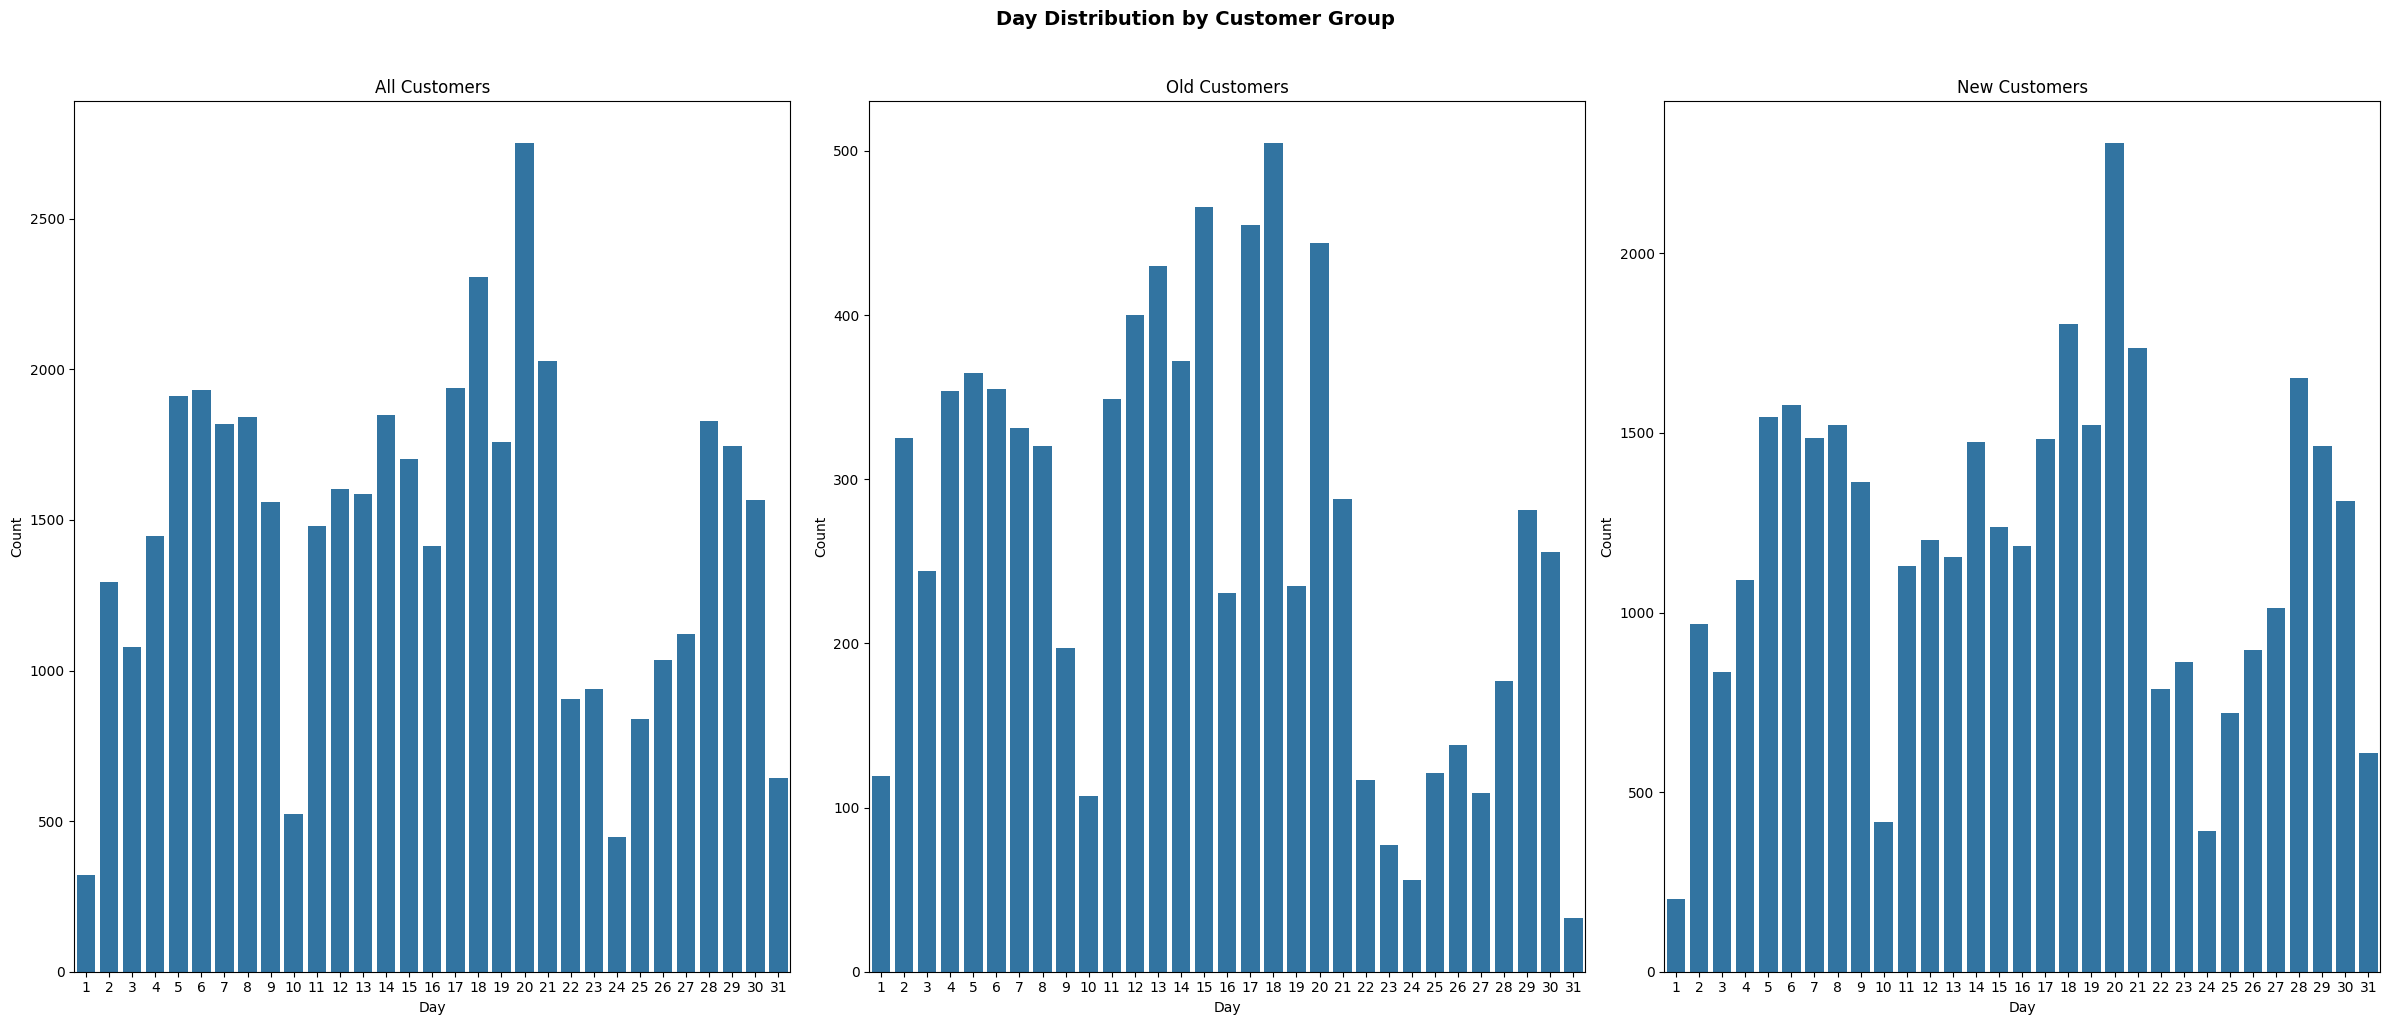

In [136]:
fig, axes = plt.subplots(1, 3, figsize=(24, 10))

for ax, (data, title) in zip(
    axes,
    [
        (day_counts, "All Customers"),
        (day_old_counts, "Old Customers"),
        (day_new_counts, "New Customers"),
    ],
):
    sns.barplot(x=data.index, y=data.values, ax=ax)
    ax.set_title(f"{title}")
    ax.set_xlabel("Day")
    ax.set_ylabel("Count")

plt.suptitle(
    "Day Distribution by Customer Group", fontsize=14, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

##### duration

In [137]:
df["duration"].nunique()

1573

In [138]:
df["duration"].value_counts(normalize=True) * 100

duration
124     0.415828
90      0.406981
89      0.391498
104     0.387074
114     0.387074
          ...   
1440    0.002212
1405    0.002212
1298    0.002212
1246    0.002212
1556    0.002212
Name: proportion, Length: 1573, dtype: float64

In [139]:
df["duration"].describe()

count    45211.000000
mean       258.163080
std        257.527812
min          0.000000
25%        103.000000
50%        180.000000
75%        319.000000
max       4918.000000
Name: duration, dtype: float64

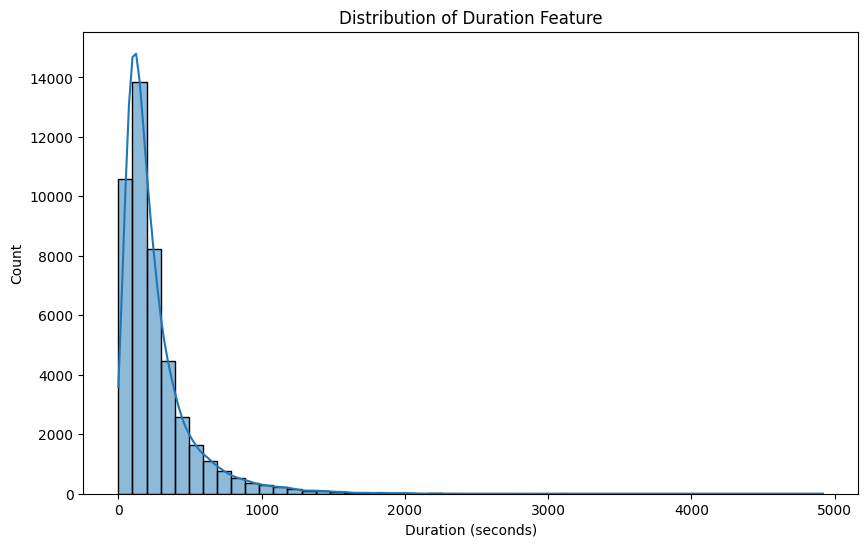

In [140]:
sns.histplot(df["duration"], bins=50, kde=True)
plt.title("Distribution of Duration Feature")
plt.xlabel("Duration (seconds)")
plt.ylabel("Count")
plt.show()

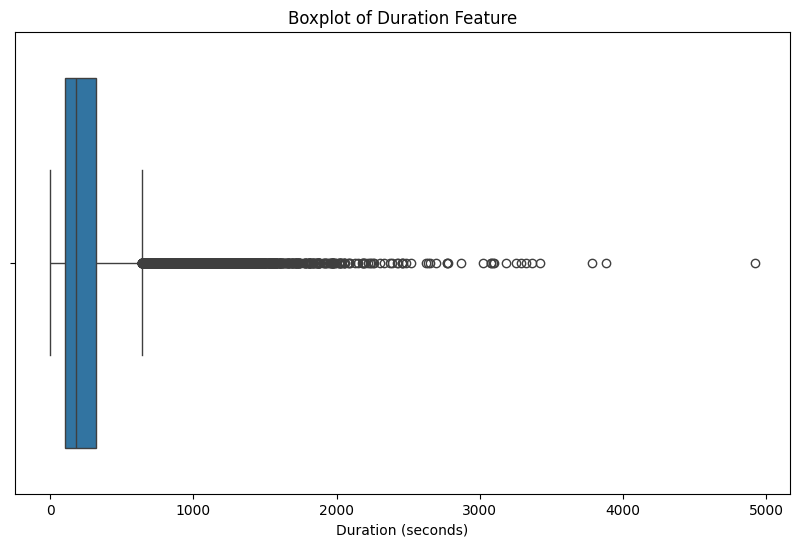

In [141]:
sns.boxplot(x=df["duration"])
plt.title("Boxplot of Duration Feature")
plt.xlabel("Duration (seconds)")
plt.show()

It is likely that longer calls have more probability to accept making a deposit

In [142]:
df_old["duration"].describe()

count    8257.000000
mean      260.118687
std       235.208105
min         1.000000
25%       113.000000
50%       193.000000
75%       324.000000
max      2219.000000
Name: duration, dtype: float64

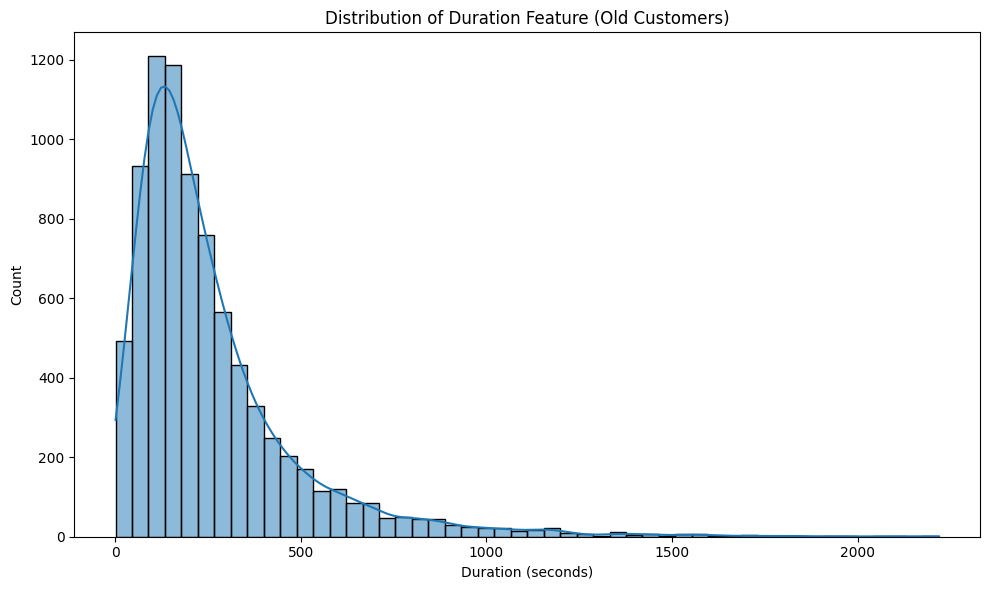

In [143]:
sns.histplot(df_old["duration"], bins=50, kde=True)
plt.title("Distribution of Duration Feature (Old Customers)")
plt.xlabel("Duration (seconds)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

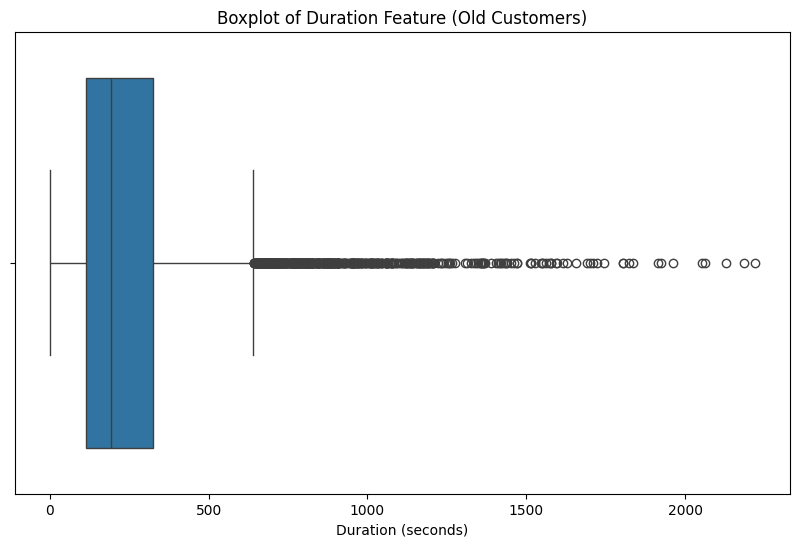

In [144]:
sns.boxplot(x=df_old["duration"])
plt.title("Boxplot of Duration Feature (Old Customers)")
plt.xlabel("Duration (seconds)")
plt.show()

In [145]:
df_new["duration"].describe()

count    36954.000000
mean       257.726119
std        262.256406
min          0.000000
25%        101.000000
50%        177.000000
75%        318.000000
max       4918.000000
Name: duration, dtype: float64

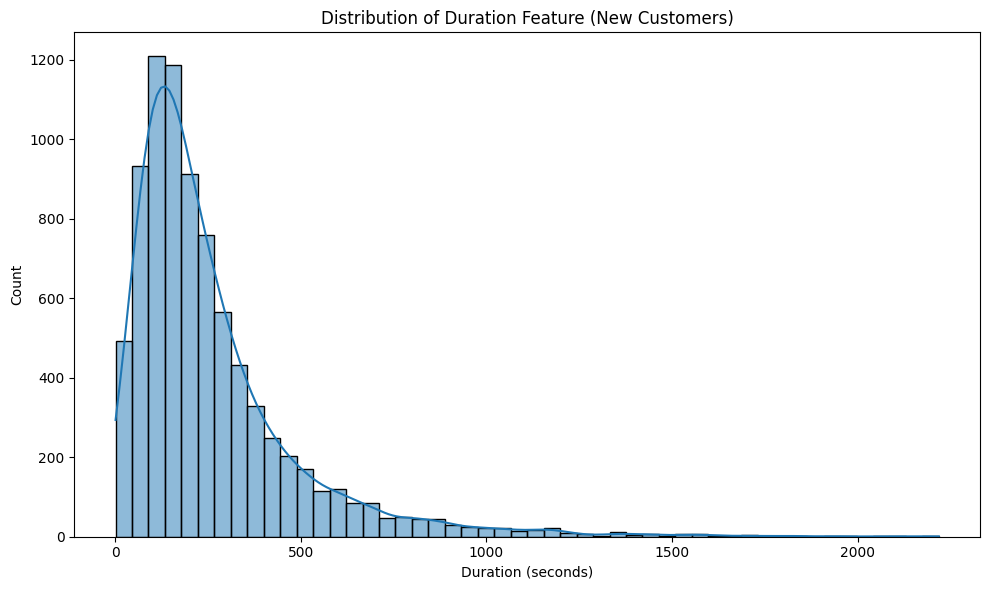

In [146]:
sns.histplot(df_old["duration"], bins=50, kde=True)
plt.title("Distribution of Duration Feature (New Customers)")
plt.xlabel("Duration (seconds)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

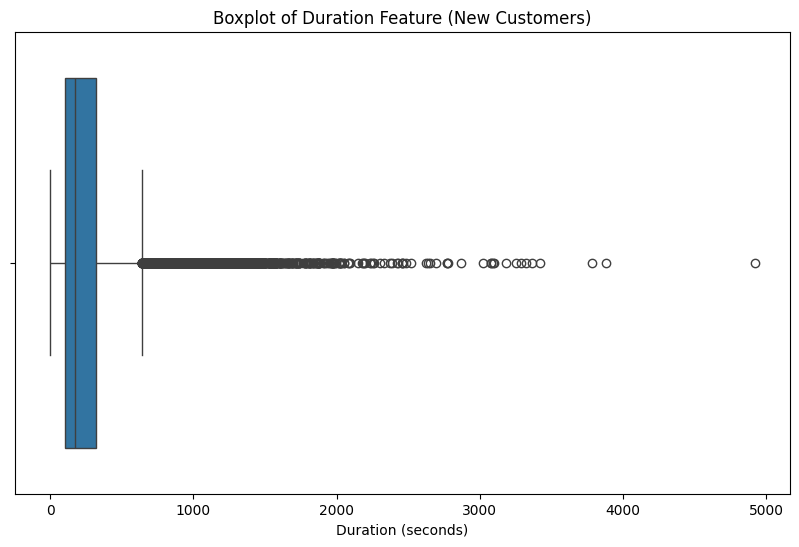

In [147]:
sns.boxplot(x=df_new["duration"])
plt.title("Boxplot of Duration Feature (New Customers)")
plt.xlabel("Duration (seconds)")
plt.show()

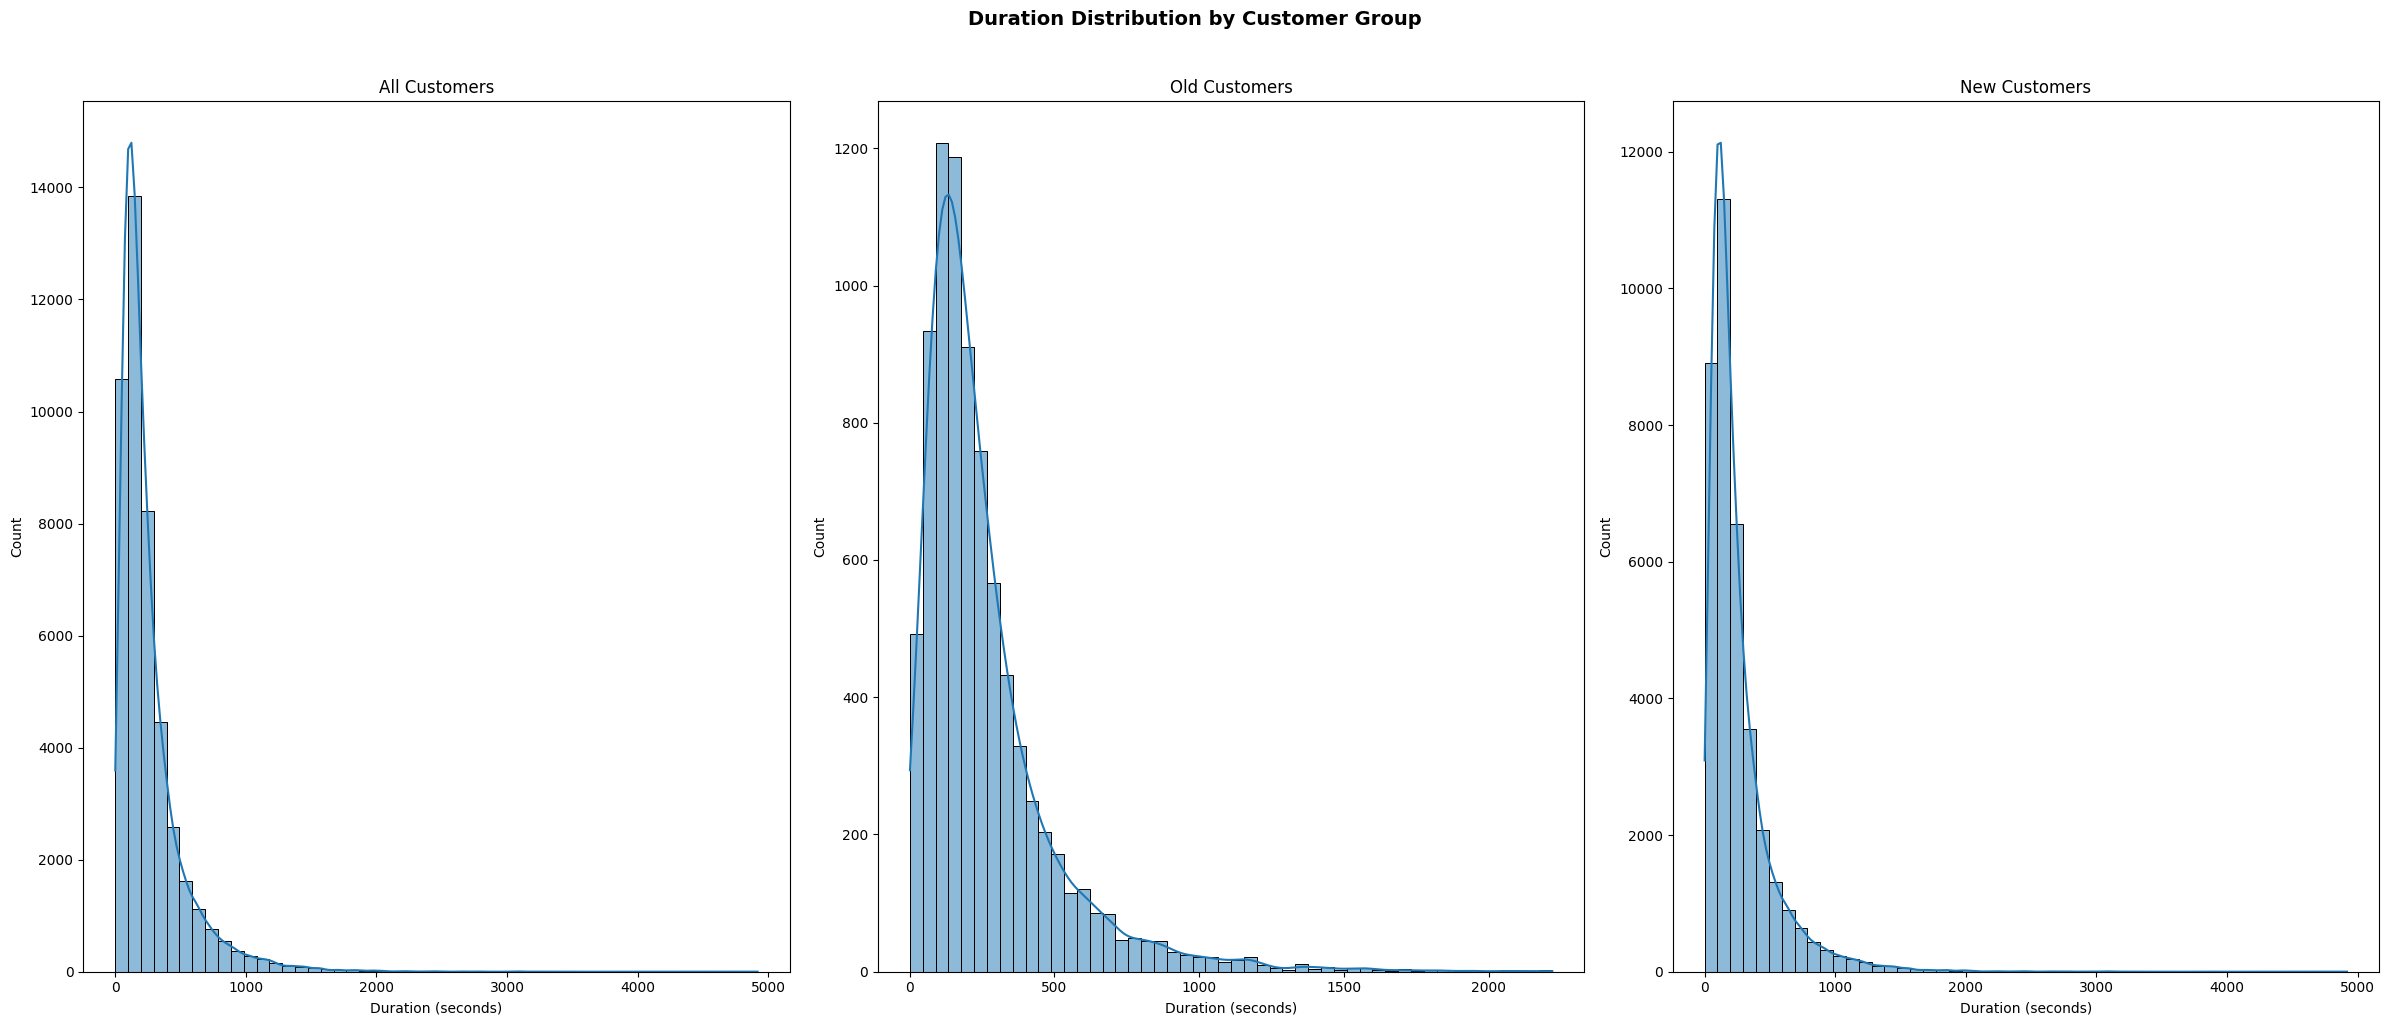

In [148]:
fig, axes = plt.subplots(1, 3, figsize=(24, 10))

for ax, (data, title) in zip(
    axes,
    [
        (df["duration"], "All Customers"),
        (df_old["duration"], "Old Customers"),
        (df_new["duration"], "New Customers"),
    ],
):
    sns.histplot(x=data, ax=ax, bins=50, kde=True)
    ax.set_title(f"{title}")
    ax.set_xlabel("Duration (seconds)")
    ax.set_ylabel("Count")

plt.suptitle(
    "Duration Distribution by Customer Group", fontsize=14, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

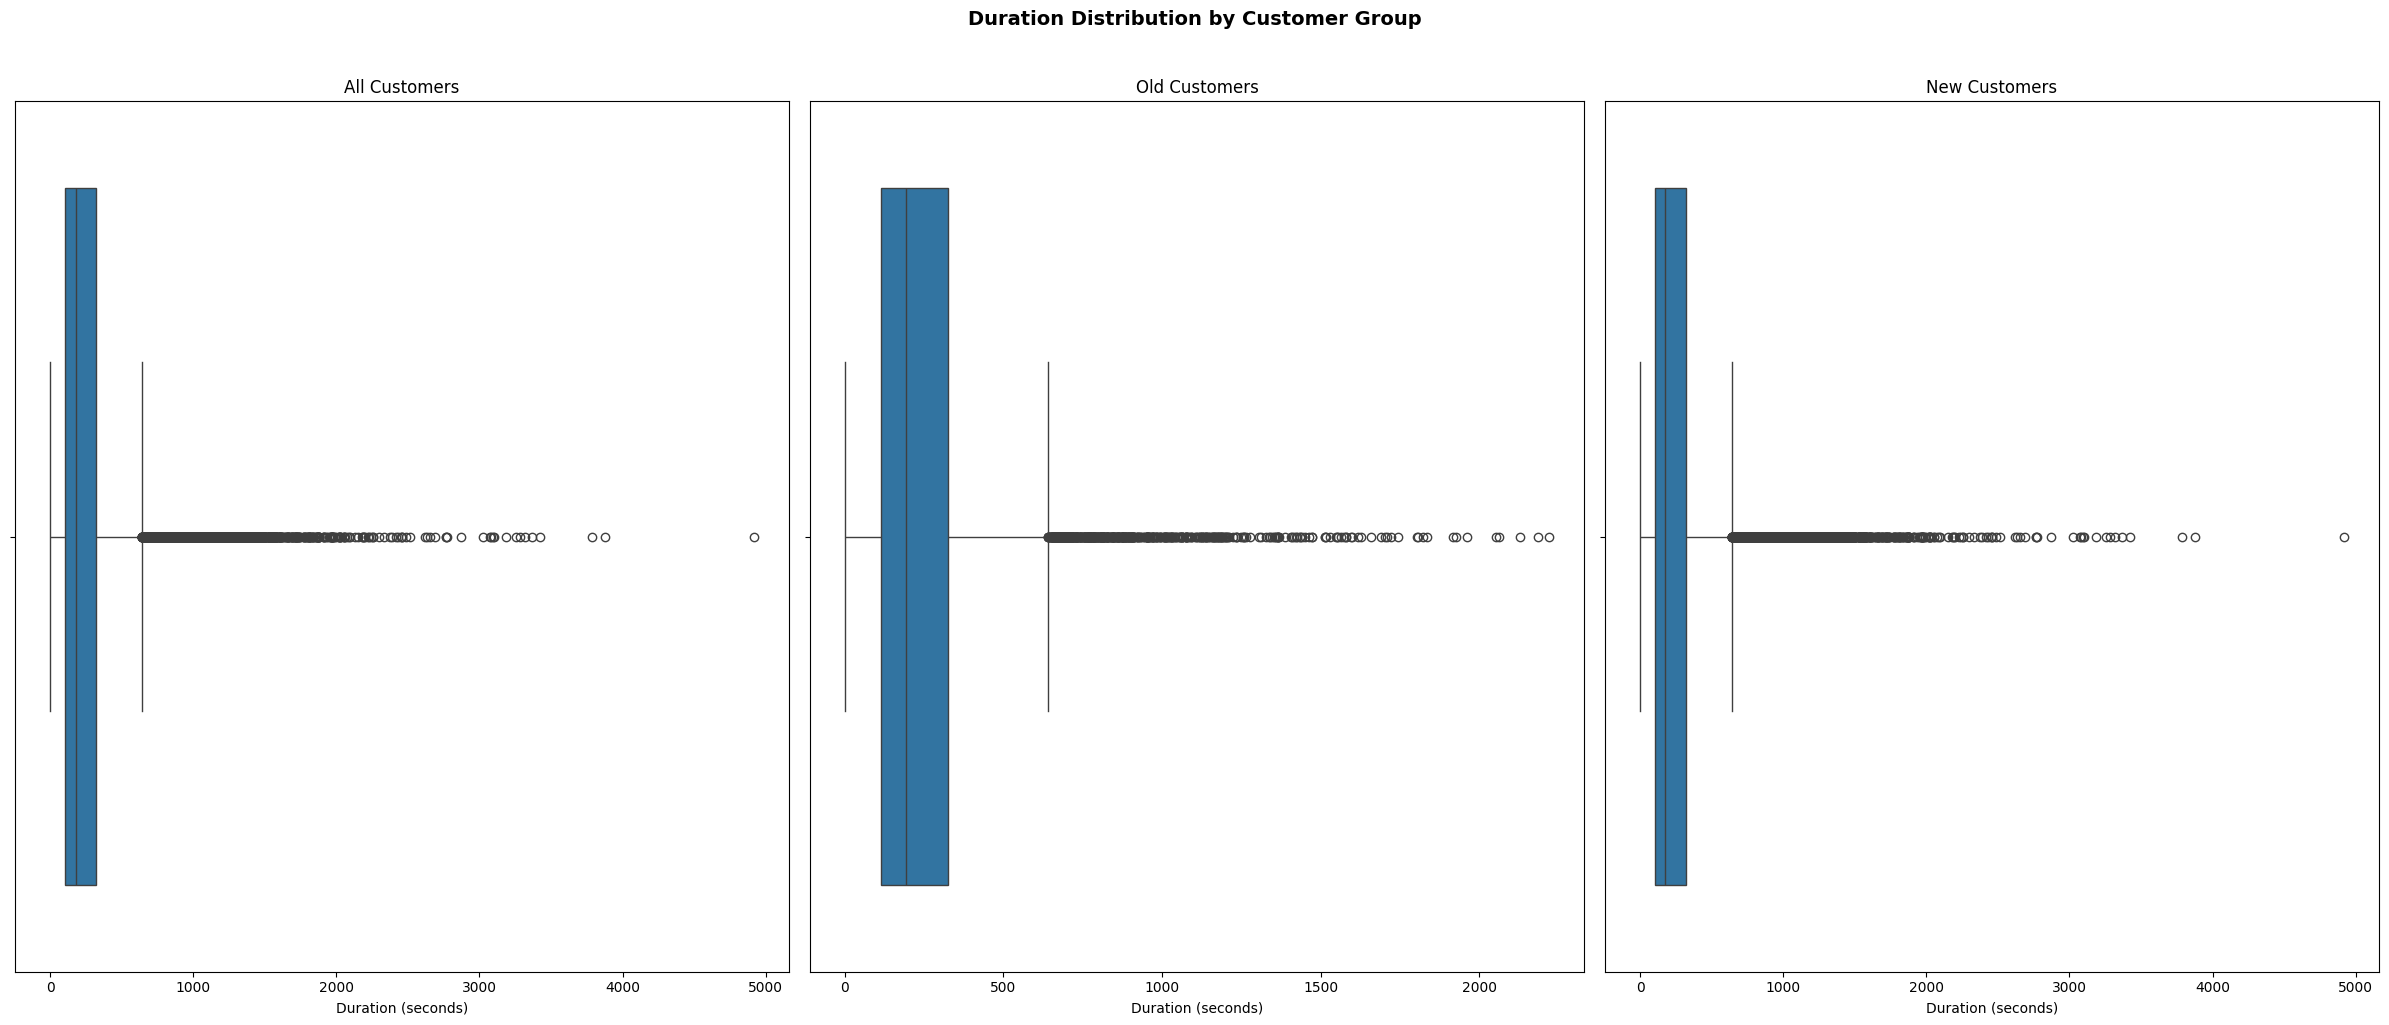

In [149]:
fig, axes = plt.subplots(1, 3, figsize=(24, 10))

for ax, (data, title) in zip(
    axes,
    [
        (df["duration"], "All Customers"),
        (df_old["duration"], "Old Customers"),
        (df_new["duration"], "New Customers"),
    ],
):
    sns.boxplot(x=data, ax=ax)
    ax.set_title(f"{title}")
    ax.set_xlabel("Duration (seconds)")

plt.suptitle(
    "Duration Distribution by Customer Group", fontsize=14, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

##### campaign

In [150]:
df["campaign"].nunique()

48

In [151]:
campaign_counts = df["campaign"].value_counts()
campaign_counts

campaign
1     17544
2     12505
3      5521
4      3522
5      1764
6      1291
7       735
8       540
9       327
10      266
11      201
12      155
13      133
14       93
15       84
16       79
17       69
18       51
19       44
20       43
21       35
22       23
25       22
23       22
24       20
28       16
29       16
26       13
31       12
27       10
32        9
30        8
33        6
34        5
35        4
36        4
43        3
38        3
41        2
50        2
37        2
51        1
63        1
55        1
46        1
58        1
39        1
44        1
Name: count, dtype: int64

In [152]:
campaign_counts / campaign_counts.sum() * 100

campaign
1     38.804716
2     27.659198
3     12.211630
4      7.790140
5      3.901705
6      2.855500
7      1.625711
8      1.194400
9      0.723275
10     0.588352
11     0.444582
12     0.342837
13     0.294176
14     0.205702
15     0.185795
16     0.174736
17     0.152618
18     0.112804
19     0.097321
20     0.095110
21     0.077415
22     0.050873
25     0.048661
23     0.048661
24     0.044237
28     0.035390
29     0.035390
26     0.028754
31     0.026542
27     0.022119
32     0.019907
30     0.017695
33     0.013271
34     0.011059
35     0.008847
36     0.008847
43     0.006636
38     0.006636
41     0.004424
50     0.004424
37     0.004424
51     0.002212
63     0.002212
55     0.002212
46     0.002212
58     0.002212
39     0.002212
44     0.002212
Name: count, dtype: float64

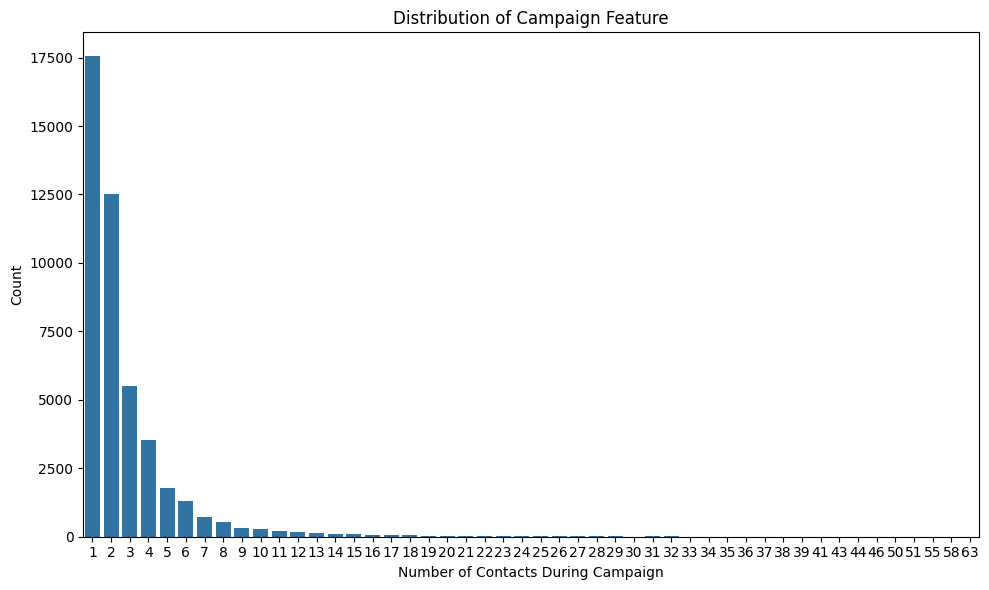

In [153]:
sns.barplot(x=campaign_counts.index, y=campaign_counts.values)
plt.title("Distribution of Campaign Feature")
plt.xlabel("Number of Contacts During Campaign")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [154]:
df_old["campaign"].nunique()

16

In [155]:
campaign_old_counts = df_old["campaign"].value_counts()
campaign_old_counts

campaign
1     4015
2     2276
3      913
4      425
5      256
6      163
7       97
8       54
9       24
11      12
10      10
12       7
13       2
14       1
15       1
16       1
Name: count, dtype: int64

In [156]:
campaign_old_counts / campaign_old_counts.sum() * 100

campaign
1     48.625409
2     27.564491
3     11.057285
4      5.147148
5      3.100400
6      1.974083
7      1.174761
8      0.653991
9      0.290662
11     0.145331
10     0.121109
12     0.084777
13     0.024222
14     0.012111
15     0.012111
16     0.012111
Name: count, dtype: float64

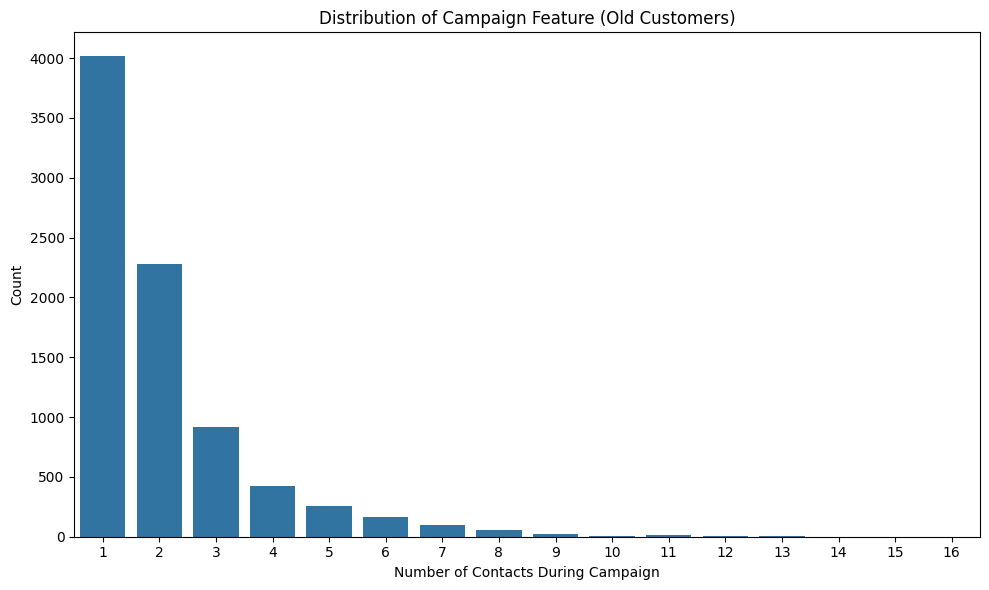

In [157]:
sns.barplot(x=campaign_old_counts.index, y=campaign_old_counts.values)
plt.title("Distribution of Campaign Feature (Old Customers)")
plt.xlabel("Number of Contacts During Campaign")
plt.ylabel("Count")
plt.tight_layout()

In [158]:
campaign_new_counts = df_new["campaign"].value_counts()
campaign_new_counts

campaign
1     13529
2     10229
3      4608
4      3097
5      1508
6      1128
7       638
8       486
9       303
10      256
11      189
12      148
13      131
14       92
15       83
16       78
17       69
18       51
19       44
20       43
21       35
22       23
25       22
23       22
24       20
28       16
29       16
26       13
31       12
27       10
32        9
30        8
33        6
34        5
35        4
36        4
43        3
38        3
41        2
50        2
37        2
51        1
63        1
55        1
46        1
58        1
39        1
44        1
Name: count, dtype: int64

In [159]:
campaign_new_counts / campaign_new_counts.sum() * 100

campaign
1     36.610380
2     27.680359
3     12.469557
4      8.380690
5      4.080749
6      3.052444
7      1.726471
8      1.315149
9      0.819938
10     0.692753
11     0.511447
12     0.400498
13     0.354495
14     0.248958
15     0.224604
16     0.211073
17     0.186719
18     0.138009
19     0.119067
20     0.116361
21     0.094712
22     0.062240
25     0.059533
23     0.059533
24     0.054121
28     0.043297
29     0.043297
26     0.035179
31     0.032473
27     0.027061
32     0.024355
30     0.021649
33     0.016236
34     0.013530
35     0.010824
36     0.010824
43     0.008118
38     0.008118
41     0.005412
50     0.005412
37     0.005412
51     0.002706
63     0.002706
55     0.002706
46     0.002706
58     0.002706
39     0.002706
44     0.002706
Name: count, dtype: float64

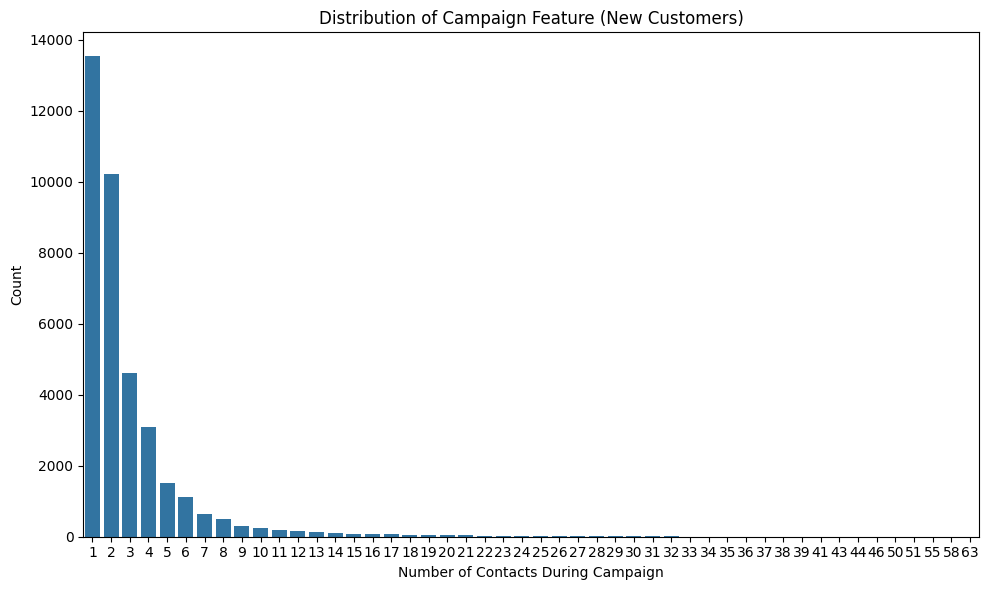

In [160]:
sns.barplot(x=campaign_new_counts.index, y=campaign_new_counts.values)
plt.title("Distribution of Campaign Feature (New Customers)")
plt.xlabel("Number of Contacts During Campaign")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

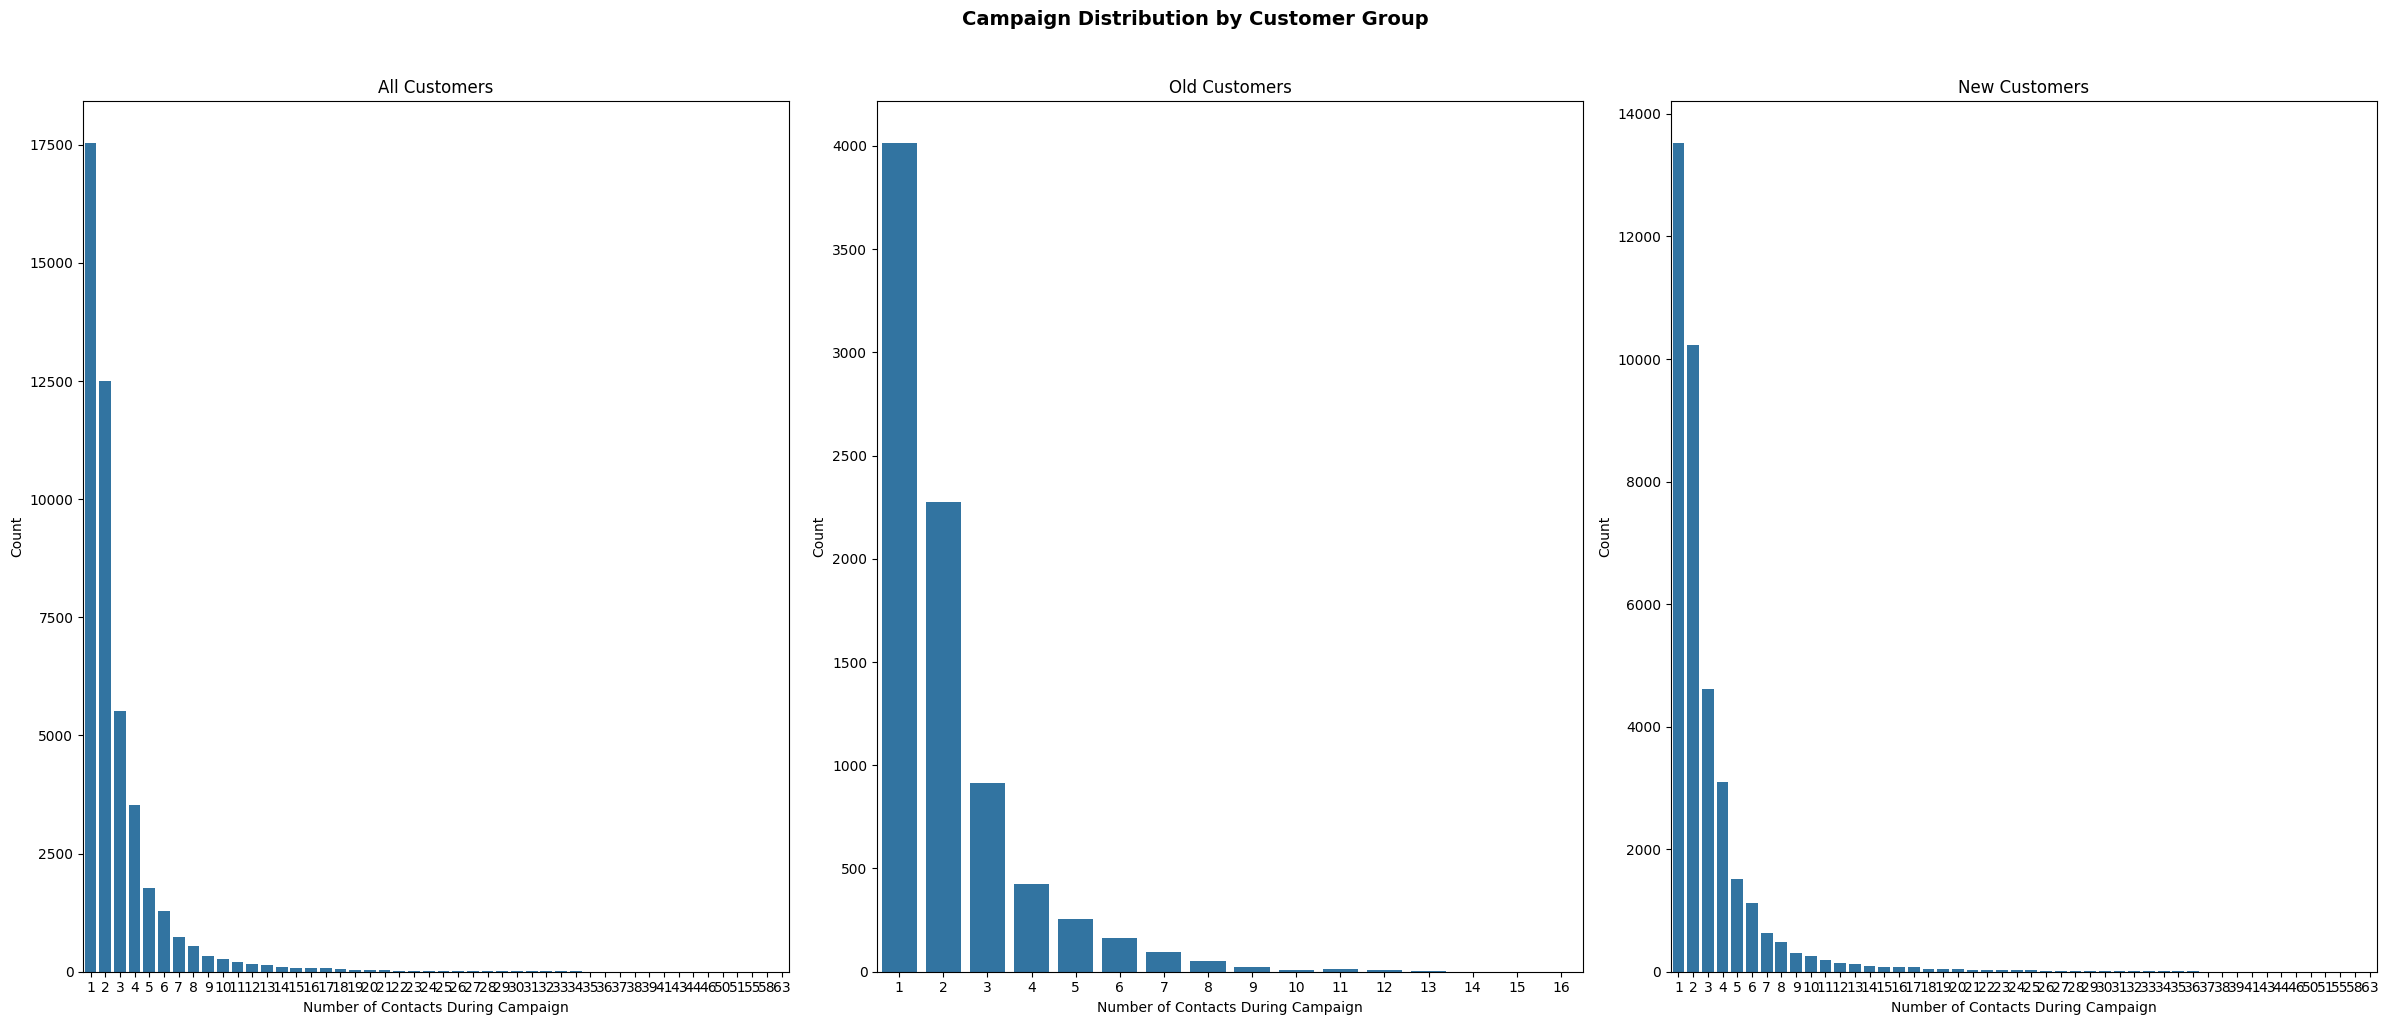

In [161]:
fig, axes = plt.subplots(1, 3, figsize=(24, 10))

for ax, (data, title) in zip(
    axes,
    [
        (campaign_counts, "All Customers"),
        (campaign_old_counts, "Old Customers"),
        (campaign_new_counts, "New Customers"),
    ],
):
    sns.barplot(x=data.index, y=data.values, ax=ax)
    ax.set_title(f"{title}")
    ax.set_xlabel("Number of Contacts During Campaign")
    ax.set_ylabel("Count")

plt.suptitle(
    "Campaign Distribution by Customer Group", fontsize=14, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

It does make sense to apply binning for this feature, because there is no significant behaviour difference among values greater than 3 and the distribution is very sparse.

##### pdays

In [162]:
df["pdays"].nunique()

559

In [163]:
df["pdays"].value_counts()

pdays
-1      36954
 182      167
 92       147
 91       126
 183      126
        ...  
 541        1
 543        1
 871        1
 550        1
 530        1
Name: count, Length: 559, dtype: int64

In [164]:
df["pdays"].value_counts(normalize=True) * 100

pdays
-1      81.736745
 182     0.369379
 92      0.325142
 91      0.278693
 183     0.278693
          ...    
 541     0.002212
 543     0.002212
 871     0.002212
 550     0.002212
 530     0.002212
Name: proportion, Length: 559, dtype: float64

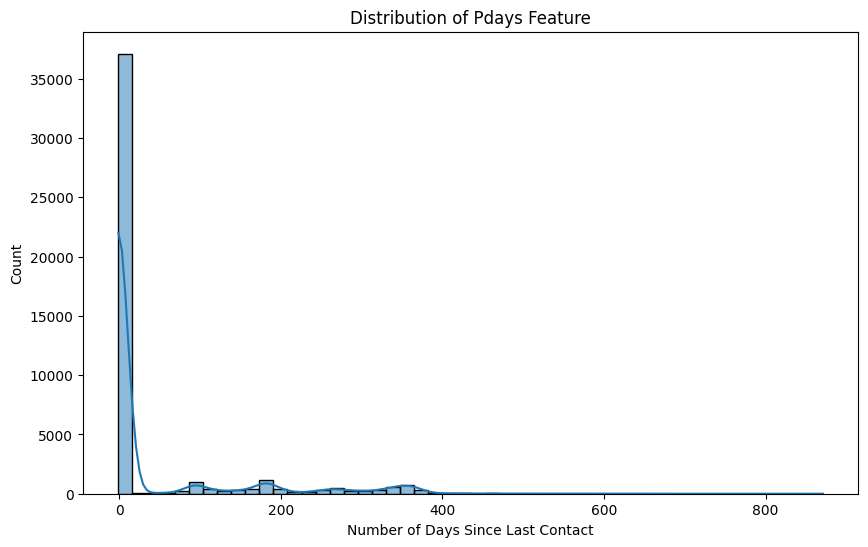

In [165]:
sns.histplot(df["pdays"], bins=50, kde=True)
plt.title("Distribution of Pdays Feature")
plt.xlabel("Number of Days Since Last Contact")
plt.ylabel("Count")
plt.show()

More than 80 percent of clients have not been contacted previously

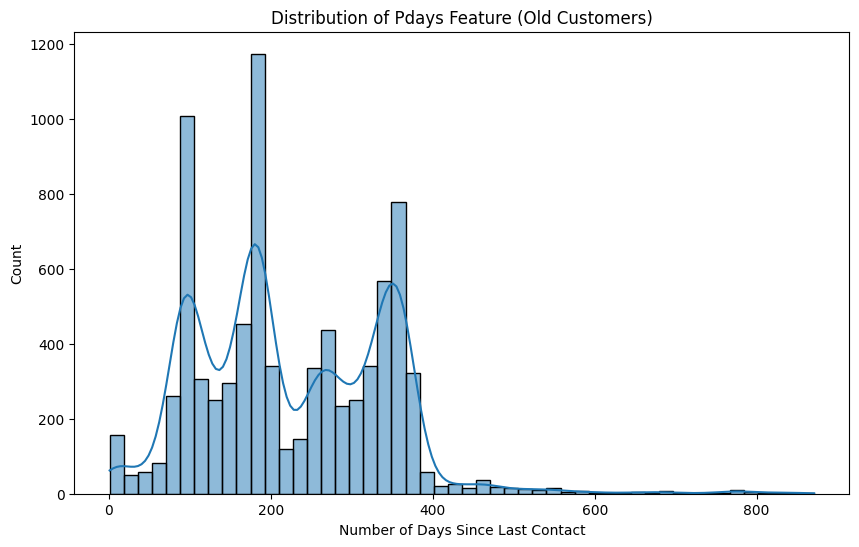

In [166]:
sns.histplot(df_old["pdays"], bins=50, kde=True)
plt.title("Distribution of Pdays Feature (Old Customers)")
plt.xlabel("Number of Days Since Last Contact")
plt.ylabel("Count")
plt.show()

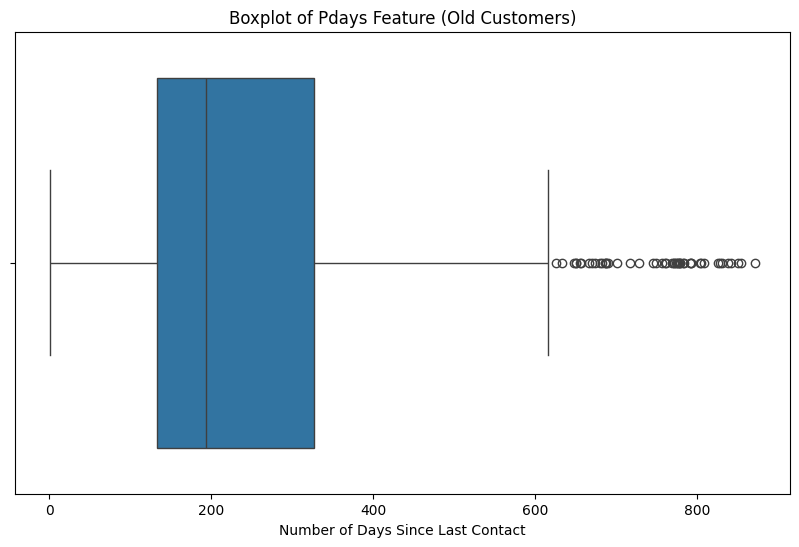

In [167]:
sns.boxplot(x=df_old["pdays"])
plt.title("Boxplot of Pdays Feature (Old Customers)")
plt.xlabel("Number of Days Since Last Contact")
plt.show()

We can try binning for pdays feature too for the same reason that behaviour wont change much for individual values

##### previous

In [168]:
df["previous"].nunique()

41

In [169]:
previous_counts = df["previous"].value_counts()
previous_counts

previous
0      36954
1       2772
2       2106
3       1142
4        714
5        459
6        277
7        205
8        129
9         92
10        67
11        65
12        44
13        38
15        20
14        19
17        15
16        13
19        11
20         8
23         8
18         6
22         6
27         5
24         5
21         4
25         4
29         4
30         3
26         2
37         2
38         2
28         2
51         1
275        1
58         1
32         1
40         1
55         1
35         1
41         1
Name: count, dtype: int64

In [170]:
previous_counts / previous_counts.sum() * 100

previous
0      81.736745
1       6.131251
2       4.658158
3       2.525934
4       1.579262
5       1.015240
6       0.612683
7       0.453429
8       0.285329
9       0.203490
10      0.148194
11      0.143770
12      0.097321
13      0.084050
15      0.044237
14      0.042025
17      0.033178
16      0.028754
19      0.024330
20      0.017695
23      0.017695
18      0.013271
22      0.013271
27      0.011059
24      0.011059
21      0.008847
25      0.008847
29      0.008847
30      0.006636
26      0.004424
37      0.004424
38      0.004424
28      0.004424
51      0.002212
275     0.002212
58      0.002212
32      0.002212
40      0.002212
55      0.002212
35      0.002212
41      0.002212
Name: count, dtype: float64

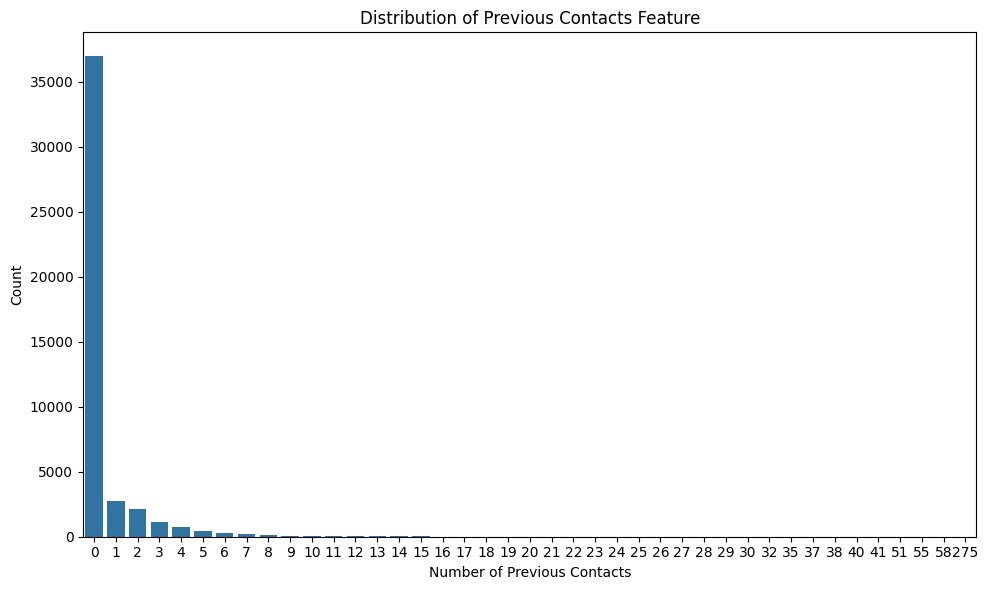

In [171]:
sns.barplot(x=previous_counts.index, y=previous_counts.values)
plt.title("Distribution of Previous Contacts Feature")
plt.xlabel("Number of Previous Contacts")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [172]:
previous_old_counts = df_old["previous"].value_counts().sort_index()
previous_old_counts

previous
1      2772
2      2106
3      1142
4       714
5       459
6       277
7       205
8       129
9        92
10       67
11       65
12       44
13       38
14       19
15       20
16       13
17       15
18        6
19       11
20        8
21        4
22        6
23        8
24        5
25        4
26        2
27        5
28        2
29        4
30        3
32        1
35        1
37        2
38        2
40        1
41        1
51        1
55        1
58        1
275       1
Name: count, dtype: int64

In [173]:
previous_old_counts / previous_old_counts.sum() * 100

previous
1      33.571515
2      25.505632
3      13.830689
4       8.647208
5       5.558920
6       3.354729
7       2.482742
8       1.562311
9       1.114206
10      0.811433
11      0.787211
12      0.532881
13      0.460216
14      0.230108
15      0.242219
16      0.157442
17      0.181664
18      0.072666
19      0.133220
20      0.096887
21      0.048444
22      0.072666
23      0.096887
24      0.060555
25      0.048444
26      0.024222
27      0.060555
28      0.024222
29      0.048444
30      0.036333
32      0.012111
35      0.012111
37      0.024222
38      0.024222
40      0.012111
41      0.012111
51      0.012111
55      0.012111
58      0.012111
275     0.012111
Name: count, dtype: float64

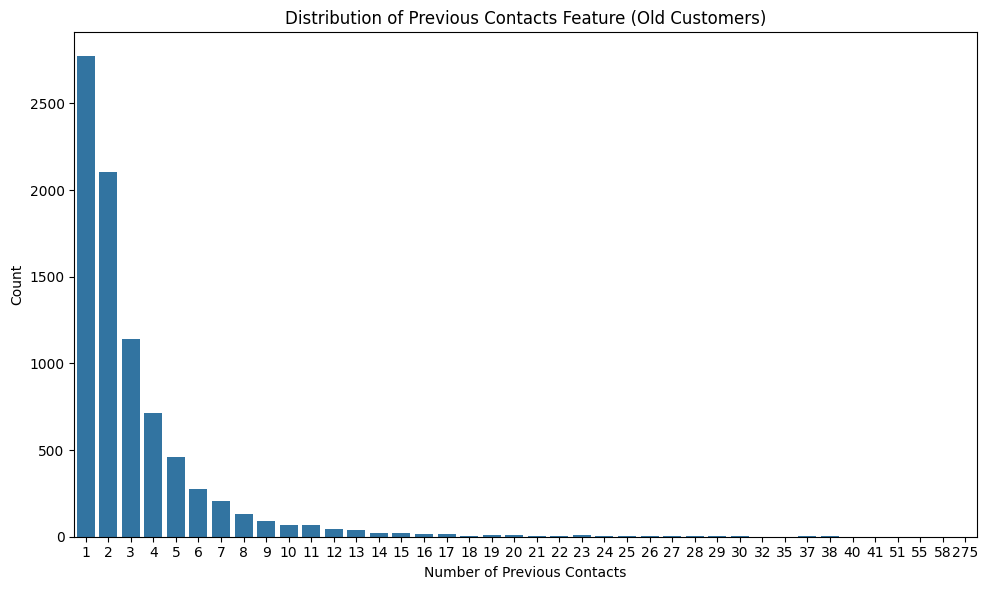

In [174]:
sns.barplot(x=previous_old_counts.index, y=previous_old_counts.values)
plt.title("Distribution of Previous Contacts Feature (Old Customers)")
plt.xlabel("Number of Previous Contacts")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Binning make sense here too. Although pdays and previous are probably correlated

### Bivariate Analysis

#### binary Features and Target

##### default and target

In [175]:
crosstab_default_y = pd.crosstab(df["default"], df["y"])
crosstab_default_y

y,no,yes
default,,
no,39159,5237
yes,763,52


In [176]:
pd.crosstab(df["default"], df["y"], normalize="all") * 100

y,no,yes
default,,
no,86.613877,11.583464
yes,1.687642,0.115016


In [177]:
chi2_default_y, p_default_y, dof_default_y, expected_default_y = chi2_contingency(
    crosstab_default_y
)
print(f"Chi-squared: {chi2_default_y}, p-value: {p_default_y}")

Chi-squared: 22.20224995571685, p-value: 2.4538606753508344e-06


Our p value is so small which means this feature has a significance. In order to analyze how strong the relationship is, we need to use Phi correlation.

In [178]:
cramer_v_default_y = association(crosstab_default_y, method="cramer")
print(f"Cramér's V: {cramer_v_default_y}")

Cramér's V: 0.022418965890751305


it is so small which means the relationship is negligible

In [179]:
crosstab_default_y_old = pd.crosstab(df_old["default"], df_old["y"])
crosstab_default_y_old

y,no,yes
default,,
no,6300,1900
yes,52,5


In [180]:
pd.crosstab(df_old["default"], df_old["y"], normalize="all") * 100

y,no,yes
default,,
no,76.298898,23.010779
yes,0.629769,0.060555


In [181]:
chi2_default_y_old, p_default_y_old, dof_default_y_old, expected_default_y_old = (
    chi2_contingency(crosstab_default_y_old)
)
print(f"Chi-squared: {chi2_default_y_old}, p-value: {p_default_y_old}")

Chi-squared: 5.826000072386599, p-value: 0.015790988300689004


In [182]:
cramer_v_default_y_old = association(crosstab_default_y_old, method="cramer")
print(f"Cramér's V: {cramer_v_default_y_old}")

Cramér's V: 0.02829879711081466


In [183]:
crosstab_default_y_new = pd.crosstab(df_new["default"], df_new["y"])
crosstab_default_y_new

y,no,yes
default,,
no,32859,3337
yes,711,47


In [184]:
pd.crosstab(df_new["default"], df_new["y"], normalize="all") * 100

y,no,yes
default,,
no,88.918656,9.030146
yes,1.924014,0.127185


In [185]:
chi2_default_y_new, p_default_y_new, dof_default_y_new, expected_default_y_new = (
    chi2_contingency(crosstab_default_y_new)
)
print(f"Chi-squared: {chi2_default_y_new}, p-value: {p_default_y_new}")

Chi-squared: 7.774265991577279, p-value: 0.005299574568733192


In [186]:
cramer_v_default_y_new = association(crosstab_default_y_new, method="cramer")
print(f"Cramér's V: {cramer_v_default_y_new}")

Cramér's V: 0.014835333523763544


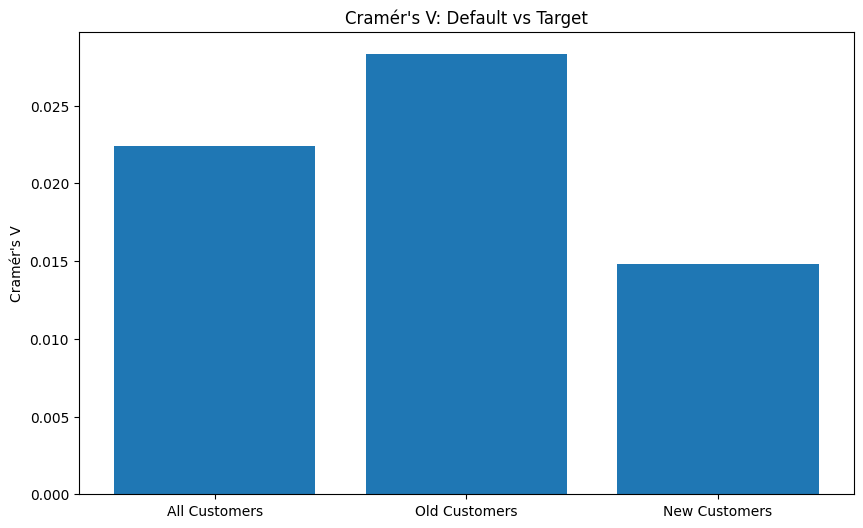

In [187]:
labels = ["All Customers", "Old Customers", "New Customers"]
values = [cramer_v_default_y, cramer_v_default_y_old, cramer_v_default_y_new]

plt.bar(labels, values)
plt.title("Cramér's V: Default vs Target")
plt.ylabel("Cramér's V")
plt.show()

It is still negligible after seperation

##### housing and target

In [188]:
crosstab_housing_y = pd.crosstab(df["housing"], df["y"])
crosstab_housing_y

y,no,yes
housing,,
no,16727,3354
yes,23195,1935


In [189]:
pd.crosstab(df["housing"], df["y"], normalize="all") * 100

y,no,yes
housing,,
no,36.997633,7.418549
yes,51.303886,4.279932


In [190]:
chi2_housing_y, p_housing_y, dof_housing_y, expected_housing_y = chi2_contingency(
    crosstab_housing_y
)
print(f"Chi-squared: {chi2_housing_y}, p-value: {p_housing_y}")

Chi-squared: 874.822448867983, p-value: 2.918797605076633e-192


In [191]:
cramer_v_housing_y = association(crosstab_housing_y, method="cramer")
print(f"Cramér's V: {cramer_v_housing_y}")

Cramér's V: 0.13917270249816985


The relationship is weak but the feature is balanced which means it is better to keep.

In [192]:
crosstab_housing_y_old = pd.crosstab(df_old["housing"], df_old["y"])
crosstab_housing_y_old

y,no,yes
housing,,
no,1861,1254
yes,4491,651


In [193]:
pd.crosstab(df_old["housing"], df_old["y"], normalize="all") * 100

y,no,yes
housing,,
no,22.538452,15.187114
yes,54.390214,7.884219


In [194]:
chi2_housing_y_old, p_housing_y_old, dof_housing_y_old, expected_housing_y_old = (
    chi2_contingency(crosstab_housing_y_old)
)
print(f"Chi-squared: {chi2_housing_y_old}, p-value: {p_housing_y_old}")

Chi-squared: 830.8057137767495, p-value: 1.082681299357847e-182


In [195]:
cramer_v_housing_y_old = association(crosstab_housing_y_old, method="cramer")
print(f"Cramér's V: {cramer_v_housing_y_old}")

Cramér's V: 0.3175005037087079


In [196]:
crosstab_housing_y_new = pd.crosstab(df_new["housing"], df_new["y"])
crosstab_housing_y_new

y,no,yes
housing,,
no,14866,2100
yes,18704,1284


In [197]:
pd.crosstab(df_new["housing"], df_new["y"], normalize="all") * 100

y,no,yes
housing,,
no,40.228392,5.682741
yes,50.614277,3.474590


In [198]:
chi2_housing_y_new, p_housing_y_new, dof_housing_y_new, expected_housing_y_new = (
    chi2_contingency(crosstab_housing_y_new)
)
print(f"Chi-squared: {chi2_housing_y_new}, p-value: {p_housing_y_new}")

Chi-squared: 390.32643960633584, p-value: 7.027664805942703e-87


In [199]:
cramer_v_housing_y_new = association(crosstab_housing_y_new, method="cramer")
print(f"Cramér's V: {cramer_v_housing_y_new}")

Cramér's V: 0.10286813781736297


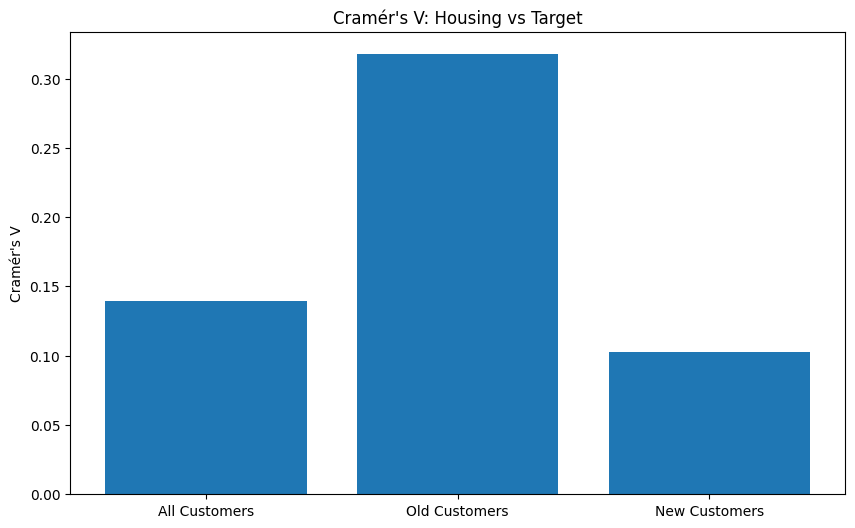

In [200]:
labels = ["All Customers", "Old Customers", "New Customers"]
values = [cramer_v_housing_y, cramer_v_housing_y_old, cramer_v_housing_y_new]
plt.bar(labels, values)
plt.title("Cramér's V: Housing vs Target")
plt.ylabel("Cramér's V")
plt.show()

It became a better predictor for old customers, but slightly decreased for new ones. Nevertheless it can be considered as a candidate for new ones as well.

##### loan and target

In [201]:
crosstab_loan_y = pd.crosstab(df["loan"], df["y"])
crosstab_loan_y

y,no,yes
loan,,
no,33162,4805
yes,6760,484


In [202]:
pd.crosstab(df["loan"], df["y"], normalize="all") * 100

y,no,yes
loan,,
no,73.349406,10.627945
yes,14.952113,1.070536


In [203]:
chi2_loan_y, p_loan_y, dof_loan_y, expected_loan_y = chi2_contingency(crosstab_loan_y)
print(f"Chi-squared: {chi2_loan_y}, p-value: {p_loan_y}")

Chi-squared: 209.61698034978633, p-value: 1.665061163492756e-47


In [204]:
cramer_v_loan_y = association(crosstab_loan_y, method="cramer")
print(f"Cramér's V: {cramer_v_loan_y}")

Cramér's V: 0.06818503472421276


In [205]:
crosstab_loan_y_old = pd.crosstab(df_old["loan"], df_old["y"])
crosstab_loan_y_old

y,no,yes
loan,,
no,5350,1784
yes,1002,121


In [206]:
pd.crosstab(df_old["loan"], df_old["y"], normalize="all") * 100

y,no,yes
loan,,
no,64.793509,21.605910
yes,12.135158,1.465423


In [207]:
chi2_loan_y_old, p_loan_y_old, dof_loan_y_old, expected_loan_y_old = chi2_contingency(
    crosstab_loan_y_old
)
print(f"Chi-squared: {chi2_loan_y_old}, p-value: {p_loan_y_old}")

Chi-squared: 109.93324456849135, p-value: 1.0134686348282395e-25


In [208]:
cramer_v_loan_y_old = association(crosstab_loan_y_old, method="cramer")
print(f"Cramér's V: {cramer_v_loan_y_old}")

Cramér's V: 0.11580537769503718


In [209]:
crosstab_loan_y_new = pd.crosstab(df_new["loan"], df_new["y"])
crosstab_loan_y_new

y,no,yes
loan,,
no,27812,3021
yes,5758,363


In [210]:
pd.crosstab(df_new["loan"], df_new["y"], normalize="all") * 100

y,no,yes
loan,,
no,75.261135,8.175028
yes,15.581534,0.982302


In [211]:
chi2_loan_y_new, p_loan_y_new, dof_loan_y_new, expected_loan_y_new = chi2_contingency(
    crosstab_loan_y_new
)
print(f"Chi-squared: {chi2_loan_y_new}, p-value: {p_loan_y_new}")

Chi-squared: 91.36630879016036, p-value: 1.193920362199692e-21


In [212]:
cramer_v_loan_y_new = association(crosstab_loan_y_new, method="cramer")
print(f"Cramér's V: {cramer_v_loan_y_new}")

Cramér's V: 0.049849760213390576


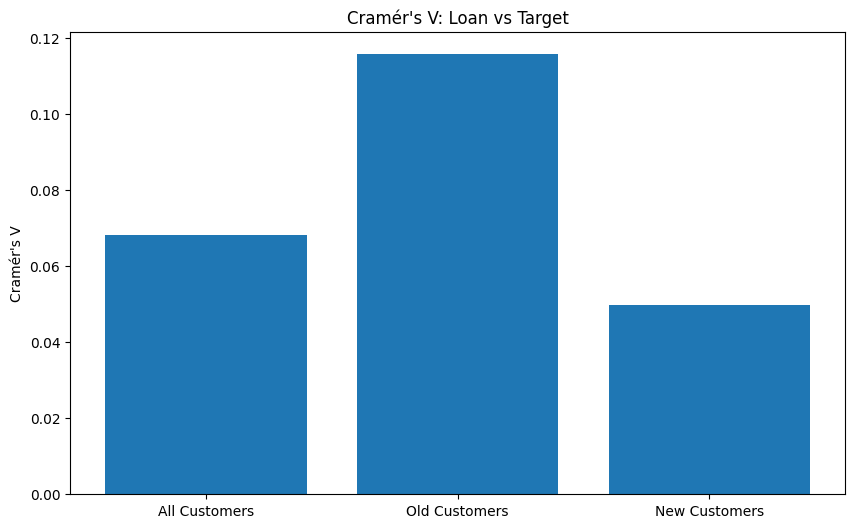

In [213]:
labels = ["All Customers", "Old Customers", "New Customers"]
values = [cramer_v_loan_y, cramer_v_loan_y_old, cramer_v_loan_y_new]
plt.bar(labels, values)
plt.title("Cramér's V: Loan vs Target")
plt.ylabel("Cramér's V")
plt.show()

It can be considered for old customers, but still negligible for new ones

#### Categorical Features and Target

##### job and target

In [214]:
crosstab_job_y = pd.crosstab(df["job"], df["y"])
crosstab_job_y

y,no,yes
job,,
admin.,4540,631
blue-collar,9024,708
entrepreneur,1364,123
housemaid,1131,109
management,8157,1301
retired,1748,516
self-employed,1392,187
services,3785,369
student,669,269


In [215]:
crosstab_job_y_normalized = pd.crosstab(df["job"], df["y"], normalize="index") * 100
crosstab_job_y_normalized

y,no,yes
job,,
admin.,87.797331,12.202669
blue-collar,92.725031,7.274969
entrepreneur,91.728312,8.271688
housemaid,91.209677,8.790323
management,86.244449,13.755551
retired,77.208481,22.791519
self-employed,88.157061,11.842939
services,91.116996,8.883004
student,71.321962,28.678038


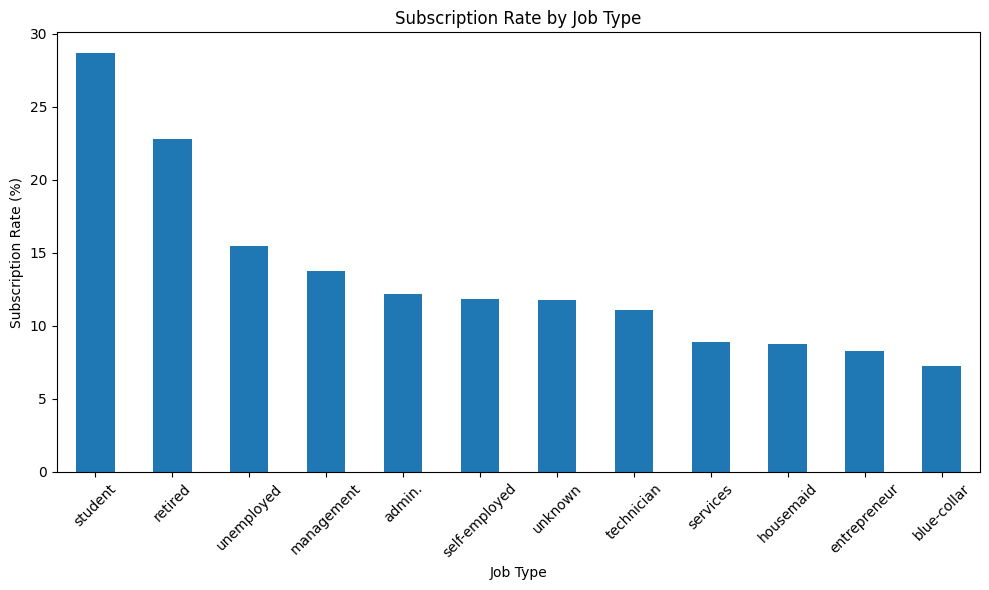

In [216]:
crosstab_job_y_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Job Type")
plt.xlabel("Job Type")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [217]:
chi2_job_y, p_job_y, dof_job_y, expected_job_y = chi2_contingency(crosstab_job_y)
print(f"Chi-squared: {chi2_job_y}, p-value: {p_job_y}, degrees of freedom: {dof_job_y}")

Chi-squared: 836.1054877471965, p-value: 3.337121944935502e-172, degrees of freedom: 11


In [218]:
cramer_v_job_y = association(crosstab_job_y, method="cramer")
print(f"Cramér's V: {cramer_v_job_y}")

Cramér's V: 0.13599047177178863


This feature is weak predictor, but it can be included for prediction

In [219]:
crosstab_job_y_old = pd.crosstab(df_old["job"], df_old["y"])
crosstab_job_y_old

y,no,yes
job,,
admin.,840,249
blue-collar,1433,184
entrepreneur,198,27
housemaid,118,34
management,1304,522
retired,282,206
self-employed,216,65
services,587,119
student,166,119


In [220]:
crosstab_job_y_old_normalized = (
    pd.crosstab(df_old["job"], df_old["y"], normalize="index") * 100
)
crosstab_job_y_old_normalized

y,no,yes
job,,
admin.,77.134986,22.865014
blue-collar,88.620903,11.379097
entrepreneur,88.000000,12.000000
housemaid,77.631579,22.368421
management,71.412924,28.587076
retired,57.786885,42.213115
self-employed,76.868327,23.131673
services,83.144476,16.855524
student,58.245614,41.754386


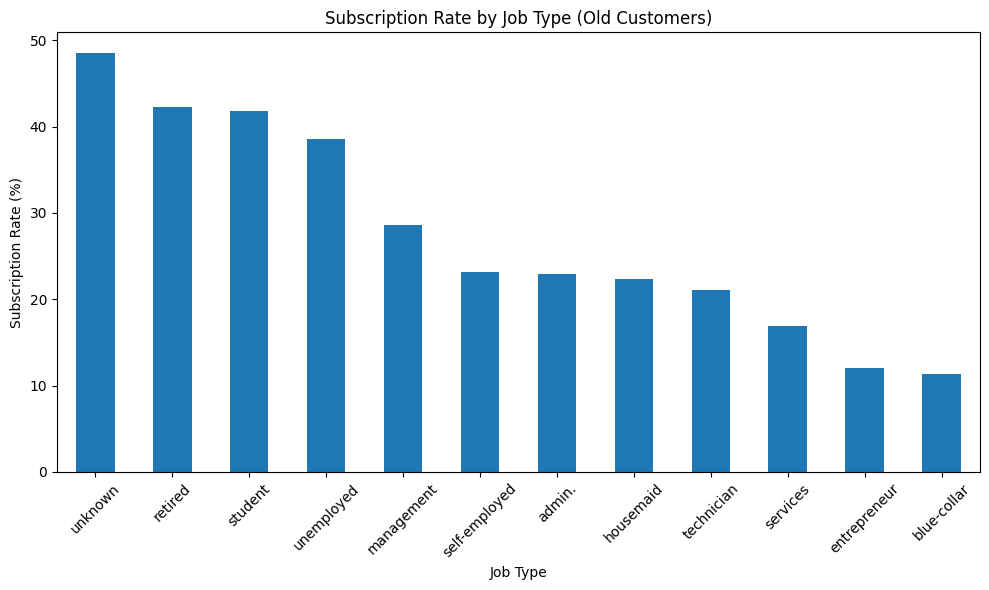

In [221]:
crosstab_job_y_old_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Job Type (Old Customers)")
plt.xlabel("Job Type")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [222]:
chi2_job_y_old, p_job_y_old, dof_job_y_old, expected_job_y_old = chi2_contingency(
    crosstab_job_y_old
)
print(
    f"Chi-squared: {chi2_job_y_old}, p-value: {p_job_y_old}, degrees of freedom: {dof_job_y_old}"
)

Chi-squared: 387.39223088703704, p-value: 2.898597498956554e-76, degrees of freedom: 11


In [223]:
cramer_v_job_y_old = association(crosstab_job_y_old, method="cramer")
print(f"Cramér's V: {cramer_v_job_y_old}")

Cramér's V: 0.2166029220279748


In [224]:
crosstab_job_y_new = pd.crosstab(df_new["job"], df_new["y"])
crosstab_job_y_new

y,no,yes
job,,
admin.,3700,382
blue-collar,7591,524
entrepreneur,1166,96
housemaid,1013,75
management,6853,779
retired,1466,310
self-employed,1176,122
services,3198,250
student,503,150


In [225]:
crosstab_job_y_new_normalized = (
    pd.crosstab(df_new["job"], df_new["y"], normalize="index") * 100
)
crosstab_job_y_new_normalized

y,no,yes
job,,
admin.,90.641842,9.358158
blue-collar,93.542822,6.457178
entrepreneur,92.393027,7.606973
housemaid,93.106618,6.893382
management,89.792977,10.207023
retired,82.545045,17.454955
self-employed,90.600924,9.399076
services,92.749420,7.250580
student,77.029096,22.970904


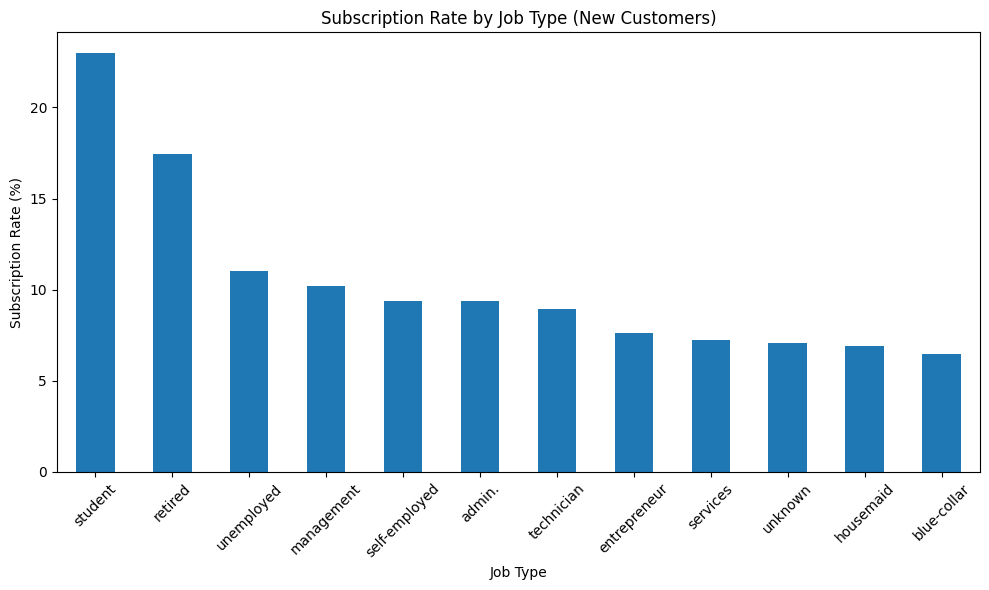

In [226]:
crosstab_job_y_new_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Job Type (New Customers)")
plt.xlabel("Job Type")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [227]:
chi2_job_y_new, p_job_y_new, dof_job_y_new, expected_job_y_new = chi2_contingency(
    crosstab_job_y_new
)
print(
    f"Chi-squared: {chi2_job_y_new}, p-value: {p_job_y_new}, degrees of freedom: {dof_job_y_new}"
)

Chi-squared: 409.97915156030183, p-value: 4.652500950402672e-81, degrees of freedom: 11


In [228]:
cramer_v_job_y_new = association(crosstab_job_y_new, method="cramer")
print(f"Cramér's V: {cramer_v_job_y_new}")

Cramér's V: 0.1053295330681317


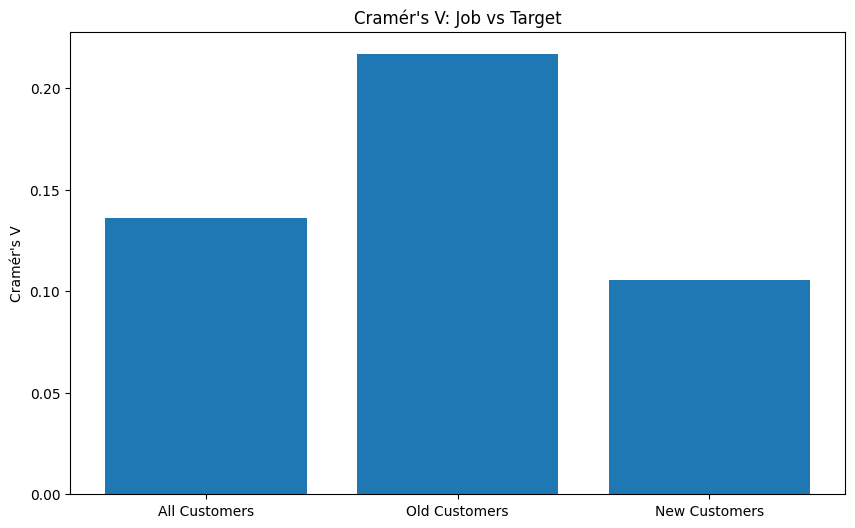

In [229]:
labels = ["All Customers", "Old Customers", "New Customers"]
values = [cramer_v_job_y, cramer_v_job_y_old, cramer_v_job_y_new]
plt.bar(labels, values)
plt.title("Cramér's V: Job vs Target")
plt.ylabel("Cramér's V")
plt.show()

It is still a usable feature after seperation

##### marital and target

In [230]:
crosstab_marital_y = pd.crosstab(df["marital"], df["y"])
crosstab_marital_y

y,no,yes
marital,,
divorced,4585,622
married,24459,2755
single,10878,1912


In [231]:
crosstab_marital_y_normalized = (
    pd.crosstab(df["marital"], df["y"], normalize="index") * 100
)
crosstab_marital_y_normalized

y,no,yes
marital,,
divorced,88.054542,11.945458
married,89.876534,10.123466
single,85.050821,14.949179


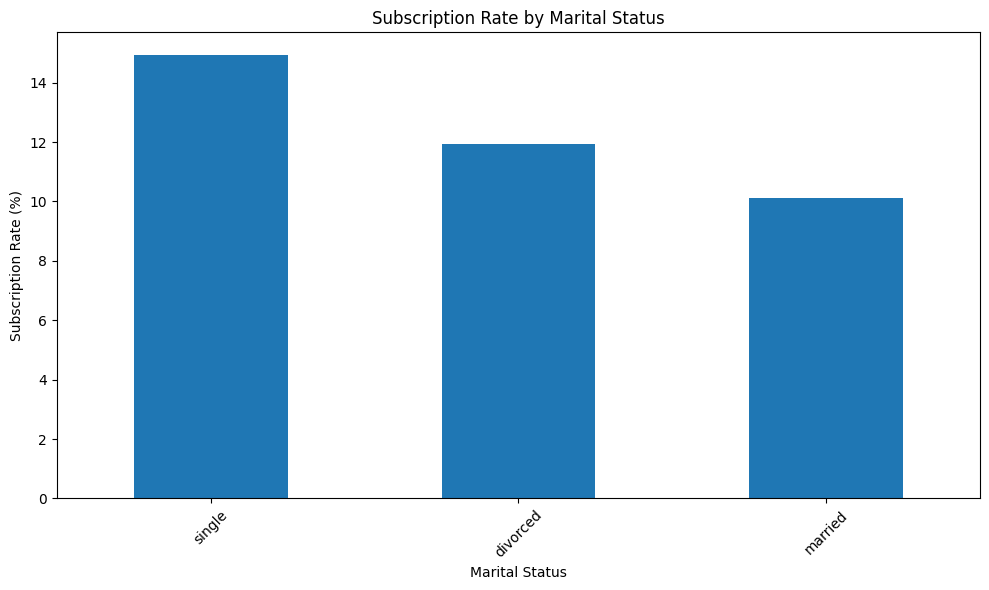

In [232]:
crosstab_marital_y_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [233]:
chi2_marital_y, p_marital_y, dof_marital_y, expected_marital_y = chi2_contingency(
    crosstab_marital_y
)
print(
    f"Chi-squared: {chi2_marital_y}, p-value: {p_marital_y}, degrees of freedom: {dof_marital_y}"
)

Chi-squared: 196.49594565603957, p-value: 2.1450999986791792e-43, degrees of freedom: 2


In [234]:
cramer_v_marital_y = association(crosstab_marital_y, method="cramer")
print(f"Cramér's V: {cramer_v_marital_y}")

Cramér's V: 0.06592569856952814


This feature is negligible too

In [235]:
crosstab_marital_y_old = pd.crosstab(df_old["marital"], df_old["y"])
crosstab_marital_y_old

y,no,yes
marital,,
divorced,747,184
married,3695,1050
single,1910,671


In [236]:
crosstab_marital_y_old_normalized = (
    pd.crosstab(df_old["marital"], df_old["y"], normalize="index") * 100
)
crosstab_marital_y_old_normalized

y,no,yes
marital,,
divorced,80.236305,19.763695
married,77.871444,22.128556
single,74.002325,25.997675


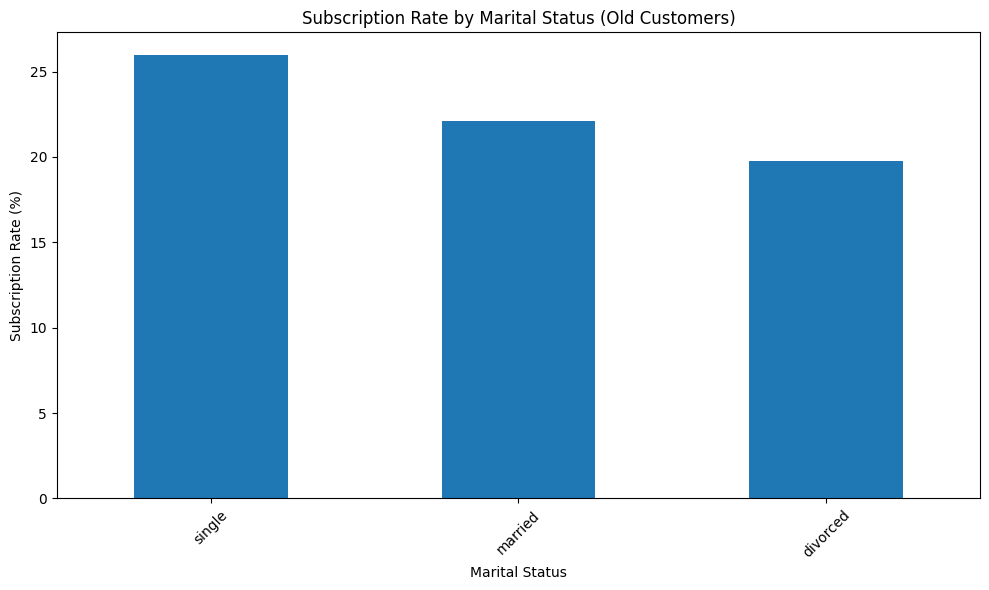

In [237]:
crosstab_marital_y_old_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Marital Status (Old Customers)")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [238]:
chi2_marital_y_old, p_marital_y_old, dof_marital_y_old, expected_marital_y_old = (
    chi2_contingency(crosstab_marital_y_old)
)
print(
    f"Chi-squared: {chi2_marital_y_old}, p-value: {p_marital_y_old}, degrees of freedom: {dof_marital_y_old}"
)

Chi-squared: 20.568199284986882, p-value: 3.417214762955977e-05, degrees of freedom: 2


In [239]:
cramer_v_marital_y_old = association(crosstab_marital_y_old, method="cramer")
print(f"Cramér's V: {cramer_v_marital_y_old}")

Cramér's V: 0.04990993375899151


In [240]:
crosstab_marital_y_new = pd.crosstab(df_new["marital"], df_new["y"])
crosstab_marital_y_new

y,no,yes
marital,,
divorced,3838,438
married,20764,1705
single,8968,1241


In [241]:
crosstab_marital_y_new_normalized = (
    pd.crosstab(df_new["marital"], df_new["y"], normalize="index") * 100
)
crosstab_marital_y_new_normalized

y,no,yes
marital,,
divorced,89.756782,10.243218
married,92.411767,7.588233
single,87.844059,12.155941


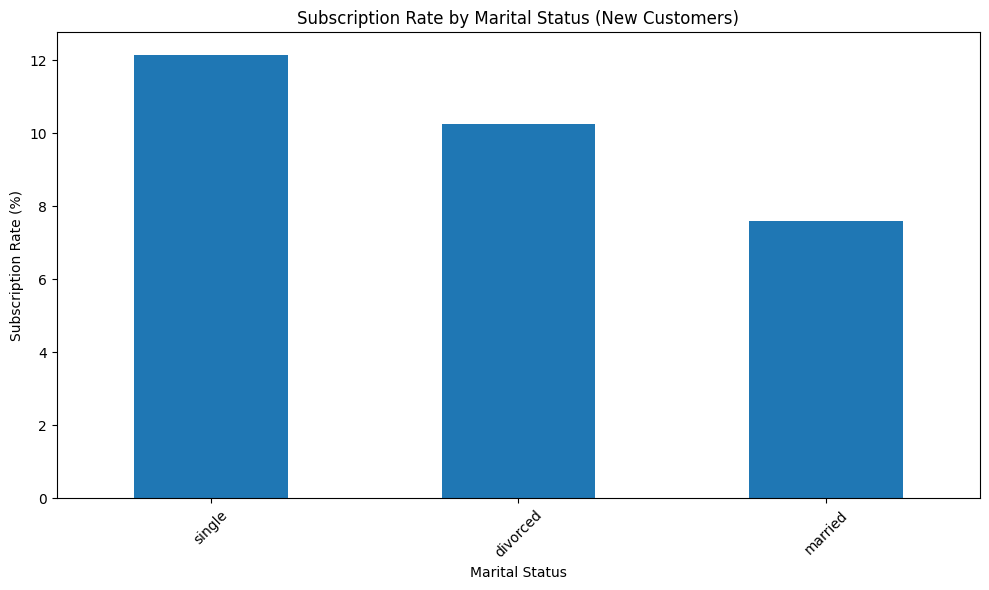

In [242]:
crosstab_marital_y_new_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Marital Status (New Customers)")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [243]:
chi2_marital_y_new, p_marital_y_new, dof_marital_y_new, expected_marital_y_new = (
    chi2_contingency(crosstab_marital_y_new)
)
print(
    f"Chi-squared: {chi2_marital_y_new}, p-value: {p_marital_y_new}, degrees of freedom: {dof_marital_y_new}"
)

Chi-squared: 182.90957748867083, p-value: 1.9128895943304215e-40, degrees of freedom: 2


In [244]:
cramer_v_marital_y_new = association(crosstab_marital_y_new, method="cramer")
print(f"Cramér's V: {cramer_v_marital_y_new}")

Cramér's V: 0.07035378966565389


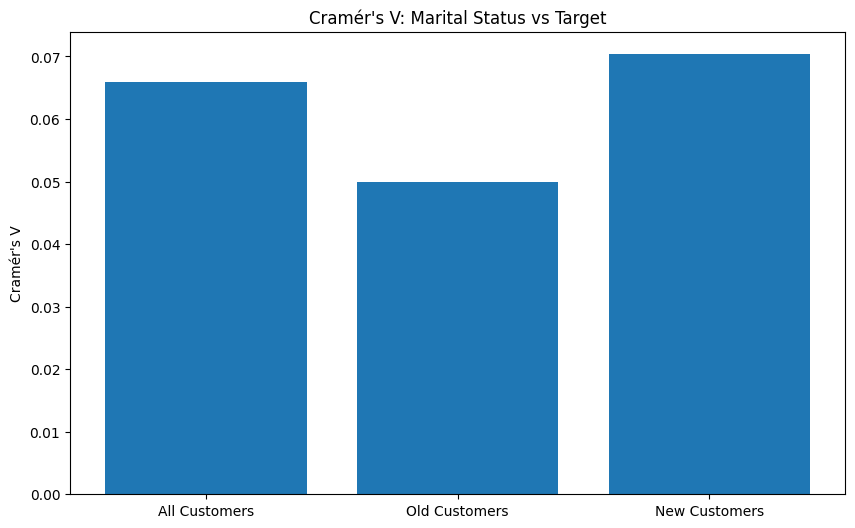

In [245]:
labels = ["All Customers", "Old Customers", "New Customers"]
values = [cramer_v_marital_y, cramer_v_marital_y_old, cramer_v_marital_y_new]
plt.bar(labels, values)
plt.title("Cramér's V: Marital Status vs Target")
plt.ylabel("Cramér's V")
plt.show()

The feature is still unusable after seperation

##### education and target

In [246]:
crosstab_education_y = pd.crosstab(df["education"], df["y"])
crosstab_education_y

y,no,yes
education,,
primary,6260,591
secondary,20752,2450
tertiary,11305,1996
unknown,1605,252


In [247]:
crosstab_education_y_normalized = (
    pd.crosstab(df["education"], df["y"], normalize="index") * 100
)
crosstab_education_y_normalized

y,no,yes
education,,
primary,91.373522,8.626478
secondary,89.440565,10.559435
tertiary,84.993610,15.006390
unknown,86.429725,13.570275


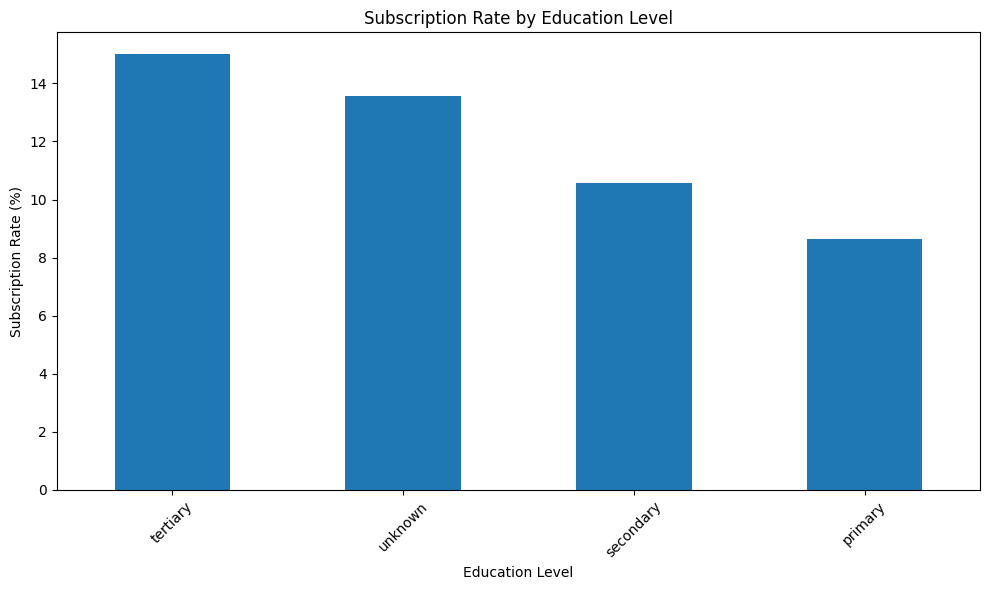

In [248]:
crosstab_education_y_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [249]:
chi2_education_y, p_education_y, dof_education_y, expected_education_y = (
    chi2_contingency(crosstab_education_y)
)
print(
    f"Chi-squared: {chi2_education_y}, p-value: {p_education_y}, degrees of freedom: {dof_education_y}"
)

Chi-squared: 238.92350616407606, p-value: 1.6266562124072994e-51, degrees of freedom: 3


In [250]:
cramer_v_education_y = association(crosstab_education_y, method="cramer")
print(f"Cramér's V: {cramer_v_education_y}")

Cramér's V: 0.07269547575269042


This feature is also negligible

In [251]:
crosstab_education_y_old = pd.crosstab(df_old["education"], df_old["y"])
crosstab_education_y_old

y,no,yes
education,,
primary,847,173
secondary,3399,855
tertiary,1879,781
unknown,227,96


In [252]:
crosstab_education_y_old_normalized = (
    pd.crosstab(df_old["education"], df_old["y"], normalize="index") * 100
)
crosstab_education_y_old_normalized

y,no,yes
education,,
primary,83.039216,16.960784
secondary,79.901269,20.098731
tertiary,70.639098,29.360902
unknown,70.278638,29.721362


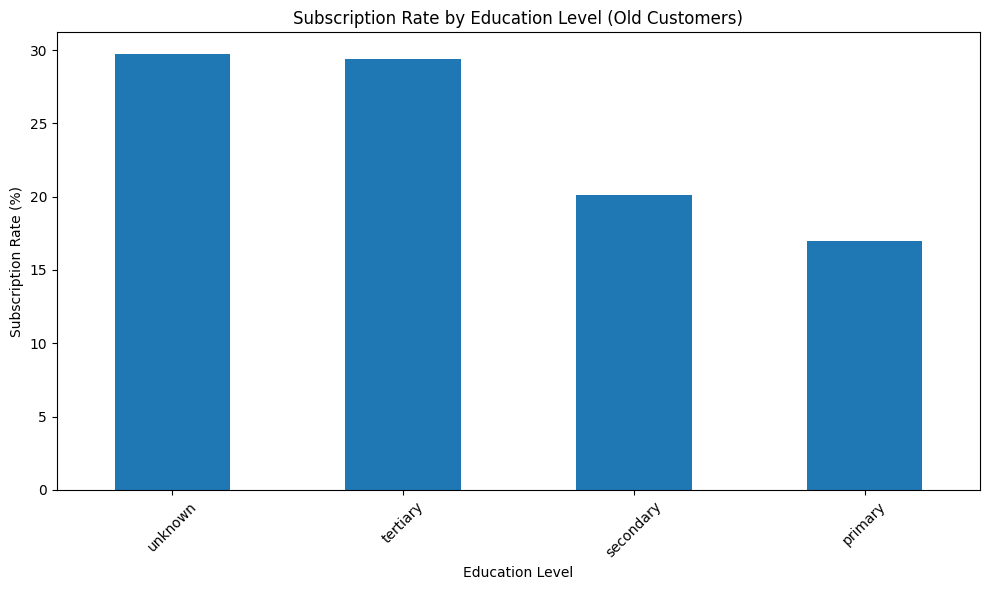

In [253]:
crosstab_education_y_old_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Education Level (Old Customers)")
plt.xlabel("Education Level")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [254]:
(
    chi2_education_y_old,
    p_education_y_old,
    dof_education_y_old,
    expected_education_y_old,
) = chi2_contingency(crosstab_education_y_old)
print(
    f"Chi-squared: {chi2_education_y_old}, p-value: {p_education_y_old}, degrees of freedom: {dof_education_y_old}"
)

Chi-squared: 109.97318242890175, p-value: 1.1120054209356035e-23, degrees of freedom: 3


In [255]:
cramer_v_education_y_old = association(crosstab_education_y_old, method="cramer")
print(f"Cramér's V: {cramer_v_education_y_old}")

Cramér's V: 0.11540702722964273


In [256]:
crosstab_education_y_new = pd.crosstab(df_new["education"], df_new["y"])
crosstab_education_y_new

y,no,yes
education,,
primary,5413,418
secondary,17353,1595
tertiary,9426,1215
unknown,1378,156


In [257]:
crosstab_education_y_new_normalized = (
    pd.crosstab(df_new["education"], df_new["y"], normalize="index") * 100
)
crosstab_education_y_new_normalized

y,no,yes
education,,
primary,92.831418,7.168582
secondary,91.582225,8.417775
tertiary,88.581900,11.418100
unknown,89.830508,10.169492


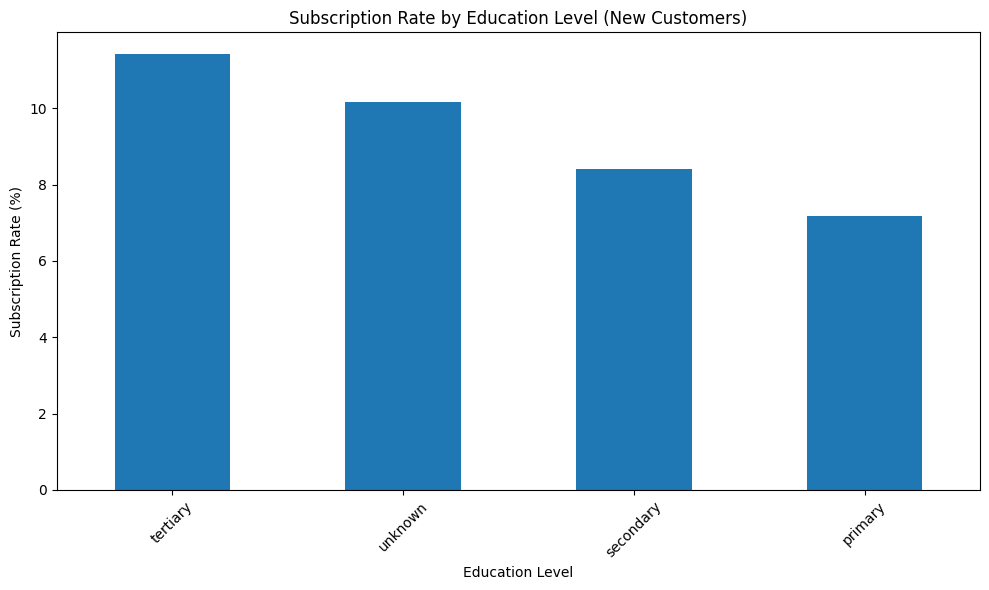

In [258]:
crosstab_education_y_new_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Education Level (New Customers)")
plt.xlabel("Education Level")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [259]:
(
    chi2_education_y_new,
    p_education_y_new,
    dof_education_y_new,
    expected_education_y_new,
) = chi2_contingency(crosstab_education_y_new)
print(
    f"Chi-squared: {chi2_education_y_new}, p-value: {p_education_y_new}, degrees of freedom: {dof_education_y_new}"
)

Chi-squared: 107.4490139005712, p-value: 3.883928838820711e-23, degrees of freedom: 3


In [260]:
cramer_v_education_y_new = association(crosstab_education_y_new, method="cramer")
print(f"Cramér's V: {cramer_v_education_y_new}")

Cramér's V: 0.05392255844609969


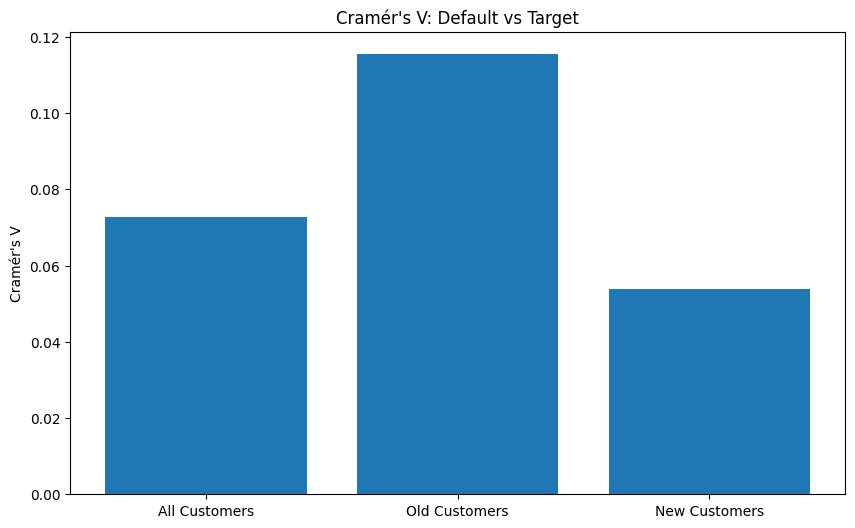

In [261]:
labels = ["All Customers", "Old Customers", "New Customers"]
values = [cramer_v_education_y, cramer_v_education_y_old, cramer_v_education_y_new]
plt.bar(labels, values)
plt.title("Cramér's V: Default vs Target")
plt.ylabel("Cramér's V")
plt.show()

We can use it for old customers but new for new ones it is negligible

##### contact and target

In [262]:
crosstab_contact_y = pd.crosstab(df["contact"], df["y"])
crosstab_contact_y

y,no,yes
contact,,
cellular,24916,4369
telephone,2516,390
unknown,12490,530


In [263]:
crosstab_contact_y_normalized = (
    pd.crosstab(df["contact"], df["y"], normalize="index") * 100
)
crosstab_contact_y_normalized

y,no,yes
contact,,
cellular,85.081100,14.918900
telephone,86.579491,13.420509
unknown,95.929339,4.070661


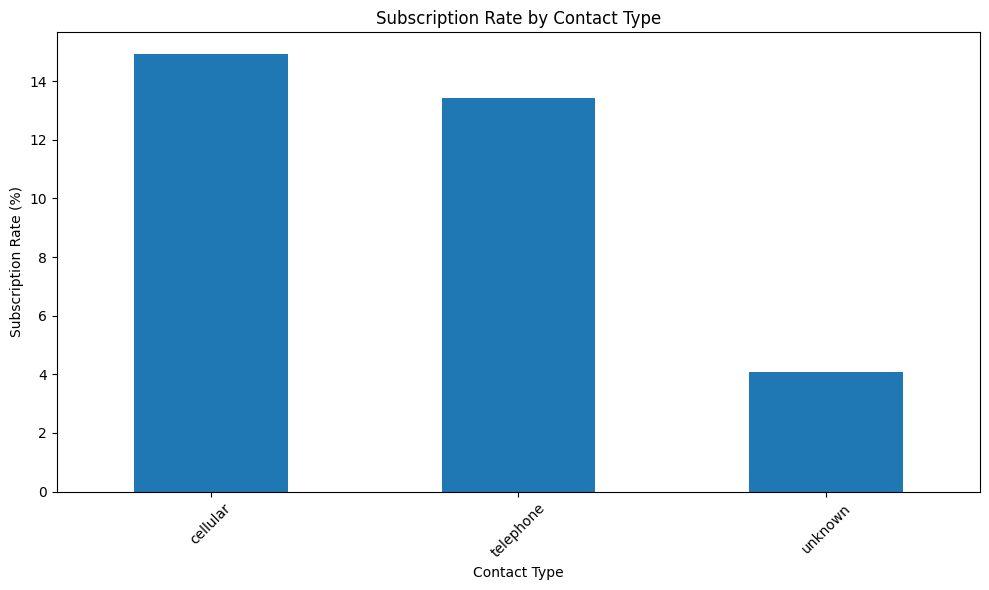

In [264]:
crosstab_contact_y_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Contact Type")
plt.xlabel("Contact Type")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [265]:
chi2_contact_y, p_contact_y, dof_contact_y, expected_contact_y = chi2_contingency(
    crosstab_contact_y
)
print(
    f"Chi-squared: {chi2_contact_y}, p-value: {p_contact_y}, degrees of freedom: {dof_contact_y}"
)

Chi-squared: 1035.714225356292, p-value: 1.251738325340638e-225, degrees of freedom: 2


In [266]:
cramer_v_contact_y = association(crosstab_contact_y, method="cramer")
print(f"Cramér's V: {cramer_v_contact_y}")

Cramér's V: 0.15135539788059024


This feature is a weak estimator, but can be used

In [267]:
crosstab_contact_y_old = pd.crosstab(df_old["contact"], df_old["y"])
crosstab_contact_y_old

y,no,yes
contact,,
cellular,5801,1755
telephone,493,138
unknown,58,12


In [268]:
crosstab_contact_y_old_normalized = (
    pd.crosstab(df_old["contact"], df_old["y"], normalize="index") * 100
)
crosstab_contact_y_old_normalized

y,no,yes
contact,,
cellular,76.773425,23.226575
telephone,78.129952,21.870048
unknown,82.857143,17.142857


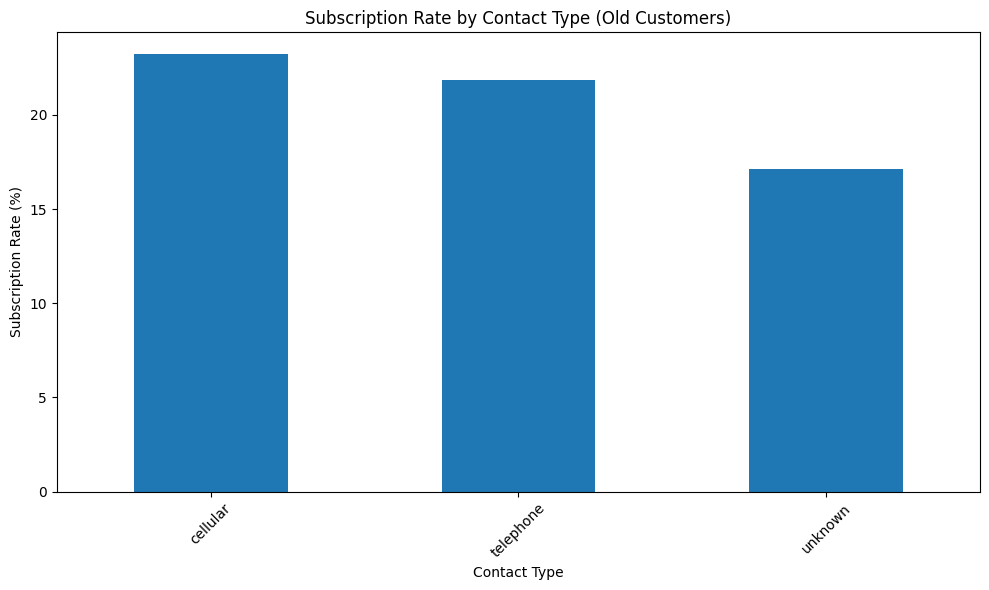

In [269]:
crosstab_contact_y_old_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Contact Type (Old Customers)")
plt.xlabel("Contact Type")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()

In [270]:
chi2_contact_y_old, p_contact_y_old, dof_contact_y_old, expected_contact_y_old = (
    chi2_contingency(crosstab_contact_y_old)
)
print(
    f"Chi-squared: {chi2_contact_y_old}, p-value: {p_contact_y_old}, degrees of freedom: {dof_contact_y_old}"
)

Chi-squared: 2.0018433711247092, p-value: 0.3675405282114111, degrees of freedom: 2


This feature has a large p value which means we can't reject the null hyphotesis. Maybe we can try to merge unknown to cellular in case we can get something from it. Because there are so few entries in unknown column, it can cause noise in this feature

In [271]:
df_old["contact"] = df_old["contact"].replace("unknown", "cellular")
crosstab_contact_y_old = pd.crosstab(df_old["contact"], df_old["y"])
chi2_contact_y_old, p_contact_y_old, dof_contact_y_old, expected_contact_y_old = (
    chi2_contingency(crosstab_contact_y_old)
)
print(
    f"Chi-squared: {chi2_contact_y_old}, p-value: {p_contact_y_old}, degrees of freedom: {dof_contact_y_old}"
)

Chi-squared: 0.4846360383966749, p-value: 0.4863298522432523, degrees of freedom: 1


It didnt change anything as I expected

In [272]:
crosstab_contact_y_new = pd.crosstab(df_new["contact"], df_new["y"])
crosstab_contact_y_new

y,no,yes
contact,,
cellular,19115,2614
telephone,2023,252
unknown,12432,518


In [273]:
crosstab_contact_y_new_normalized = (
    pd.crosstab(df_new["contact"], df_new["y"], normalize="index") * 100
)
crosstab_contact_y_new_normalized

y,no,yes
contact,,
cellular,87.969994,12.030006
telephone,88.923077,11.076923
unknown,96.000000,4.000000


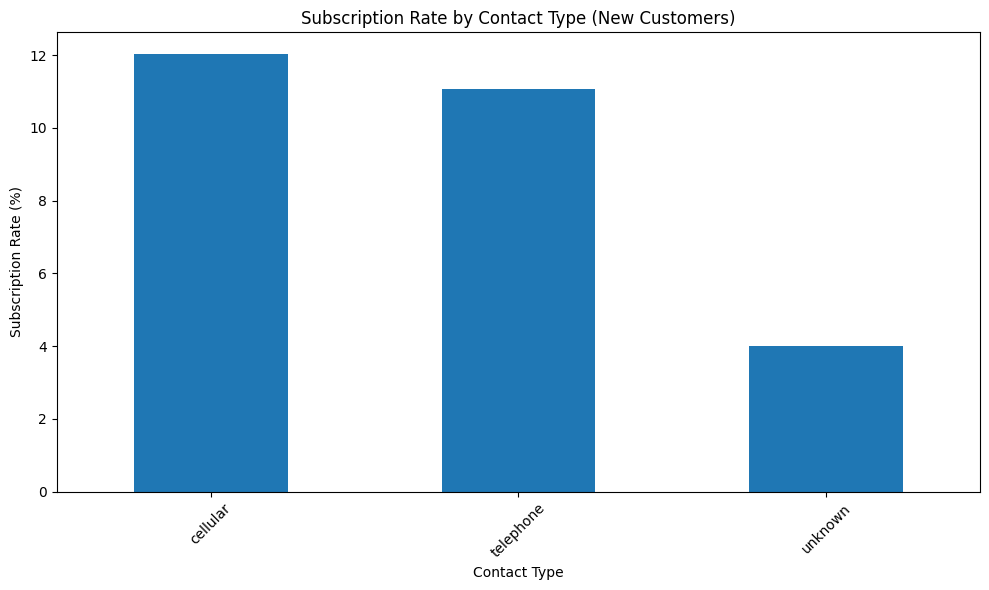

In [274]:
crosstab_contact_y_new_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Contact Type (New Customers)")
plt.xlabel("Contact Type")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()

In [275]:
chi2_contact_y_new, p_contact_y_new, dof_contact_y_new, expected_contact_y_new = (
    chi2_contingency(crosstab_contact_y_new)
)
print(
    f"Chi-squared: {chi2_contact_y_new}, p-value: {p_contact_y_new}, degrees of freedom: {dof_contact_y_new}"
)

Chi-squared: 639.6879697848196, p-value: 1.2402872844145819e-139, degrees of freedom: 2


In [276]:
cramer_v_contact_y_new = association(crosstab_contact_y_new, method="cramer")
print(f"Cramér's V: {cramer_v_contact_y_new}")

Cramér's V: 0.1315689365599323


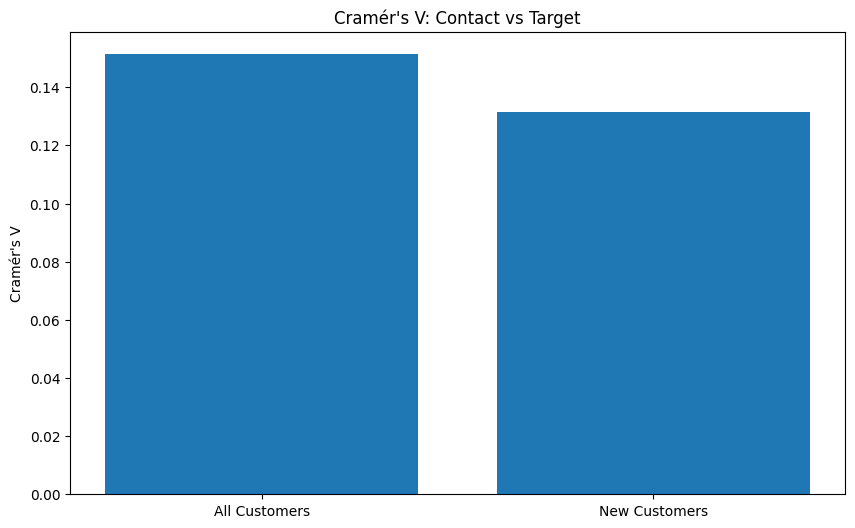

In [277]:
labels = ["All Customers", "New Customers"]
values = [cramer_v_contact_y, cramer_v_contact_y_new]
plt.bar(labels, values)
plt.title("Cramér's V: Contact vs Target")
plt.ylabel("Cramér's V")
plt.show()

Cramer's V is decreased but the feature is still usable

##### month and target

In [278]:
crosstab_month_y = pd.crosstab(df["month"], df["y"])
crosstab_month_y

y,no,yes
month,,
apr,2355,577
aug,5559,688
dec,114,100
feb,2208,441
jan,1261,142
jul,6268,627
jun,4795,546
mar,229,248
may,12841,925


In [279]:
crosstab_month_y_normalized = pd.crosstab(df["month"], df["y"], normalize="index") * 100
crosstab_month_y_normalized

y,no,yes
month,,
apr,80.320600,19.679400
aug,88.986714,11.013286
dec,53.271028,46.728972
feb,83.352208,16.647792
jan,89.878831,10.121169
jul,90.906454,9.093546
jun,89.777195,10.222805
mar,48.008386,51.991614
may,93.280546,6.719454


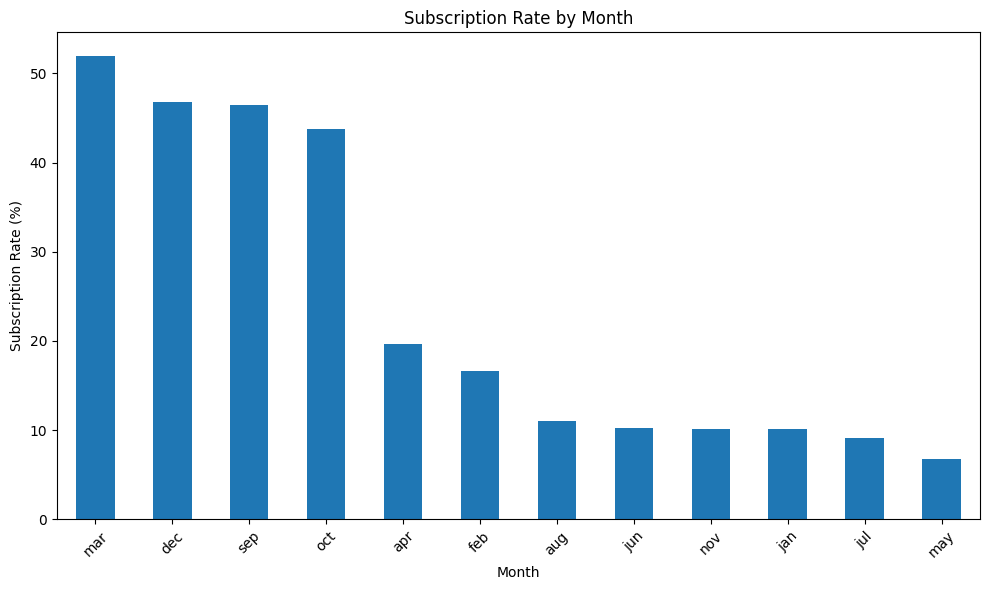

In [280]:
plt.figure(figsize=(10, 6))
crosstab_month_y_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Month")
plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [281]:
chi2_month_y, p_month_y, dof_month_y, expected_month_y = chi2_contingency(
    crosstab_month_y
)
print(
    f"Chi-squared: {chi2_month_y}, p-value: {p_month_y}, degrees of freedom: {dof_month_y}"
)

Chi-squared: 3061.838938445269, p-value: 0.0, degrees of freedom: 11


In [282]:
cramer_v_month_y = association(crosstab_month_y, method="cramer")
print(f"Cramér's V: {cramer_v_month_y}")

Cramér's V: 0.2602370422991876


This feature has a moderate predictive value and should be included for our model

In [283]:
crosstab_month_y_old = pd.crosstab(df_old["month"], df_old["y"])
crosstab_month_y_old

y,no,yes
month,,
apr,928,190
aug,297,234
dec,60,58
feb,743,181
jan,438,60
jul,118,136
jun,171,151
mar,81,92
may,2209,305


In [284]:
crosstab_month_y_old_normalized = (
    pd.crosstab(df_old["month"], df_old["y"], normalize="index") * 100
)
crosstab_month_y_old_normalized

y,no,yes
month,,
apr,83.005367,16.994633
aug,55.932203,44.067797
dec,50.847458,49.152542
feb,80.411255,19.588745
jan,87.951807,12.048193
jul,46.456693,53.543307
jun,53.105590,46.894410
mar,46.820809,53.179191
may,87.867940,12.132060


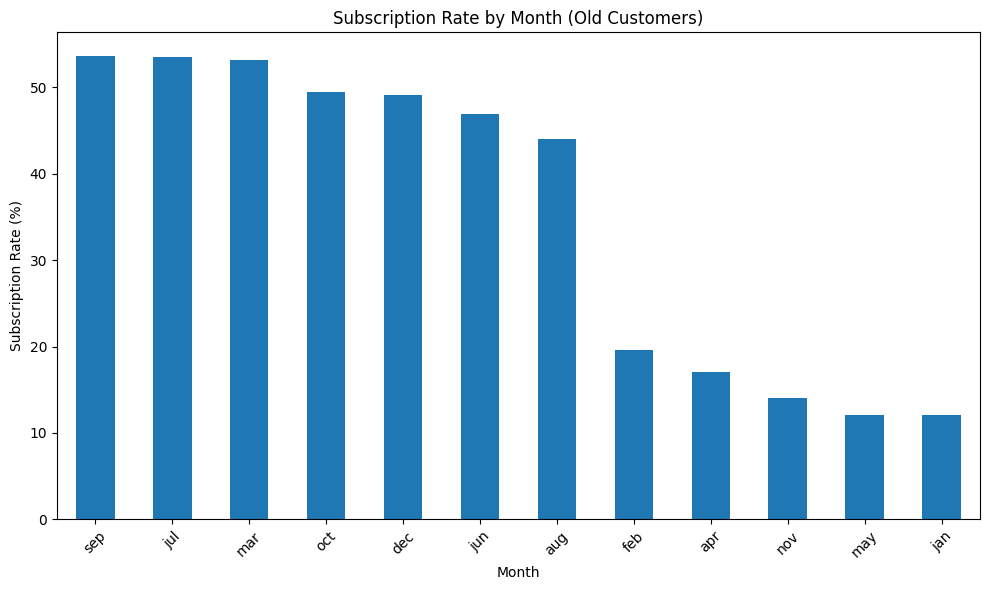

In [285]:
crosstab_month_y_old_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Month (Old Customers)")
plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [286]:
chi2_month_y_old, p_month_y_old, dof_month_y_old, expected_month_y_old = (
    chi2_contingency(crosstab_month_y_old)
)
print(
    f"Chi-squared: {chi2_month_y_old}, p-value: {p_month_y_old}, degrees of freedom: {dof_month_y_old}"
)

Chi-squared: 1086.7071316221463, p-value: 4.141563084255774e-226, degrees of freedom: 11


In [287]:
cramer_v_month_y_old = association(crosstab_month_y_old, method="cramer")
print(f"Cramér's V: {cramer_v_month_y_old}")

Cramér's V: 0.3627814867436217


In [288]:
crosstab_month_y_new = pd.crosstab(df_new["month"], df_new["y"])
crosstab_month_y_new

y,no,yes
month,,
apr,1427,387
aug,5262,454
dec,54,42
feb,1465,260
jan,823,82
jul,6150,491
jun,4624,395
mar,148,156
may,10632,620


In [289]:
crosstab_month_y_new_normalized = (
    pd.crosstab(df_new["month"], df_new["y"], normalize="index") * 100
)
crosstab_month_y_new_normalized

y,no,yes
month,,
apr,78.665932,21.334068
aug,92.057383,7.942617
dec,56.250000,43.750000
feb,84.927536,15.072464
jan,90.939227,9.060773
jul,92.606535,7.393465
jun,92.129906,7.870094
mar,48.684211,51.315789
may,94.489868,5.510132


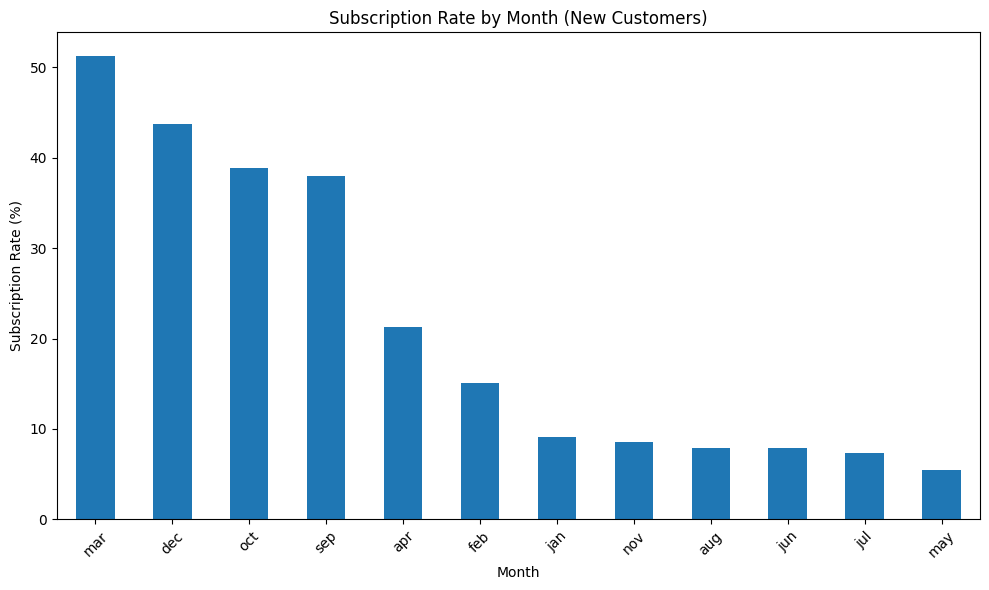

In [290]:
crosstab_month_y_new_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Month (New Customers)")
plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [291]:
chi2_month_y_new, p_month_y_new, dof_month_y_new, expected_month_y_new = (
    chi2_contingency(crosstab_month_y_new)
)
print(
    f"Chi-squared: {chi2_month_y_new}, p-value: {p_month_y_new}, degrees of freedom: {dof_month_y_new}"
)

Chi-squared: 2095.7635013178697, p-value: 0.0, degrees of freedom: 11


In [292]:
cramer_v_month_y_new = association(crosstab_month_y_new, method="cramer")
print(f"Cramér's V: {cramer_v_month_y_new}")

Cramér's V: 0.23814441953090545


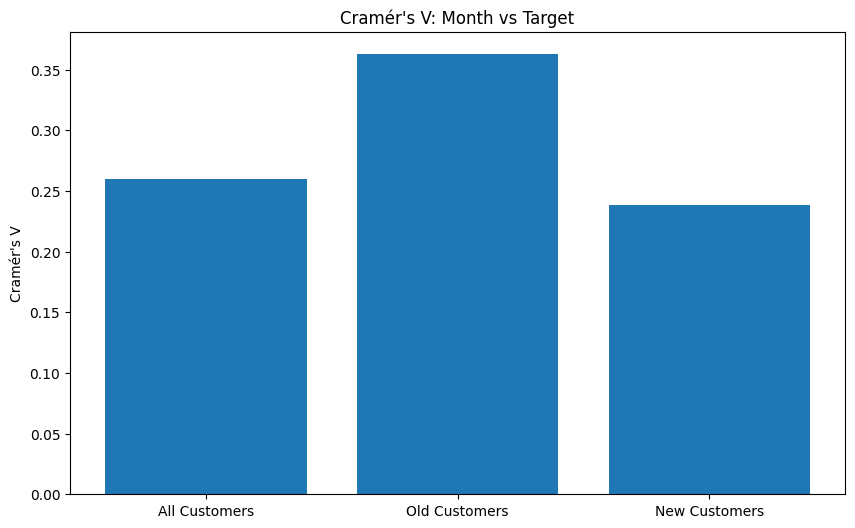

In [293]:
labels = ["All Customers", "Old Customers", "New Customers"]
values = [cramer_v_month_y, cramer_v_month_y_old, cramer_v_month_y_new]
plt.bar(labels, values)
plt.title("Cramér's V: Month vs Target")
plt.ylabel("Cramér's V")
plt.show()

There is no significant change for feature importance on new customers, but it increased for old ones as usual (due to less sample size)

##### poutcome and target

In [294]:
crosstab_poutcome_y = pd.crosstab(df["poutcome"], df["y"])
crosstab_poutcome_y

y,no,yes
poutcome,,
failure,4283,618
other,1533,307
success,533,978
unknown,33573,3386


In [295]:
crosstab_poutcome_y_normalized = (
    pd.crosstab(df["poutcome"], df["y"], normalize="index") * 100
)
crosstab_poutcome_y_normalized

y,no,yes
poutcome,,
failure,87.390329,12.609671
other,83.315217,16.684783
success,35.274653,64.725347
unknown,90.838497,9.161503


We can see that there is a correlation between previous outcome and our target

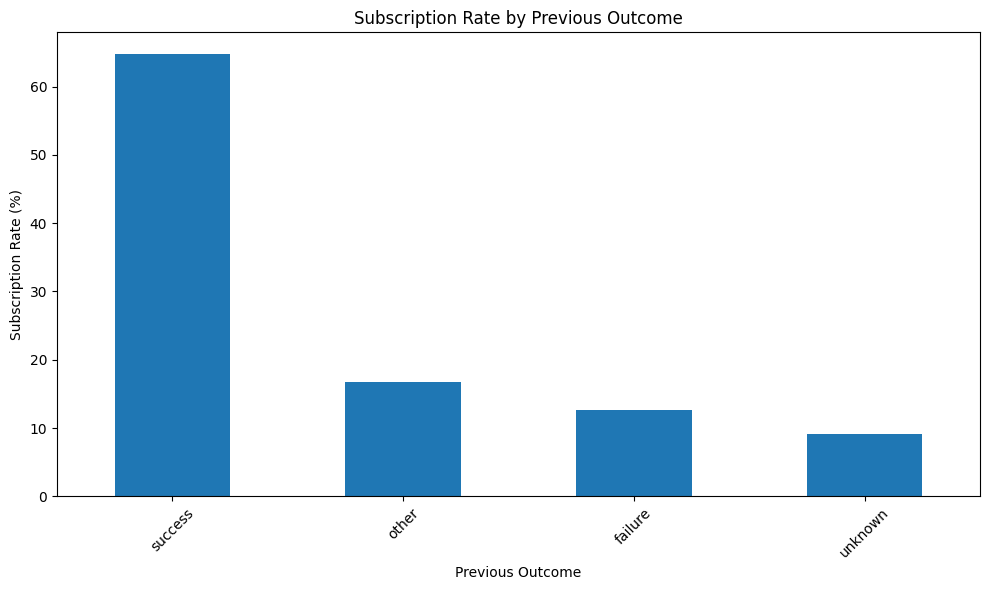

In [296]:
plt.figure(figsize=(10, 6))
crosstab_poutcome_y_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Previous Outcome")
plt.xlabel("Previous Outcome")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [297]:
chi2_poutcome_y, p_poutcome_y, dof_poutcome_y, expected_poutcome_y = chi2_contingency(
    crosstab_poutcome_y
)
print(
    f"Chi-squared: {chi2_poutcome_y}, p-value: {p_poutcome_y}, degrees of freedom: {dof_poutcome_y}"
)

Chi-squared: 4391.5065887686615, p-value: 0.0, degrees of freedom: 3


In [298]:
cramer_v_poutcome_y = association(crosstab_poutcome_y, method="cramer")
print(f"Cramér's V: {cramer_v_poutcome_y}")

Cramér's V: 0.3116626167998104


It is again a moderate predictor, but i think it is worth to see the results of bivariate analysis based on old and new customers.

In [299]:
crosstab_poutcome_y_old = pd.crosstab(df_old["poutcome"], df_old["y"])
crosstab_poutcome_y_old

y,no,yes
poutcome,,
failure,4283,618
other,1536,309
success,533,978


In [300]:
crosstab_poutcome_y_old_normalized = (
    pd.crosstab(df_old["poutcome"], df_old["y"], normalize="index") * 100
)
crosstab_poutcome_y_old_normalized

y,no,yes
poutcome,,
failure,87.390329,12.609671
other,83.252033,16.747967
success,35.274653,64.725347


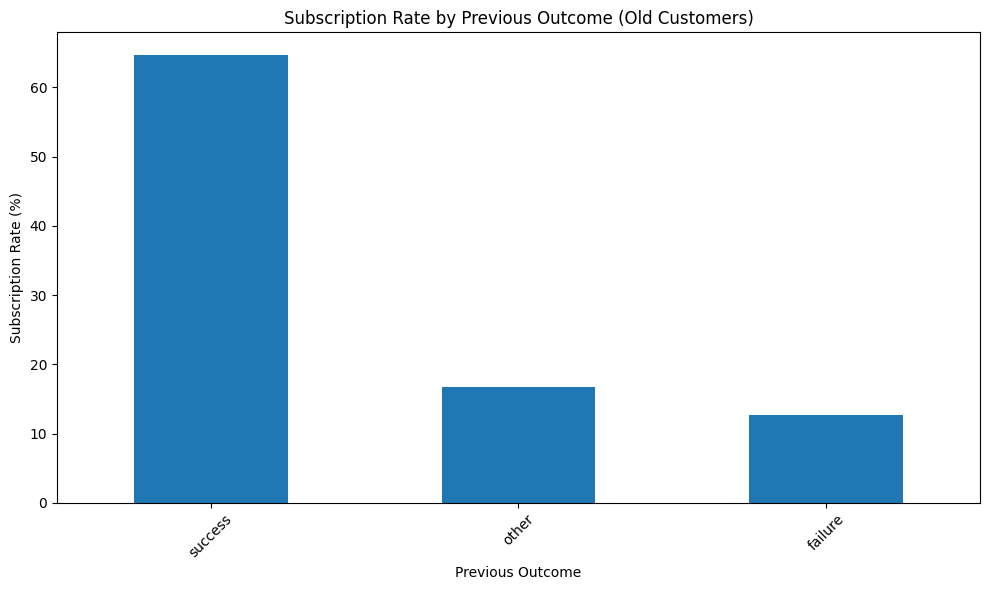

In [301]:
crosstab_poutcome_y_old_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Previous Outcome (Old Customers)")
plt.xlabel("Previous Outcome")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [302]:
chi2_poutcome_y_old, p_poutcome_y_old, dof_poutcome_y_old, expected_poutcome_y_old = (
    chi2_contingency(crosstab_poutcome_y_old)
)
print(
    f"Chi-squared: {chi2_poutcome_y_old}, p-value: {p_poutcome_y_old}, degrees of freedom: {dof_poutcome_y_old}"
)

Chi-squared: 1820.9118938752586, p-value: 0.0, degrees of freedom: 2


In [303]:
cramer_v_poutcome_y_old = association(crosstab_poutcome_y_old, method="cramer")
print(f"Cramér's V: {cramer_v_poutcome_y_old}")

Cramér's V: 0.46960566146170696


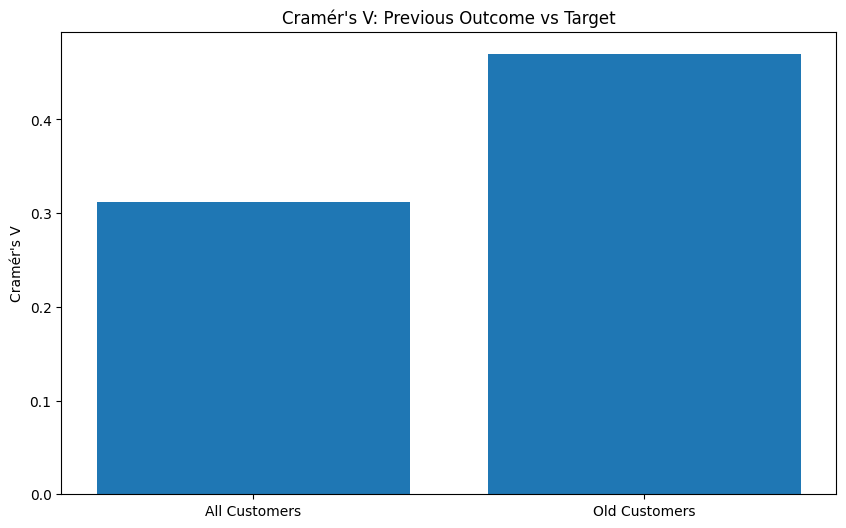

In [304]:
labels = ["All Customers", "Old Customers"]
values = [cramer_v_poutcome_y, cramer_v_poutcome_y_old]
plt.bar(labels, values)
plt.title("Cramér's V: Previous Outcome vs Target")
plt.ylabel("Cramér's V")
plt.show()

Filtering new customers has increased feature importance significantly

#### Numerical Features and Target

##### age and target

In [305]:
age_grouped_by_y = df.groupby("y")["age"].describe()
age_grouped_by_y

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,39922.0,40.838986,10.172662,18.0,33.0,39.0,48.0,95.0
yes,5289.0,41.670070,13.497781,18.0,31.0,38.0,50.0,95.0


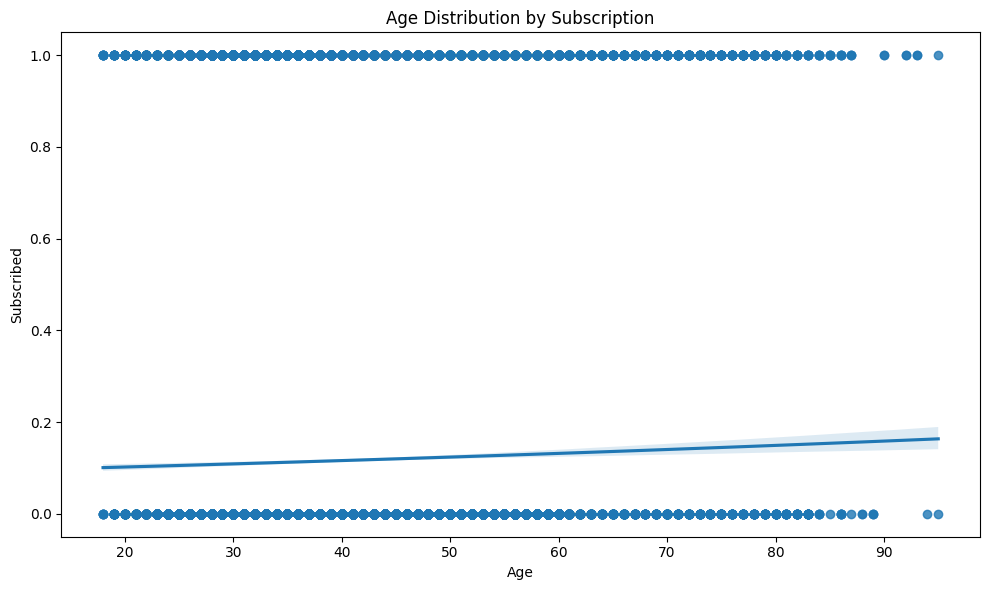

In [306]:
sns.regplot(data=df, x="age", y="y_numeric", logistic=True)
plt.title("Age Distribution by Subscription")
plt.xlabel("Age")
plt.ylabel("Subscribed")
plt.tight_layout()
plt.show()

In [307]:
r_spearman_age_y = df["age"].corr(df["y_numeric"], method="spearman")
r_age_y_squared = r_spearman_age_y**2
print(f"Spearman Correlation (r): {r_spearman_age_y:.4f}")
print(f"Variance in subscription explained by age: {r_age_y_squared * 100:.2f}%")

Spearman Correlation (r): -0.0087
Variance in subscription explained by age: 0.01%


Age does not have a linear relationship with target, so it is better to analyse it as a categorical variable using binning.

In [308]:
df["age_binned"] = pd.cut(
    df["age"], bins=[17, 30, 45, 60, 95], labels=["18-30", "31-45", "46-60", "60+"]
)
df["age_binned"].value_counts().sort_index()

age_binned
18-30     7030
31-45    23733
46-60    13260
60+       1188
Name: count, dtype: int64

In [309]:
crosstab_age_binned_y = pd.crosstab(df["age_binned"], df["y"])
crosstab_age_binned_y

y,no,yes
age_binned,,
18-30,5885,1145
31-45,21388,2345
46-60,11963,1297
60+,686,502


In [310]:
crosstab_age_binned_y_normalized = (
    pd.crosstab(df["age_binned"], df["y"], normalize="index") * 100
)
crosstab_age_binned_y_normalized

y,no,yes
age_binned,,
18-30,83.712660,16.287340
31-45,90.119243,9.880757
46-60,90.218703,9.781297
60+,57.744108,42.255892


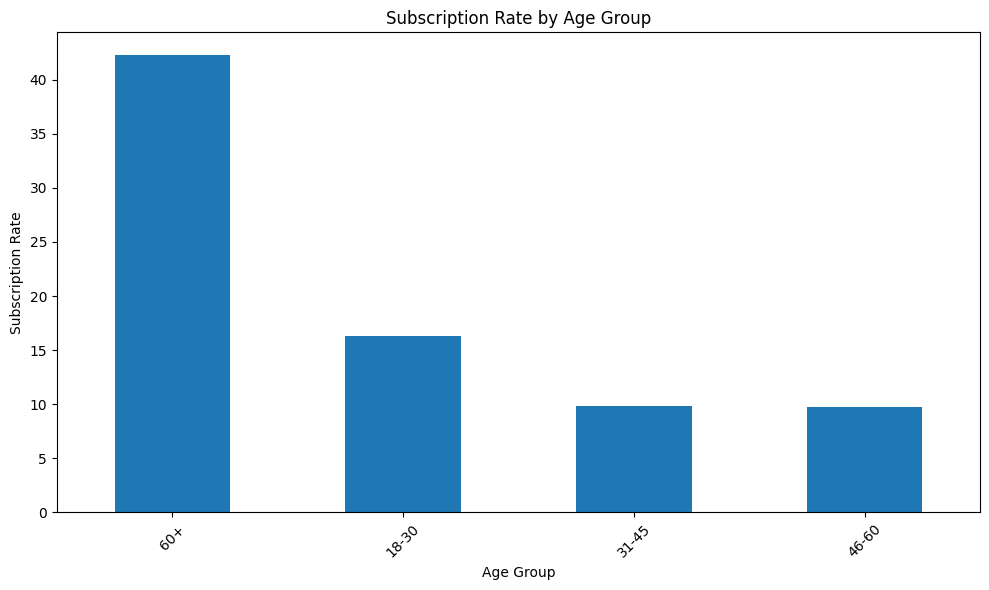

In [311]:
crosstab_age_binned_y_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [312]:
chi2_age_binned_y, p_age_binned_y, dof_age_binned_y, expected_age_binned_y = (
    chi2_contingency(crosstab_age_binned_y)
)
print(
    f"Chi-squared: {chi2_age_binned_y}, p-value: {p_age_binned_y}, degrees of freedom: {dof_age_binned_y}"
)

Chi-squared: 1340.271226491967, p-value: 2.6894354297895764e-290, degrees of freedom: 3


In [313]:
cramer_v_age_binned_y = association(crosstab_age_binned_y, method="cramer")
print(f"Cramér's V: {cramer_v_age_binned_y}")

Cramér's V: 0.17217666462621373


It has a predictive value in this case

In [314]:
df_old["age_binned"] = pd.cut(
    df_old["age"], bins=[17, 30, 45, 60, 95], labels=["18-30", "31-45", "46-60", "60+"]
)
df_old["age_binned"].value_counts().sort_index()

age_binned
18-30    1288
31-45    4481
46-60    2052
60+       436
Name: count, dtype: int64

In [315]:
crosstab_age_binned_y_old = pd.crosstab(df_old["age_binned"], df_old["y"])
crosstab_age_binned_y_old

y,no,yes
age_binned,,
18-30,916,372
31-45,3632,849
46-60,1586,466
60+,218,218


In [316]:
crosstab_age_binned_y_old_normalized = (
    pd.crosstab(df_old["age_binned"], df_old["y"], normalize="index") * 100
)
crosstab_age_binned_y_old_normalized

y,no,yes
age_binned,,
18-30,71.118012,28.881988
31-45,81.053336,18.946664
46-60,77.290448,22.709552
60+,50.000000,50.000000


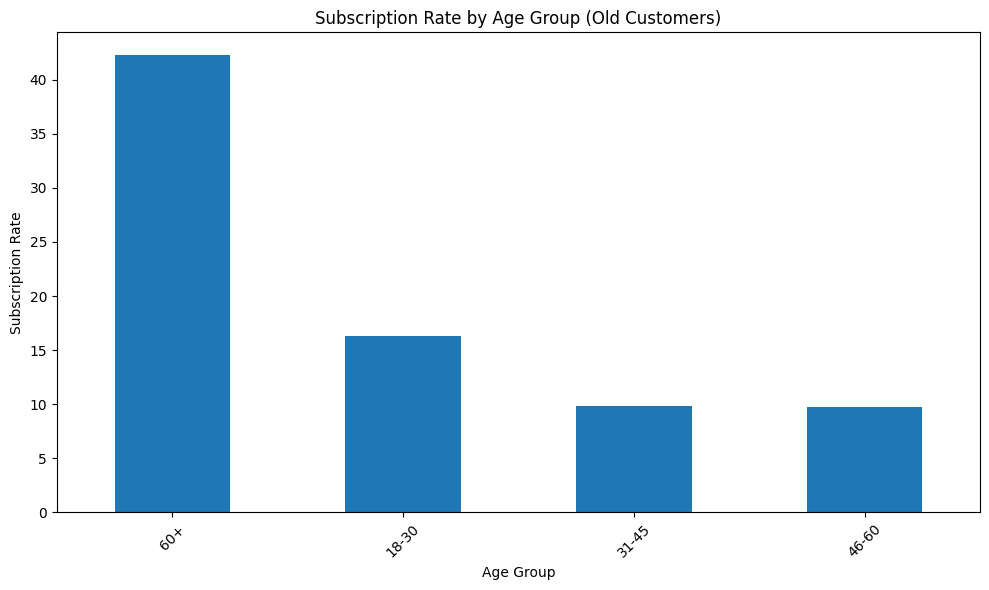

In [317]:
crosstab_age_binned_y_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Age Group (Old Customers)")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [318]:
(
    chi2_age_binned_y_old,
    p_age_binned_y_old,
    dof_age_binned_y_old,
    expected_age_binned_y_old,
) = chi2_contingency(crosstab_age_binned_y_old)
print(
    f"Chi-squared: {chi2_age_binned_y_old}, p-value: {p_age_binned_y_old}, degrees of freedom: {dof_age_binned_y_old}"
)

Chi-squared: 245.74388539614236, p-value: 5.449182198310473e-53, degrees of freedom: 3


In [319]:
cramer_v_age_binned_y_old = association(crosstab_age_binned_y_old, method="cramer")
print(f"Cramér's V: {cramer_v_age_binned_y_old}")

Cramér's V: 0.17251633289399657


In [320]:
df_new["age_binned"] = pd.cut(
    df_new["age"], bins=[17, 30, 45, 60, 95], labels=["18-30", "31-45", "46-60", "60+"]
)
df_new["age_binned"].value_counts().sort_index()

age_binned
18-30     5742
31-45    19252
46-60    11208
60+        752
Name: count, dtype: int64

In [321]:
crosstab_age_binned_y_new = pd.crosstab(df_new["age_binned"], df_new["y"])
crosstab_age_binned_y_new

y,no,yes
age_binned,,
18-30,4969,773
31-45,17756,1496
46-60,10377,831
60+,468,284


In [322]:
crosstab_age_binned_y_new_normalized = (
    pd.crosstab(df_new["age_binned"], df_new["y"], normalize="index") * 100
)
crosstab_age_binned_y_new_normalized

y,no,yes
age_binned,,
18-30,86.537792,13.462208
31-45,92.229379,7.770621
46-60,92.585653,7.414347
60+,62.234043,37.765957


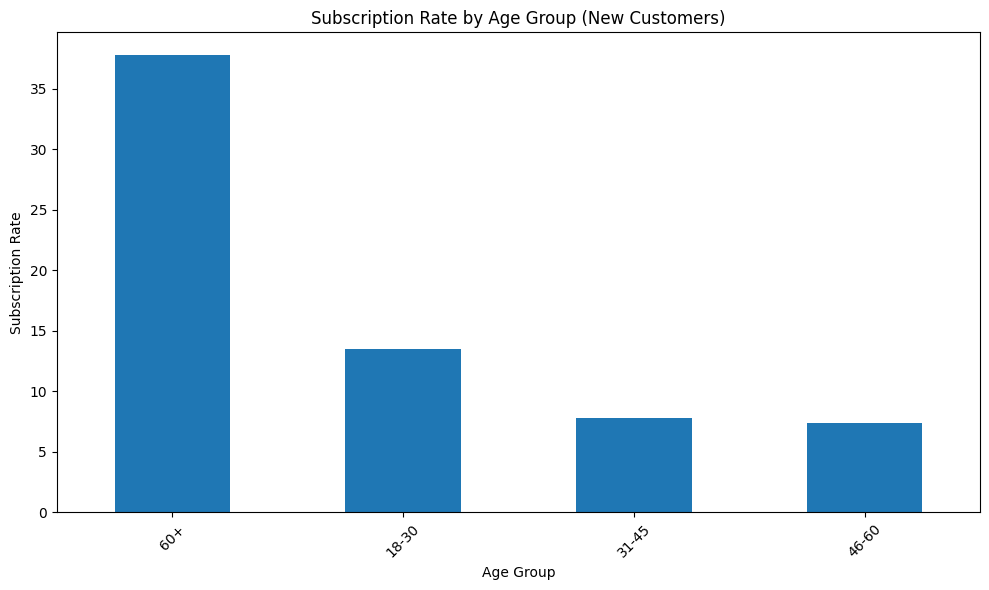

In [323]:
crosstab_age_binned_y_new_normalized["yes"].sort_values(ascending=False).plot(
    kind="bar"
)
plt.title("Subscription Rate by Age Group (New Customers)")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [324]:
(
    chi2_age_binned_y_new,
    p_age_binned_y_new,
    dof_age_binned_y_new,
    expected_age_binned_y_new,
) = chi2_contingency(crosstab_age_binned_y_new)
print(
    f"Chi-squared: {chi2_age_binned_y_new}, p-value: {p_age_binned_y_new}, degrees of freedom: {dof_age_binned_y_new}"
)

Chi-squared: 953.2165669396304, p-value: 2.5330467587773064e-206, degrees of freedom: 3


In [325]:
cramer_v_age_binned_y_new = association(crosstab_age_binned_y_new, method="cramer")
print(f"Cramér's V: {cramer_v_age_binned_y_new}")

Cramér's V: 0.1606072195688534


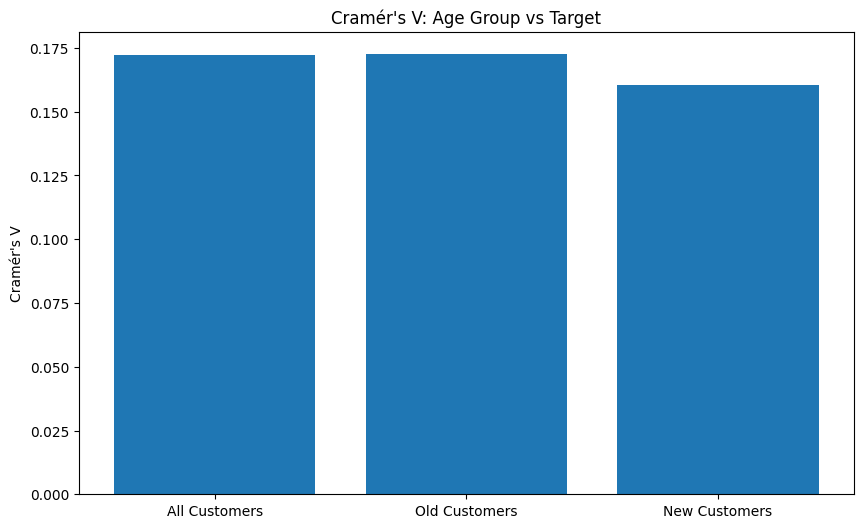

In [326]:
labels = ["All Customers", "Old Customers", "New Customers"]
values = [cramer_v_age_binned_y, cramer_v_age_binned_y_old, cramer_v_age_binned_y_new]
plt.bar(labels, values)
plt.title("Cramér's V: Age Group vs Target")
plt.ylabel("Cramér's V")
plt.show()

It didnt change much after seperation

##### balance and target

In [327]:
balance_grouped_by_y = df.groupby("y")["balance"].describe()
balance_grouped_by_y

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,39922.0,1303.714969,2974.195473,-8019.0,58.0,417.0,1345.0,102127.0
yes,5289.0,1804.267915,3501.104777,-3058.0,210.0,733.0,2159.0,81204.0


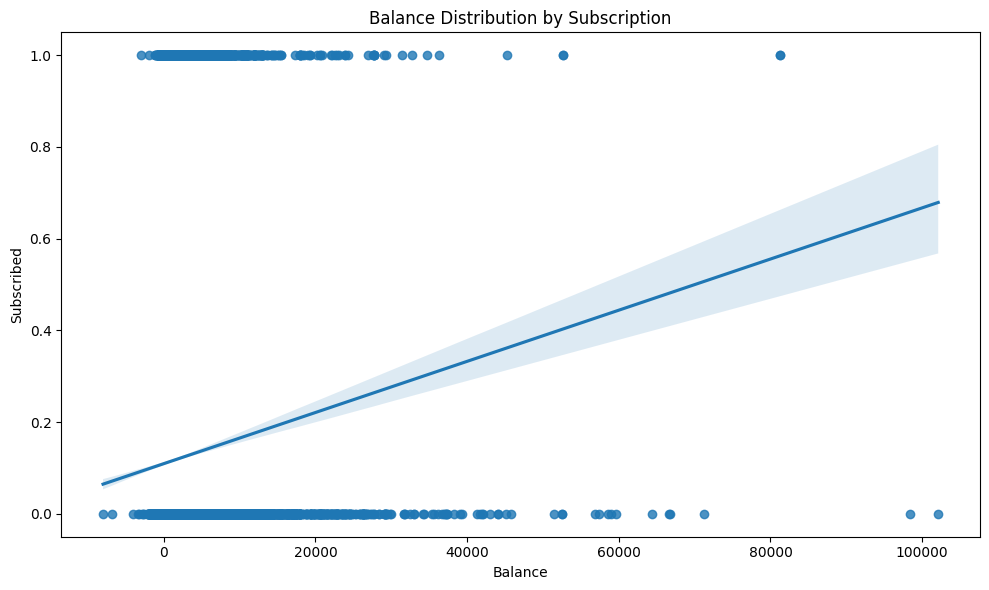

In [328]:
sns.regplot(data=df, x="balance", y="y_numeric")
plt.title("Balance Distribution by Subscription")
plt.xlabel("Balance")
plt.ylabel("Subscribed")
plt.tight_layout()
plt.show()

In [329]:
r_balance_y = df["balance"].corr(df["y_numeric"])
r_balance_y_squared = r_balance_y**2
print(f"Pearson Correlation (r): {r_balance_y:.4f}")
print(
    f"Variance in subscription explained by balance: {r_balance_y_squared * 100:.2f}%"
)

Pearson Correlation (r): 0.0528
Variance in subscription explained by balance: 0.28%


Again we can try binning to determine whether this feature worth to include or not

In [330]:
df["balance_binned"] = pd.cut(
    df["balance"],
    bins=[-10000, 0, 500, 2000, 111111],
    labels=["Debt", "Low", "Medium", "High"],
)
df["balance_binned"].value_counts().sort_index()

balance_binned
Debt       7280
Low       16385
Medium    13045
High       8501
Name: count, dtype: int64

In [331]:
crosstab_balance_binned_y = pd.crosstab(df["balance_binned"], df["y"])
crosstab_balance_binned_y

y,no,yes
balance_binned,,
Debt,6778,502
Low,14705,1680
Medium,11347,1698
High,7092,1409


In [332]:
crosstab_balance_binned_y_normalized = (
    pd.crosstab(df["balance_binned"], df["y"], normalize="index") * 100
)
crosstab_balance_binned_y_normalized

y,no,yes
balance_binned,,
Debt,93.104396,6.895604
Low,89.746720,10.253280
Medium,86.983519,13.016481
High,83.425479,16.574521


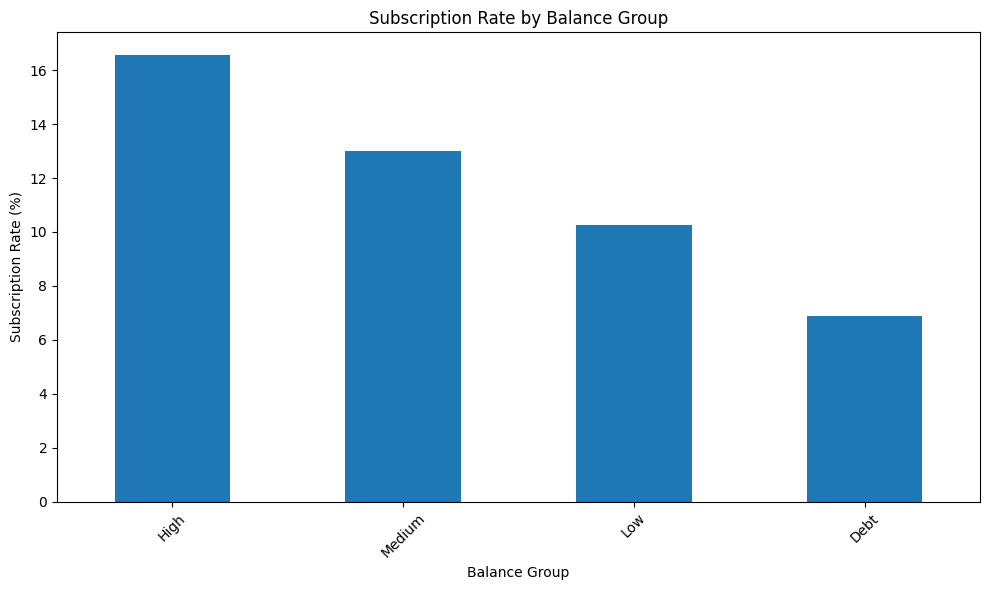

In [333]:
crosstab_balance_binned_y_normalized["yes"].sort_values(ascending=False).plot(
    kind="bar"
)
plt.title("Subscription Rate by Balance Group")
plt.xlabel("Balance Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [334]:
(
    chi2_balance_binned_y,
    p_balance_binned_y,
    dof_balance_binned_y,
    expected_balance_binned_y,
) = chi2_contingency(crosstab_balance_binned_y)
print(
    f"Chi-squared: {chi2_balance_binned_y}, p-value: {p_balance_binned_y}, degrees of freedom: {dof_balance_binned_y}"
)

Chi-squared: 413.2965026045788, p-value: 2.9169078534298384e-89, degrees of freedom: 3


In [335]:
cramer_v_balance_binned_y = association(crosstab_balance_binned_y, method="cramer")
print(f"Cramér's V: {cramer_v_balance_binned_y}")

Cramér's V: 0.09561120871328702


In [336]:
df_old["balance_binned"] = pd.cut(
    df_old["balance"],
    bins=[-10000, 0, 500, 2000, 111111],
    labels=["Debt", "Low", "Medium", "High"],
)
crosstab_balance_binned_y_old = pd.crosstab(df_old["balance_binned"], df_old["y"])
crosstab_balance_binned_y_old

y,no,yes
balance_binned,,
Debt,804,133
Low,2233,585
Medium,2048,629
High,1267,558


In [337]:
crosstab_balance_binned_y_old_normalized = (
    pd.crosstab(df_old["balance_binned"], df_old["y"], normalize="index") * 100
)
crosstab_balance_binned_y_old_normalized

y,no,yes
balance_binned,,
Debt,85.805763,14.194237
Low,79.240596,20.759404
Medium,76.503549,23.496451
High,69.424658,30.575342


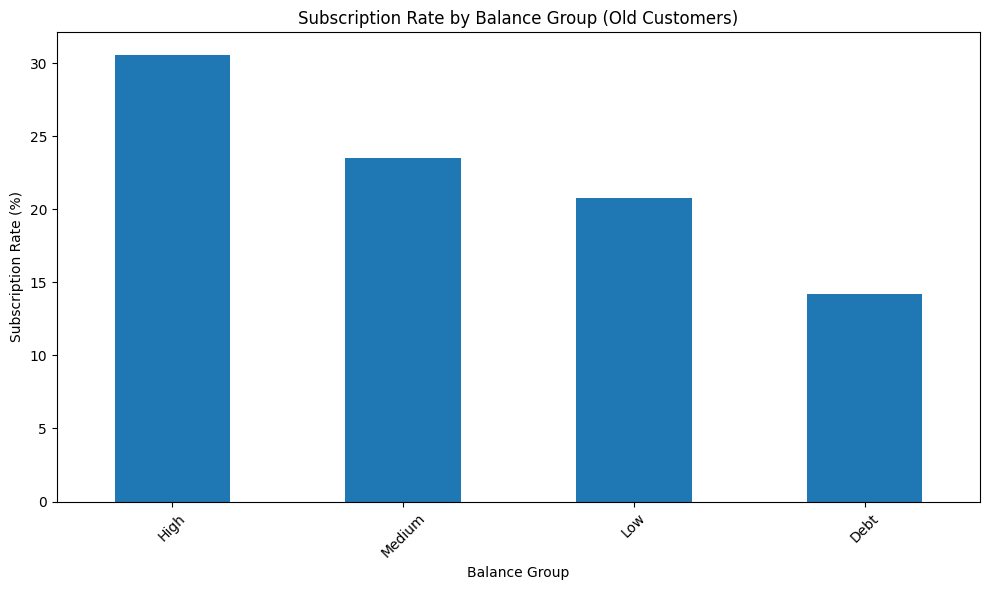

In [338]:
crosstab_balance_binned_y_old_normalized["yes"].sort_values(ascending=False).plot(
    kind="bar"
)
plt.title("Subscription Rate by Balance Group (Old Customers)")
plt.xlabel("Balance Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [339]:
(
    chi2_balance_binned_y_old,
    p_balance_binned_y_old,
    dof_balance_binned_y_old,
    expected_balance_binned_y_old,
) = chi2_contingency(crosstab_balance_binned_y_old)
print(
    f"Chi-squared: {chi2_balance_binned_y_old}, p-value: {p_balance_binned_y_old}, degrees of freedom: {dof_balance_binned_y_old}"
)

Chi-squared: 108.26305723699886, p-value: 2.5948565137947584e-23, degrees of freedom: 3


In [340]:
cramer_v_balance_binned_y_old = association(
    crosstab_balance_binned_y_old, method="cramer"
)
print(f"Cramér's V: {cramer_v_balance_binned_y_old}")

Cramér's V: 0.11450619967265213


In [341]:
df_new["balance_binned"] = pd.cut(
    df_new["balance"],
    bins=[-10000, 0, 500, 2000, 111111],
    labels=["Debt", "Low", "Medium", "High"],
)
crosstab_balance_binned_y_new = pd.crosstab(df_new["balance_binned"], df_new["y"])
crosstab_balance_binned_y_new

y,no,yes
balance_binned,,
Debt,5974,369
Low,12472,1095
Medium,9299,1069
High,5825,851


In [342]:
crosstab_balance_binned_y_new_normalized = (
    pd.crosstab(df_new["balance_binned"], df_new["y"], normalize="index") * 100
)
crosstab_balance_binned_y_new_normalized

y,no,yes
balance_binned,,
Debt,94.182563,5.817437
Low,91.928945,8.071055
Medium,89.689429,10.310571
High,87.252846,12.747154


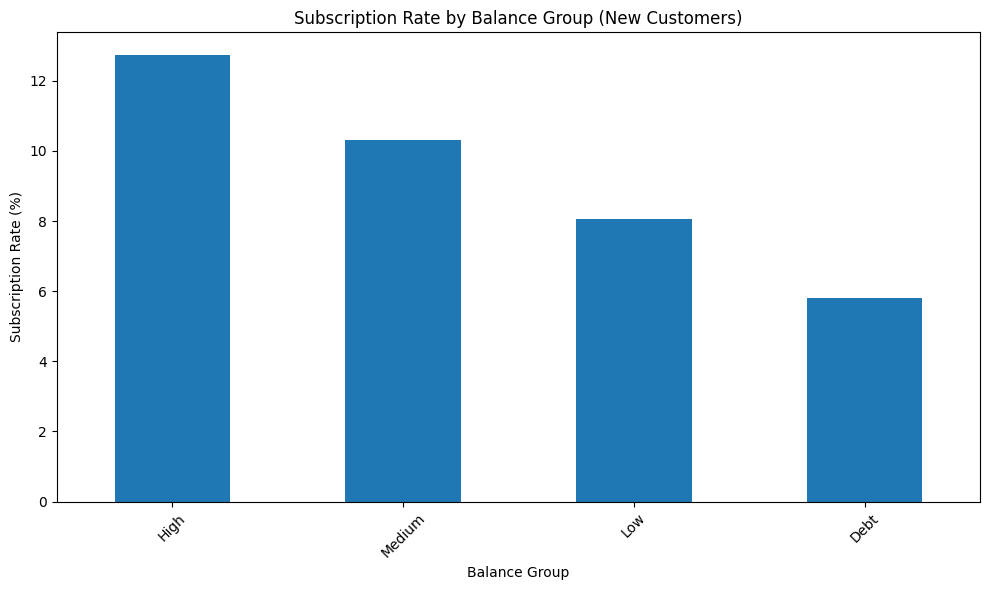

In [343]:
crosstab_balance_binned_y_new_normalized["yes"].sort_values(ascending=False).plot(
    kind="bar"
)
plt.title("Subscription Rate by Balance Group (New Customers)")
plt.xlabel("Balance Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [344]:
(
    chi2_balance_binned_y_new,
    p_balance_binned_y_new,
    dof_balance_binned_y_new,
    expected_balance_binned_y_new,
) = chi2_contingency(crosstab_balance_binned_y_new)
print(
    f"Chi-squared: {chi2_balance_binned_y_new}, p-value: {p_balance_binned_y_new}, degrees of freedom: {dof_balance_binned_y_new}"
)

Chi-squared: 224.2953813291307, p-value: 2.366739662790645e-48, degrees of freedom: 3


In [345]:
cramer_v_balance_binned_y_new = association(
    crosstab_balance_binned_y_new, method="cramer"
)
print(f"Cramér's V: {cramer_v_balance_binned_y_new}")

Cramér's V: 0.0779075304553342


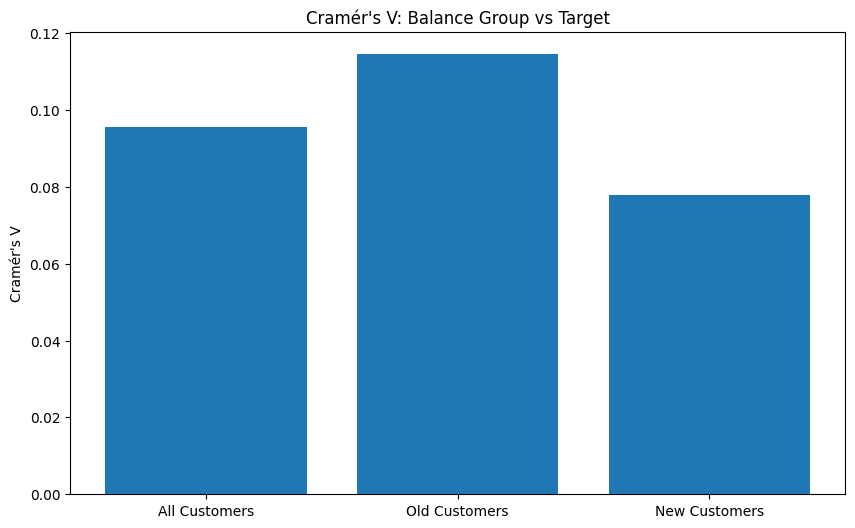

In [346]:
labels = ["All Customers", "Old Customers", "New Customers"]
values = [
    cramer_v_balance_binned_y,
    cramer_v_balance_binned_y_old,
    cramer_v_balance_binned_y_new,
]
plt.bar(labels, values)
plt.title("Cramér's V: Balance Group vs Target")
plt.ylabel("Cramér's V")
plt.show()

It makes sense to keep this feature for old customers, but not for new ones

##### day and target

In [347]:
day_grouped_by_y = df.groupby("y")["day"].describe()
day_grouped_by_y

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,39922.0,15.892290,8.294728,1.0,8.0,16.0,21.0,31.0
yes,5289.0,15.158253,8.501875,1.0,8.0,15.0,22.0,31.0


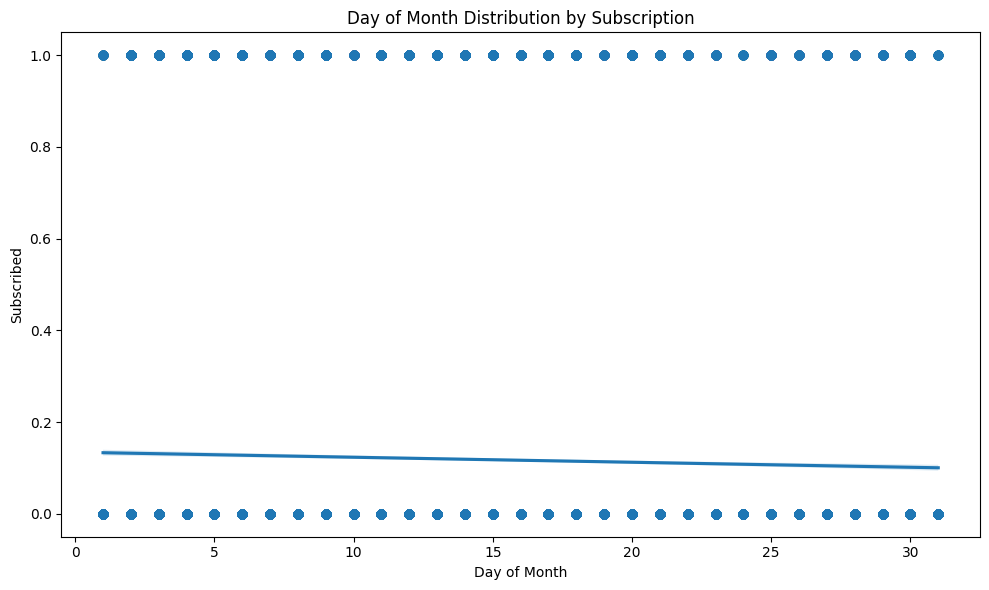

In [348]:
sns.regplot(data=df, x="day", y="y_numeric")
plt.title("Day of Month Distribution by Subscription")
plt.xlabel("Day of Month")
plt.ylabel("Subscribed")
plt.tight_layout()
plt.show()

In [349]:
r_day_y = df["day"].corr(df["y_numeric"])
r_day_y_squared = r_day_y**2
print(f"Pearson Correlation (r): {r_day_y:.4f}")
print(
    f"Variance in subscription explained by day of month: {r_day_y_squared * 100:.2f}%"
)

Pearson Correlation (r): -0.0283
Variance in subscription explained by day of month: 0.08%


The line is nearly flat, which shows that there is no linear relationship. Nevetheless we should also check for non-linear relationship using binning and Cramer's V

In [350]:
df["day_binned"] = pd.cut(
    df["day"], bins=[0, 10, 20, 31], labels=["Early", "Mid", "Late"]
)
df["day_binned"].value_counts().sort_index()

day_binned
Early    13725
Mid      18389
Late     13097
Name: count, dtype: int64

In [351]:
crosstab_day_binned_y = pd.crosstab(df["day_binned"], df["y"])
crosstab_day_binned_y

y,no,yes
day_binned,,
Early,11991,1734
Mid,16365,2024
Late,11566,1531


In [352]:
crosstab_day_binned_y_normalized = (
    pd.crosstab(df["day_binned"], df["y"], normalize="index") * 100
)
crosstab_day_binned_y_normalized

y,no,yes
day_binned,,
Early,87.36612,12.63388
Mid,88.99342,11.00658
Late,88.31030,11.68970


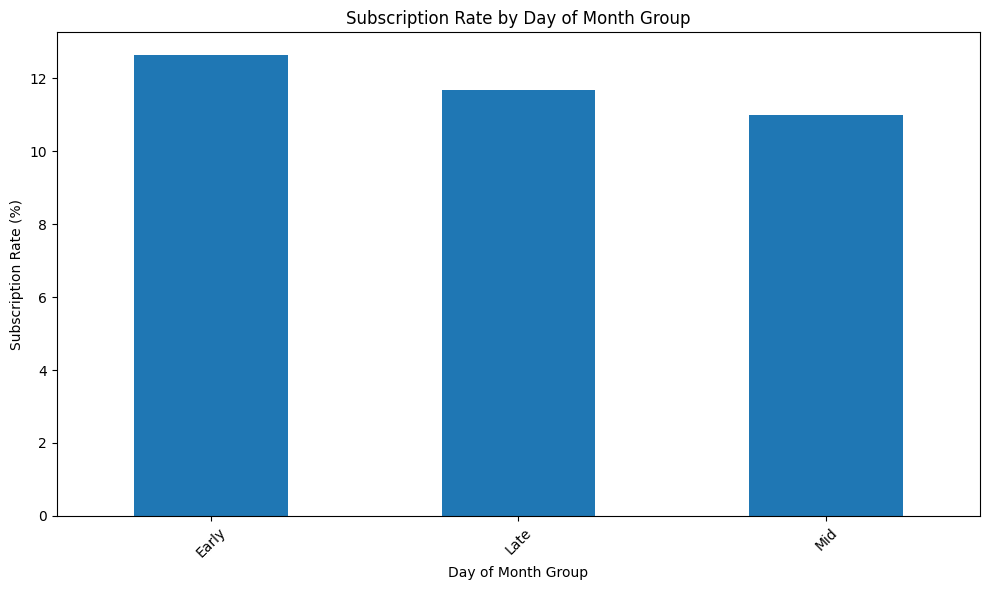

In [353]:
crosstab_day_binned_y_normalized["yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Subscription Rate by Day of Month Group")
plt.xlabel("Day of Month Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [354]:
chi2_day_binned_y, p_day_binned_y, dof_day_binned_y, expected_day_binned_y = (
    chi2_contingency(crosstab_day_binned_y)
)
print(
    f"Chi-squared: {chi2_day_binned_y}, p-value: {p_day_binned_y}, degrees of freedom: {dof_day_binned_y}"
)

Chi-squared: 20.148523041739182, p-value: 4.2150604968404854e-05, degrees of freedom: 2


In [355]:
cramer_v_day_binned_y = association(crosstab_day_binned_y, method="cramer")
print(f"Cramér's V: {cramer_v_day_binned_y}")

Cramér's V: 0.021110550162574602


It is so weak feature and probably does not worth to add our model. But i want to check its importance for old customers

In [356]:
df_old["day_binned"] = pd.cut(
    df_old["day"], bins=[0, 10, 20, 31], labels=["Early", "Mid", "Late"]
)
df_old["day_binned"].value_counts().sort_index()

day_binned
Early    2717
Mid      3887
Late     1653
Name: count, dtype: int64

In [357]:
crosstab_day_binned_y_old = pd.crosstab(df_old["day_binned"], df_old["y"])
crosstab_day_binned_y_old

y,no,yes
day_binned,,
Early,2065,652
Mid,3173,714
Late,1114,539


In [358]:
crosstab_day_binned_y_old_normalized = (
    pd.crosstab(df_old["day_binned"], df_old["y"], normalize="index") * 100
)
crosstab_day_binned_y_old_normalized

y,no,yes
day_binned,,
Early,76.002944,23.997056
Mid,81.631078,18.368922
Late,67.392619,32.607381


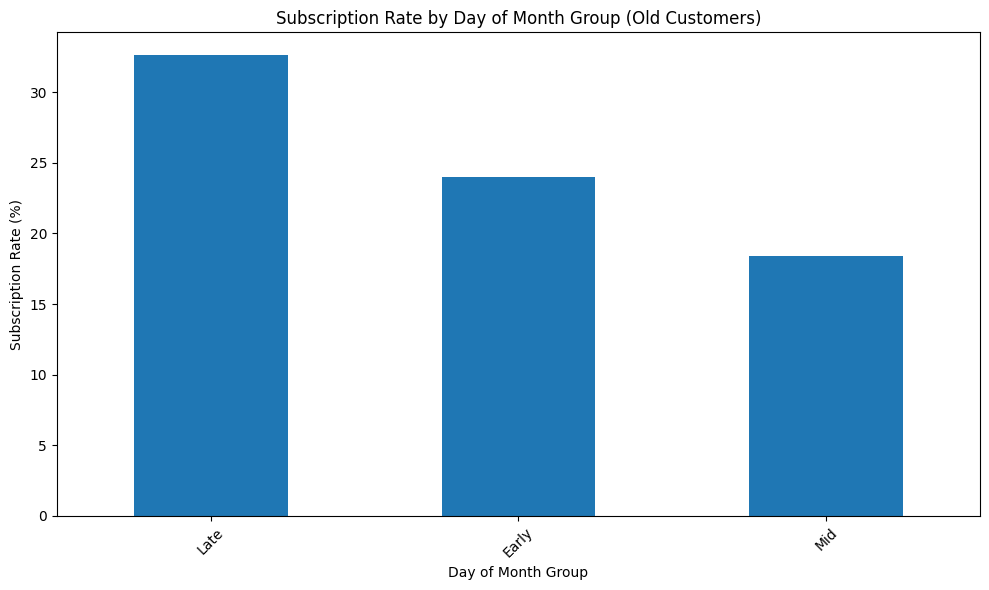

In [359]:
crosstab_day_binned_y_old_normalized["yes"].sort_values(ascending=False).plot(
    kind="bar"
)
plt.title("Subscription Rate by Day of Month Group (Old Customers)")
plt.xlabel("Day of Month Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [360]:
(
    chi2_day_binned_y_old,
    p_day_binned_y_old,
    dof_day_binned_y_old,
    expected_day_binned_y_old,
) = chi2_contingency(crosstab_day_binned_y_old)
print(
    f"Chi-squared: {chi2_day_binned_y_old}, p-value: {p_day_binned_y_old}, degrees of freedom: {dof_day_binned_y_old}"
)

Chi-squared: 134.43291942276946, p-value: 6.430762258581365e-30, degrees of freedom: 2


In [361]:
cramer_v_day_binned_y_old = association(crosstab_day_binned_y_old, method="cramer")
print(f"Cramér's V: {cramer_v_day_binned_y_old}")

Cramér's V: 0.12759735526245555


In [362]:
df_new["day_binned"] = pd.cut(
    df_new["day"], bins=[0, 10, 20, 31], labels=["Early", "Mid", "Late"]
)
df_new["day_binned"].value_counts().sort_index()

day_binned
Early    11008
Mid      14502
Late     11444
Name: count, dtype: int64

In [363]:
crosstab_day_binned_y_new = pd.crosstab(df_new["day_binned"], df_new["y"])
crosstab_day_binned_y_new

y,no,yes
day_binned,,
Early,9926,1082
Mid,13192,1310
Late,10452,992


In [364]:
crosstab_day_binned_y_new_normalized = (
    pd.crosstab(df_new["day_binned"], df_new["y"], normalize="index") * 100
)
crosstab_day_binned_y_new_normalized

y,no,yes
day_binned,,
Early,90.170785,9.829215
Mid,90.966763,9.033237
Late,91.331702,8.668298


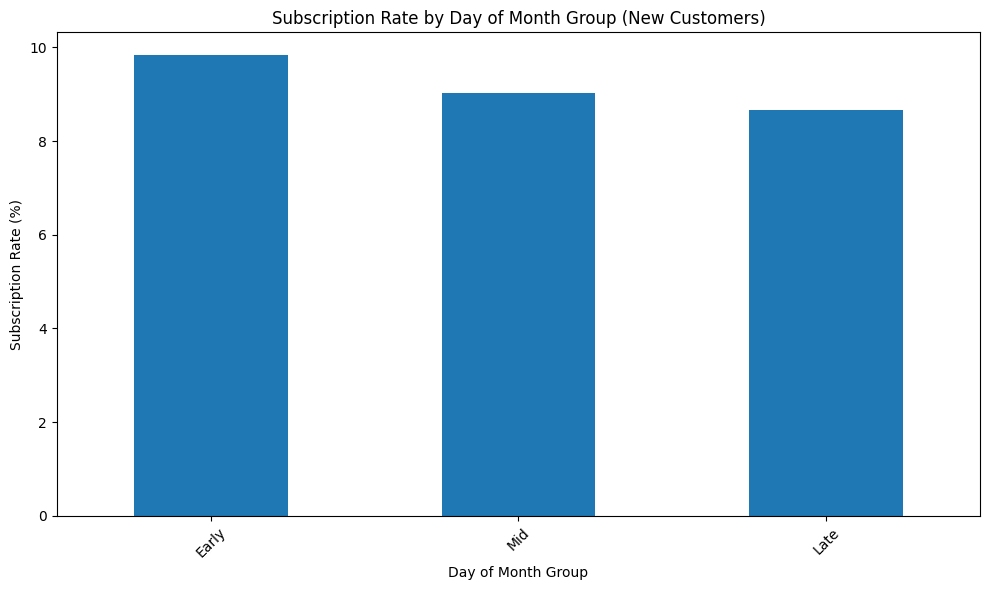

In [365]:
crosstab_day_binned_y_new_normalized["yes"].sort_values(ascending=False).plot(
    kind="bar"
)
plt.title("Subscription Rate by Day of Month Group (New Customers)")
plt.xlabel("Day of Month Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [366]:
(
    chi2_day_binned_y_new,
    p_day_binned_y_new,
    dof_day_binned_y_new,
    expected_day_binned_y_new,
) = chi2_contingency(crosstab_day_binned_y_new)
print(
    f"Chi-squared: {chi2_day_binned_y_new}, p-value: {p_day_binned_y_new}, degrees of freedom: {dof_day_binned_y_new}"
)

Chi-squared: 9.532085163618598, p-value: 0.008514007064638127, degrees of freedom: 2


In [367]:
cramer_v_day_binned_y_new = association(crosstab_day_binned_y_new, method="cramer")
print(f"Cramér's V: {cramer_v_day_binned_y_new}")

Cramér's V: 0.01606065413475097


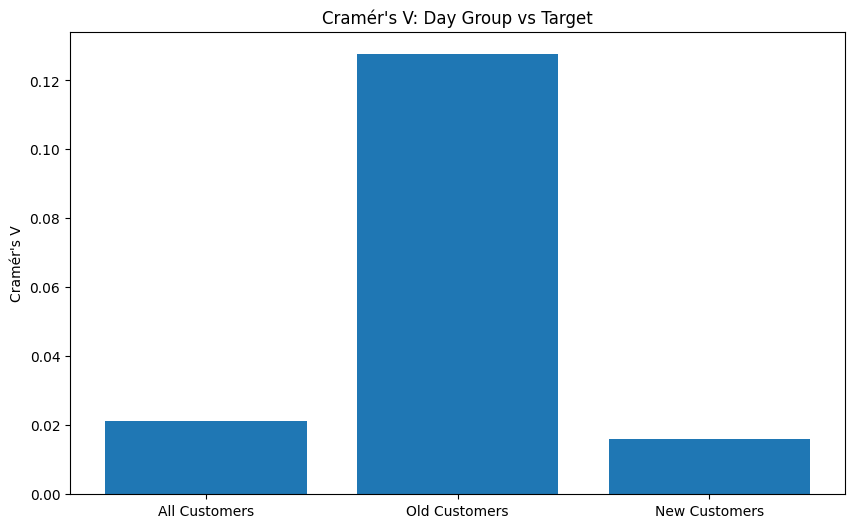

In [368]:
labels = ["All Customers", "Old Customers", "New Customers"]
values = [cramer_v_day_binned_y, cramer_v_day_binned_y_old, cramer_v_day_binned_y_new]
plt.bar(labels, values)
plt.title("Cramér's V: Day Group vs Target")
plt.ylabel("Cramér's V")
plt.show()

As expected, it only worth to keep for old customers (due to small sample being small, we got more feature importance)

##### duration and target

In [369]:
duration_grouped_by_y = df.groupby("y")["duration"].describe()
duration_grouped_by_y

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,39922.0,221.182806,207.383237,0.0,95.0,164.0,279.0,4918.0
yes,5289.0,537.294574,392.525262,8.0,244.0,426.0,725.0,3881.0


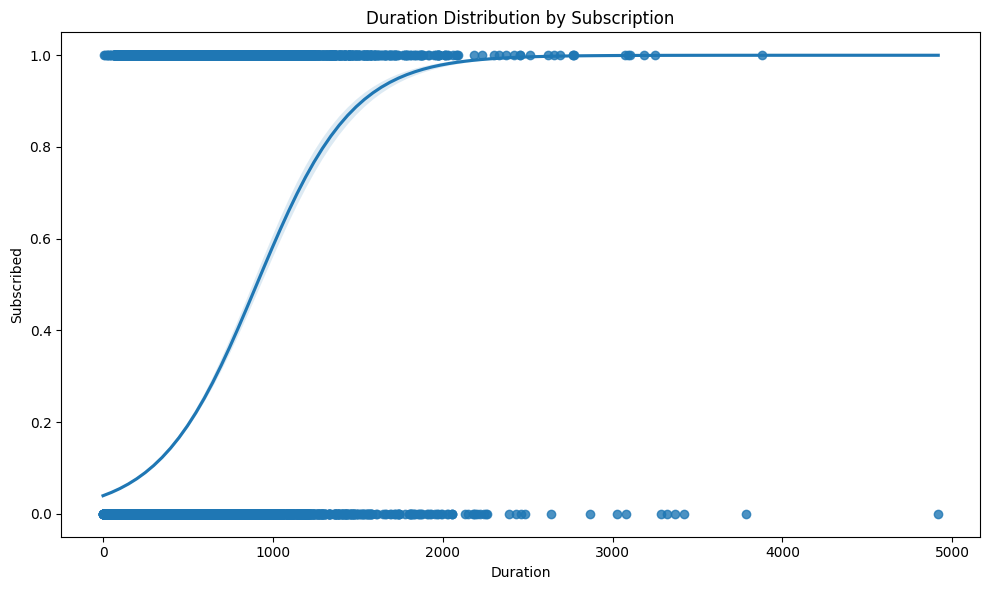

In [370]:
sns.regplot(data=df, x="duration", y="y_numeric", logistic=True)
plt.title("Duration Distribution by Subscription")
plt.xlabel("Duration")
plt.ylabel("Subscribed")
plt.tight_layout()
plt.show()

In [371]:
r_spearman_duration_y, p_spearman_duration_y = spearmanr(
    df["duration"], df["y_numeric"]
)
r_spearman_duration_y_squared = r_spearman_duration_y**2
print(
    f"Spearman Correlation (r): {r_spearman_duration_y:.4f}, p-value: {p_spearman_duration_y:.4f}"
)
print(
    f"Variance in subscription explained by duration: {r_spearman_duration_y_squared * 100:.2f}%"
)

Spearman Correlation (r): 0.3425, p-value: 0.0000
Variance in subscription explained by duration: 11.73%


This feature has a strong prediction value, but I think it is not suitable to add it to our model because we want know their decision before making the call not after (which doesn't make sense at all)

##### pdays and target

I think we should only check this feature for old customers

In [372]:
pdays_grouped_by_y_old = df_old.groupby("y")["pdays"].describe()
pdays_grouped_by_y_old

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,6352.0,234.191436,111.022439,1.0,153.0,232.0,335.0,871.0
yes,1905.0,192.521785,123.441816,1.0,94.0,181.0,246.0,854.0


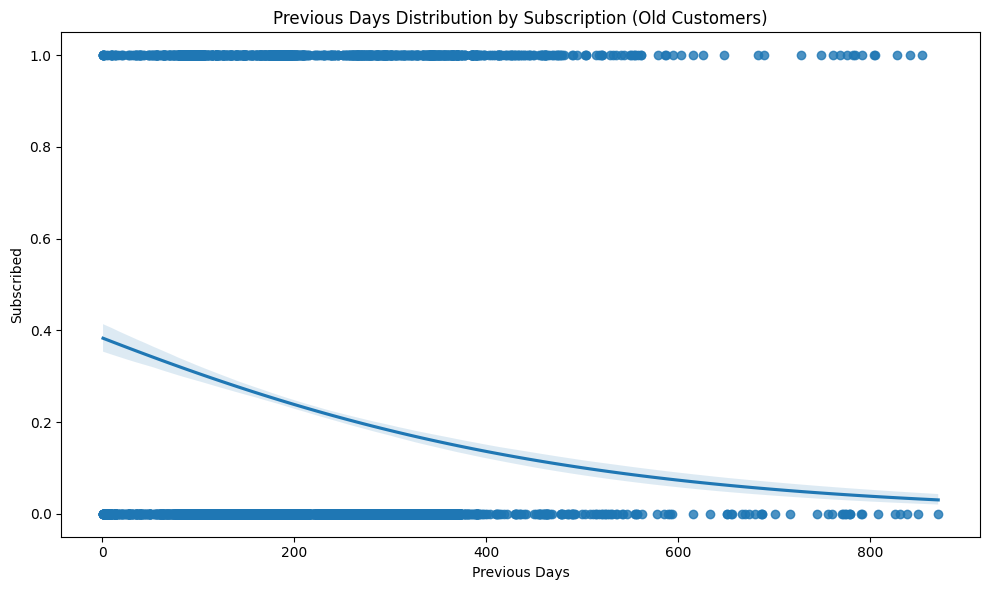

In [373]:
sns.regplot(data=df_old, x="pdays", y="y_numeric", logistic=True)
plt.title("Previous Days Distribution by Subscription (Old Customers)")
plt.xlabel("Previous Days")
plt.ylabel("Subscribed")
plt.tight_layout()
plt.show()

In [374]:
r_spearman_pdays_y_old, p_spearman_pdays_y_old = spearmanr(
    df_old["pdays"], df_old["y_numeric"]
)
r_spearman_pdays_y_old_squared = r_spearman_pdays_y_old**2
print(
    f"Spearman Correlation (r): {r_spearman_pdays_y_old:.4f}, p-value: {p_spearman_pdays_y_old:.4f}"
)
print(
    f"Variance in subscription explained by previous days: {r_spearman_pdays_y_old_squared * 100:.2f}%"
)

Spearman Correlation (r): -0.1862, p-value: 0.0000
Variance in subscription explained by previous days: 3.47%


We can include this feature as a predictor as well

##### previous and target

In [375]:
previous_grouped_by_y_old = df_old.groupby("y")["previous"].describe()
previous_grouped_by_y_old

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,6352.0,3.156014,4.861754,1.0,1.0,2.0,4.0,275.0
yes,1905.0,3.249344,3.368521,1.0,1.0,2.0,4.0,58.0


It makes sense to cap 275 entry to maximum value. It is likely an error.

In [376]:
df_old = df_old[df_old["previous"] != 275]

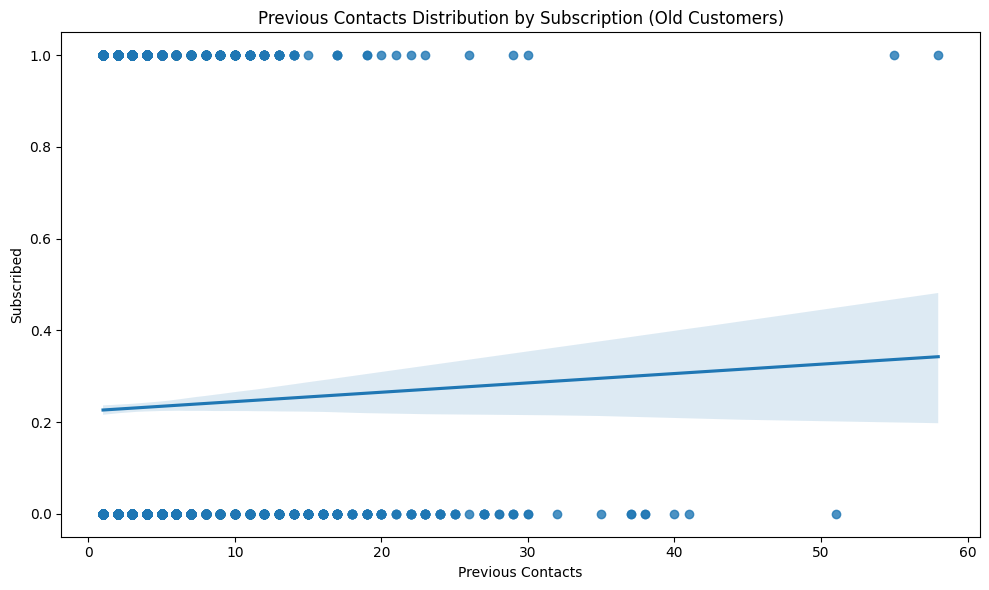

In [377]:
sns.regplot(data=df_old, x="previous", y="y_numeric")
plt.title("Previous Contacts Distribution by Subscription (Old Customers)")
plt.xlabel("Previous Contacts")
plt.ylabel("Subscribed")
plt.tight_layout()
plt.show()

In [378]:
r_spearman_previous_y_old, p_spearman_previous_y_old = spearmanr(
    df_old["previous"], df_old["y_numeric"]
)
r_spearman_previous_y_old_squared = r_spearman_previous_y_old**2
print(
    f"Spearman Correlation (r): {r_spearman_previous_y_old:.4f}, p-value: {p_spearman_previous_y_old:.4f}"
)
print(
    f"Variance in subscription explained by previous contacts: {r_spearman_previous_y_old_squared * 100:.2f}%"
)

Spearman Correlation (r): 0.0465, p-value: 0.0000
Variance in subscription explained by previous contacts: 0.22%


Let's try binning for this feature as well

In [379]:
df_old["previous_binned"] = pd.cut(
    df_old["previous"],
    bins=[0, 1, 2, df_old["previous"].max()],
    labels=["1", "2", "3+"],
)
df_old["previous_binned"].value_counts().sort_index()

previous_binned
1     2772
2     2106
3+    3378
Name: count, dtype: int64

In [380]:
crosstab_previous_binned_y_old = pd.crosstab(df_old["previous_binned"], df_old["y"])
crosstab_previous_binned_y_old

y,no,yes
previous_binned,,
1,2189,583
2,1650,456
3+,2512,866


In [381]:
crosstab_previous_binned_y_old_normalized = (
    pd.crosstab(df_old["previous_binned"], df_old["y"], normalize="index") * 100
)
crosstab_previous_binned_y_old_normalized

y,no,yes
previous_binned,,
1,78.968254,21.031746
2,78.347578,21.652422
3+,74.363529,25.636471


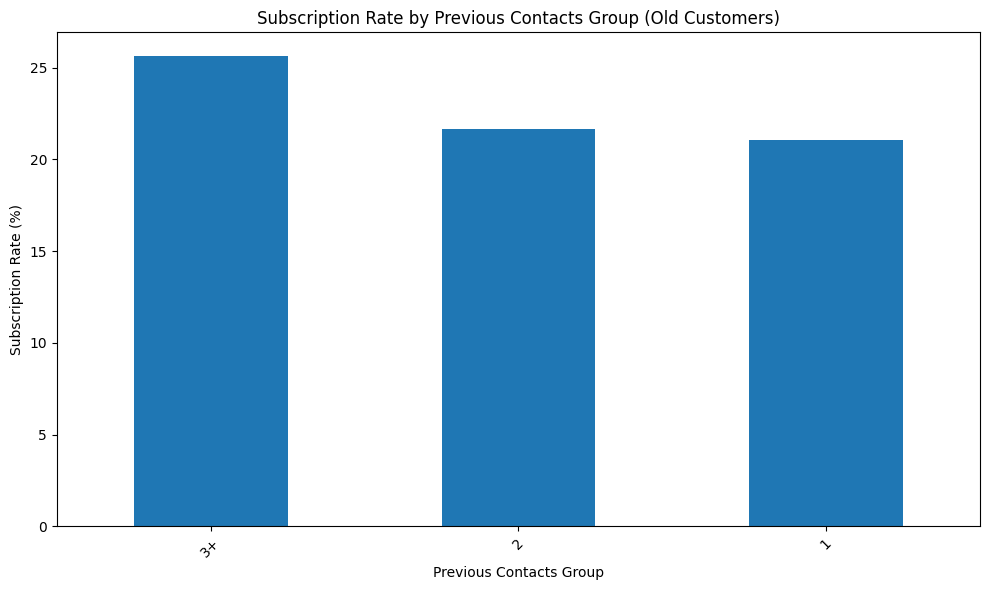

In [382]:
crosstab_previous_binned_y_old_normalized["yes"].sort_values(ascending=False).plot(
    kind="bar"
)
plt.title("Subscription Rate by Previous Contacts Group (Old Customers)")
plt.xlabel("Previous Contacts Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [383]:
(
    chi2_previous_binned_y_old,
    p_previous_binned_y_old,
    dof_previous_binned_y_old,
    expected_previous_binned_y_old,
) = chi2_contingency(crosstab_previous_binned_y_old)
print(
    f"Chi-squared: {chi2_previous_binned_y_old}, p-value: {p_previous_binned_y_old}, degrees of freedom: {dof_previous_binned_y_old}"
)

Chi-squared: 21.407506133192697, p-value: 2.2460483839825747e-05, degrees of freedom: 2


In [384]:
cramer_v_previous_binned_y_old = association(
    crosstab_previous_binned_y_old, method="cramer"
)
print(f"Cramér's V: {cramer_v_previous_binned_y_old}")

Cramér's V: 0.05092114920811855


This feature is negligible

## Preprocessing and Modelling

### Modelling without splitting the dataset (without duration feature)

In [385]:
all_features_base = [
    "age",
    "balance",
    "day",
    "campaign",
    "pdays",
    "previous",
    "default",
    "housing",
    "loan",
    "education",
    "job",
    "marital",
    "contact",
    "month",
    "poutcome",
]

cat_features_base = [
    "default",
    "housing",
    "loan",
    "education",
    "job",
    "marital",
    "contact",
    "month",
    "poutcome",
]

X_base = df[all_features_base].copy()
y_base = df["y_numeric"].copy()

X_train_base, X_test_base, y_train_base, y_test_base = train_test_split(
    X_base, y_base, test_size=0.2, random_state=42, stratify=y_base
)

pipeline_base = Pipeline(
    steps=[
        (
            "model",
            CatBoostClassifier(
                cat_features=cat_features_base,
                auto_class_weights="Balanced",
                iterations=500,
                learning_rate=0.1,
                depth=6,
                random_seed=42,
                verbose=0,
            ),
        )
    ]
)

In [386]:
pipeline_base.fit(X_train_base, y_train_base)
y_pred_base = pipeline_base.predict(X_test_base)

In [387]:
report_base = classification_report(
    y_test_base, y_pred_base, target_names=["no", "yes"], output_dict=True
)
pd.DataFrame(report_base).T

,precision,recall,f1-score,support
no,0.945396,0.849969,0.895146,7985.000000
yes,0.357296,0.629490,0.455852,1058.000000
accuracy,0.824173,0.824173,0.824173,0.824173
macro avg,0.651346,0.739729,0.675499,9043.000000
weighted avg,0.876591,0.824173,0.843750,9043.000000


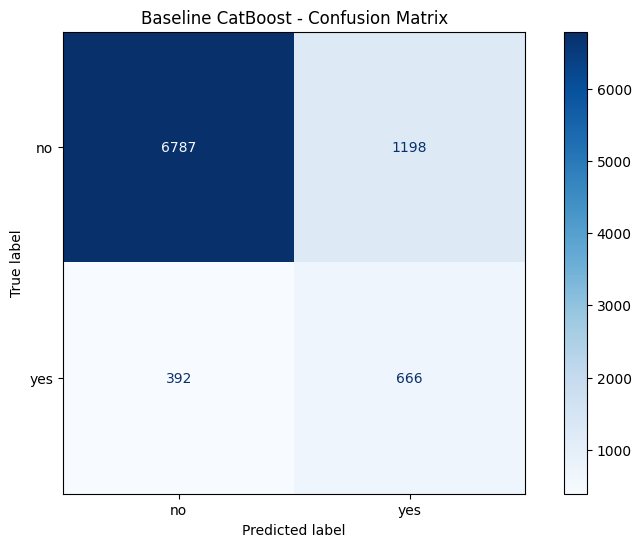

In [388]:
cm_base = confusion_matrix(y_test_base, y_pred_base)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_base, display_labels=["no", "yes"])
disp.plot(cmap="Blues")
plt.title("Baseline CatBoost - Confusion Matrix")
plt.show()

### Modelling with two different customer groups (without duration feature)

In [389]:
class ValueReplacer(BaseEstimator, TransformerMixin):
    def __init__(self, column, old_value, new_value):
        self.column = column
        self.old_value = old_value
        self.new_value = new_value

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X[self.column] = X[self.column].replace(self.old_value, self.new_value)
        return X

In [390]:
df_old_split = df[df["pdays"] != -1].copy()
df_new_split = df[df["pdays"] == -1].copy()

# New Customers
features_new_split = [
    "age",
    "balance",
    "day",
    "campaign",
    "default",
    "housing",
    "loan",
    "education",
    "job",
    "marital",
    "contact",
    "month",
]
cat_features_new_split = [
    "default",
    "housing",
    "loan",
    "education",
    "job",
    "marital",
    "contact",
    "month",
]

X_new_split = df_new_split[features_new_split].copy()
y_new_split = df_new_split["y_numeric"].copy()

X_train_new_split, X_test_new_split, y_train_new_split, y_test_new_split = (
    train_test_split(
        X_new_split, y_new_split, test_size=0.2, random_state=42, stratify=y_new_split
    )
)

pipeline_new_split = Pipeline(
    steps=[
        ("replace_contact", ValueReplacer("contact", "unknown", "cellular")),
        (
            "model",
            CatBoostClassifier(
                cat_features=cat_features_new_split,
                auto_class_weights="Balanced",
                iterations=500,
                learning_rate=0.1,
                depth=6,
                random_seed=42,
                verbose=0,
            ),
        ),
    ]
)

# Old Customers
features_old_split = [
    "age",
    "balance",
    "day",
    "campaign",
    "pdays",
    "previous",
    "default",
    "housing",
    "loan",
    "education",
    "job",
    "marital",
    "contact",
    "month",
    "poutcome",
]
cat_features_old_split = [
    "default",
    "housing",
    "loan",
    "education",
    "job",
    "marital",
    "contact",
    "month",
    "poutcome",
]

X_old_split = df_old_split[features_old_split].copy()
y_old_split = df_old_split["y_numeric"].copy()

X_train_old_split, X_test_old_split, y_train_old_split, y_test_old_split = (
    train_test_split(
        X_old_split, y_old_split, test_size=0.2, random_state=42, stratify=y_old_split
    )
)

pipeline_old_split = Pipeline(
    steps=[
        ("replace_poutcome", ValueReplacer("poutcome", "unknown", "other")),
        (
            "model",
            CatBoostClassifier(
                cat_features=cat_features_old_split,
                auto_class_weights="Balanced",
                iterations=500,
                learning_rate=0.1,
                depth=6,
                random_seed=42,
                verbose=0,
            ),
        ),
    ]
)

In [391]:
pipeline_new_split.fit(X_train_new_split, y_train_new_split)
pipeline_old_split.fit(X_train_old_split, y_train_old_split)

y_pred_new_split = pipeline_new_split.predict(X_test_new_split)
y_pred_old_split = pipeline_old_split.predict(X_test_old_split)

In [392]:
y_test_combined_split = pd.concat([y_test_new_split, y_test_old_split])
y_pred_combined_split = np.concatenate([y_pred_new_split, y_pred_old_split])

report_split = classification_report(
    y_test_combined_split,
    y_pred_combined_split,
    target_names=["no", "yes"],
    output_dict=True,
)
pd.DataFrame(report_split).T

,precision,recall,f1-score,support
no,0.936195,0.819537,0.873990,7985.00000
yes,0.298100,0.578450,0.393443,1058.00000
accuracy,0.791330,0.791330,0.791330,0.79133
macro avg,0.617147,0.698993,0.633716,9043.00000
weighted avg,0.861540,0.791330,0.817768,9043.00000


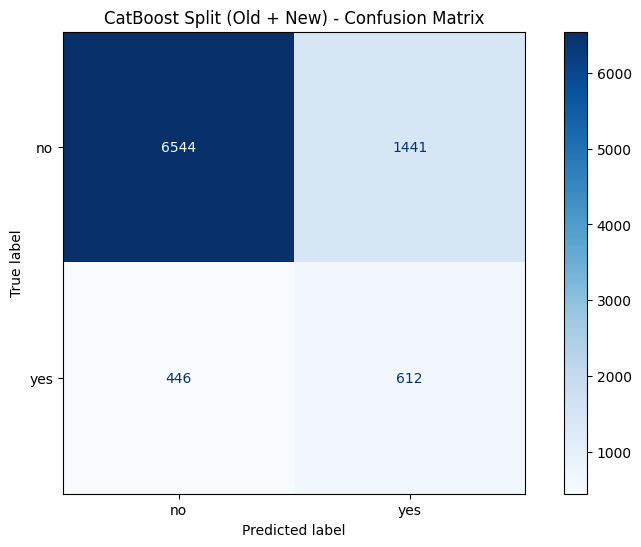

In [393]:
cm_split = confusion_matrix(y_test_combined_split, y_pred_combined_split)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_split, display_labels=["no", "yes"])
disp.plot(cmap="Blues")
plt.title("CatBoost Split (Old + New) - Confusion Matrix")
plt.show()

Seperating customer group hasn't made any positive effect on our prediction

### Baseline CatBoost with Optuna Tuning (without duration feature)

In [ ]:
def objective(trial):
    params = {
        "iterations": trial.suggest_int("iterations", 100, 500),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "depth": trial.suggest_int("depth", 3, 10),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 10),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0, 1),
        "border_count": trial.suggest_int("border_count", 32, 255),
    }

    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    scores = []

    for train_idx, val_idx in cv.split(X_train_base, y_train_base):
        X_fold_train = X_train_base.iloc[train_idx]
        X_fold_val = X_train_base.iloc[val_idx]
        y_fold_train = y_train_base.iloc[train_idx]
        y_fold_val = y_train_base.iloc[val_idx]

        model = CatBoostClassifier(
            cat_features=cat_features_base,
            auto_class_weights="Balanced",
            random_seed=42,
            verbose=0,
            early_stopping_rounds=50,
            **params,
        )
        model.fit(X_fold_train, y_fold_train, eval_set=(X_fold_val, y_fold_val))
        y_pred = model.predict(X_fold_val)
        scores.append(f1_score(y_fold_val, y_pred, pos_label=1, average="binary"))

    return np.mean(scores)


study_base = optuna.create_study(direction="maximize")
study_base.optimize(objective, n_trials=20, show_progress_bar=True)

print(f"Best params: {study_base.best_params}")

  0%|          | 0/20 [00:00<?, ?it/s]

Best params: {'iterations': 454, 'learning_rate': 0.021663833962670923, 'depth': 9, 'l2_leaf_reg': 5.870166281585018, 'bagging_temperature': 0.8003391308781458, 'border_count': 220}


In [404]:
pipeline_base_tuned = Pipeline(
    steps=[
        (
            "model",
            CatBoostClassifier(
                cat_features=cat_features_base,
                auto_class_weights="Balanced",
                random_seed=42,
                verbose=0,
                **study_base.best_params,
            ),
        )
    ]
)

pipeline_base_tuned.fit(X_train_base, y_train_base)
y_pred_base_tuned = pipeline_base_tuned.predict(X_test_base)

report_base_tuned = classification_report(
    y_test_base, y_pred_base_tuned, target_names=["no", "yes"], output_dict=True
)
pd.DataFrame(report_base_tuned).T

,precision,recall,f1-score,support
no,0.944383,0.850595,0.895039,7985.000000
yes,0.355484,0.621928,0.452389,1058.000000
accuracy,0.823842,0.823842,0.823842,0.823842
macro avg,0.649933,0.736262,0.673714,9043.000000
weighted avg,0.875483,0.823842,0.843250,9043.000000


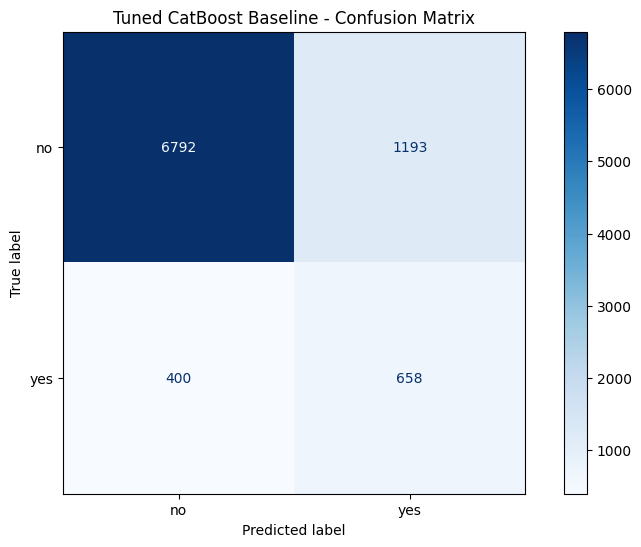

In [405]:
cm_base_tuned = confusion_matrix(y_test_base, y_pred_base_tuned)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_base_tuned, display_labels=["no", "yes"]
)
disp.plot(cmap="Blues")
plt.title("Tuned CatBoost Baseline - Confusion Matrix")
plt.show()

### Baseline XGBoost with Optuna Tuning (without duration feature)

In [408]:
encoder_xgb = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)

X_train_base_xgb = X_train_base.copy()
X_test_base_xgb = X_test_base.copy()

X_train_base_xgb[cat_features_base] = encoder_xgb.fit_transform(
    X_train_base[cat_features_base]
)
X_test_base_xgb[cat_features_base] = encoder_xgb.transform(
    X_test_base[cat_features_base]
)

scale_pos_weight_base = (y_train_base == 0).sum() / (y_train_base == 1).sum()

In [ ]:
def objective_xgb(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "reg_lambda": trial.suggest_float("reg_lambda", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
    }

    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    scores = []

    for train_idx, val_idx in cv.split(X_train_base_xgb, y_train_base):
        X_fold_train = X_train_base_xgb.iloc[train_idx]
        X_fold_val = X_train_base_xgb.iloc[val_idx]
        y_fold_train = y_train_base.iloc[train_idx]
        y_fold_val = y_train_base.iloc[val_idx]

        model = XGBClassifier(
            scale_pos_weight=scale_pos_weight_base,
            random_state=42,
            eval_metric="logloss",
            early_stopping_rounds=50,
            verbosity=0,
            **params,
        )
        model.fit(
            X_fold_train,
            y_fold_train,
            eval_set=[(X_fold_val, y_fold_val)],
            verbose=False,
        )
        y_pred = model.predict(X_fold_val)
        scores.append(f1_score(y_fold_val, y_pred, pos_label=1, average="binary"))

    return np.mean(scores)


study_base_xgb = optuna.create_study(direction="maximize")
study_base_xgb.optimize(objective_xgb, n_trials=50, show_progress_bar=True)

print(f"Best params: {study_base_xgb.best_params}")

  0%|          | 0/50 [00:00<?, ?it/s]

Best params: {'n_estimators': 425, 'learning_rate': 0.01224984937387315, 'max_depth': 12, 'reg_lambda': 8.681178394464716, 'subsample': 0.7882379303928453, 'colsample_bytree': 0.5969072916603844, 'min_child_weight': 9}


In [417]:
pipeline_base_xgb_tuned = Pipeline(
    steps=[
        (
            "model",
            XGBClassifier(
                scale_pos_weight=scale_pos_weight_base,
                random_state=42,
                verbosity=0,
                **study_base_xgb.best_params,
            ),
        )
    ]
)

pipeline_base_xgb_tuned.fit(X_train_base_xgb, y_train_base)
y_pred_base_xgb_tuned = pipeline_base_xgb_tuned.predict(X_test_base_xgb)

report_base_xgb_tuned = classification_report(
    y_test_base, y_pred_base_xgb_tuned, target_names=["no", "yes"], output_dict=True
)
pd.DataFrame(report_base_xgb_tuned).T

,precision,recall,f1-score,support
no,0.944188,0.870758,0.905987,7985.000000
yes,0.385348,0.611531,0.472780,1058.000000
accuracy,0.840429,0.840429,0.840429,0.840429
macro avg,0.664768,0.741144,0.689384,9043.000000
weighted avg,0.878806,0.840429,0.855304,9043.000000


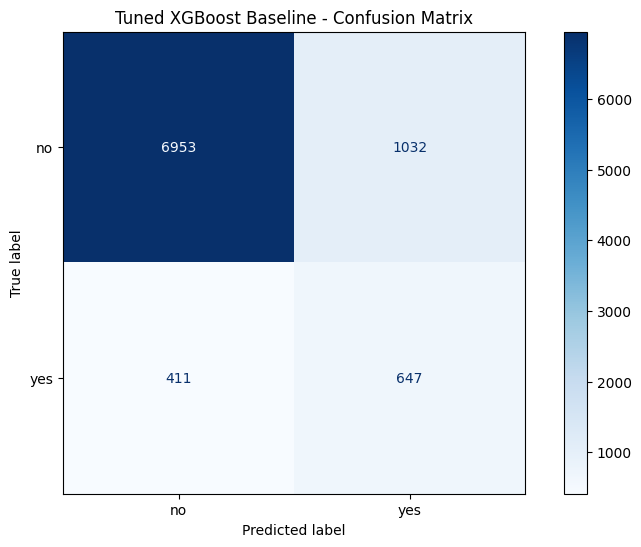

In [418]:
cm_base_xgb_tuned = confusion_matrix(y_test_base, y_pred_base_xgb_tuned)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_base_xgb_tuned, display_labels=["no", "yes"]
)
disp.plot(cmap="Blues")
plt.title("Tuned XGBoost Baseline - Confusion Matrix")
plt.show()

### Baseline CatBoost with Optuna Tuning (with duration feature)

In [ ]:
all_features_dur = all_features_base + ["duration"]

X_dur = df[all_features_dur].copy()
y_dur = df["y_numeric"].copy()

X_train_dur, X_test_dur, y_train_dur, y_test_dur = train_test_split(
    X_dur, y_dur, test_size=0.2, random_state=42, stratify=y_dur
)

In [ ]:
def objective_dur(trial):
    params = {
        "iterations": trial.suggest_int("iterations", 100, 500),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "depth": trial.suggest_int("depth", 3, 10),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 10),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0, 1),
        "border_count": trial.suggest_int("border_count", 32, 255),
    }

    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    scores = []

    for train_idx, val_idx in cv.split(X_train_dur, y_train_dur):
        X_fold_train = X_train_dur.iloc[train_idx]
        X_fold_val = X_train_dur.iloc[val_idx]
        y_fold_train = y_train_dur.iloc[train_idx]
        y_fold_val = y_train_dur.iloc[val_idx]

        model = CatBoostClassifier(
            cat_features=cat_features_base,
            auto_class_weights="Balanced",
            random_seed=42,
            verbose=0,
            early_stopping_rounds=50,
            **params,
        )
        model.fit(X_fold_train, y_fold_train, eval_set=(X_fold_val, y_fold_val))
        y_pred = model.predict(X_fold_val)
        scores.append(f1_score(y_fold_val, y_pred, pos_label=1, average="binary"))

    return np.mean(scores)


study_dur = optuna.create_study(direction="maximize")
study_dur.optimize(objective_dur, n_trials=20, show_progress_bar=True)

print(f"Best params: {study_dur.best_params}")

  0%|          | 0/20 [00:00<?, ?it/s]

Best params: {'iterations': 412, 'learning_rate': 0.0949218143877791, 'depth': 9, 'l2_leaf_reg': 9.681295660494715, 'bagging_temperature': 0.010856311657042192, 'border_count': 164}


In [ ]:
pipeline_dur_tuned = Pipeline(
    steps=[
        (
            "model",
            CatBoostClassifier(
                cat_features=cat_features_base,
                auto_class_weights="Balanced",
                random_seed=42,
                verbose=0,
                **study_dur.best_params,
            ),
        )
    ]
)

pipeline_dur_tuned.fit(X_train_dur, y_train_dur)
y_pred_dur_tuned = pipeline_dur_tuned.predict(X_test_dur)

report_dur_tuned = classification_report(
    y_test_dur, y_pred_dur_tuned, target_names=["no", "yes"], output_dict=True
)
pd.DataFrame(report_dur_tuned).T

,precision,recall,f1-score,support
no,0.975425,0.884784,0.927896,7985.00000
yes,0.488889,0.831758,0.615815,1058.00000
accuracy,0.878580,0.878580,0.878580,0.87858
macro avg,0.732157,0.858271,0.771856,9043.00000
weighted avg,0.918502,0.878580,0.891384,9043.00000


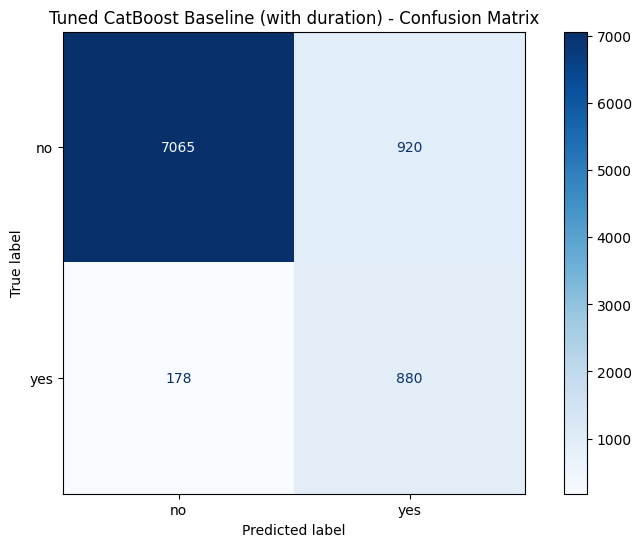

In [ ]:
cm_dur_tuned = confusion_matrix(y_test_dur, y_pred_dur_tuned)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dur_tuned, display_labels=["no", "yes"]
)
disp.plot(cmap="Blues")
plt.title("Tuned CatBoost Baseline (with duration) - Confusion Matrix")
plt.show()

### Baseline XGBoost with Optuna Tuning (with duration feature)

In [ ]:
encoder_xgb_dur = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)

X_train_dur_xgb = X_train_dur.copy()
X_test_dur_xgb = X_test_dur.copy()

X_train_dur_xgb[cat_features_base] = encoder_xgb_dur.fit_transform(
    X_train_dur[cat_features_base]
)
X_test_dur_xgb[cat_features_base] = encoder_xgb_dur.transform(
    X_test_dur[cat_features_base]
)

In [ ]:
def objective_xgb_dur(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "reg_lambda": trial.suggest_float("reg_lambda", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
    }

    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    scores = []

    for train_idx, val_idx in cv.split(X_train_dur_xgb, y_train_dur):
        X_fold_train = X_train_dur_xgb.iloc[train_idx]
        X_fold_val = X_train_dur_xgb.iloc[val_idx]
        y_fold_train = y_train_dur.iloc[train_idx]
        y_fold_val = y_train_dur.iloc[val_idx]

        model = XGBClassifier(
            scale_pos_weight=scale_pos_weight_base,
            random_state=42,
            eval_metric="logloss",
            early_stopping_rounds=50,
            verbosity=0,
            **params,
        )
        model.fit(
            X_fold_train,
            y_fold_train,
            eval_set=[(X_fold_val, y_fold_val)],
            verbose=False,
        )
        y_pred = model.predict(X_fold_val)
        scores.append(f1_score(y_fold_val, y_pred, pos_label=1, average="binary"))

    return np.mean(scores)


study_xgb_dur = optuna.create_study(direction="maximize")
study_xgb_dur.optimize(objective_xgb_dur, n_trials=50, show_progress_bar=True)

print(f"Best params: {study_xgb_dur.best_params}")

  0%|          | 0/50 [00:00<?, ?it/s]

Best params: {'n_estimators': 575, 'learning_rate': 0.020067495619144324, 'max_depth': 9, 'reg_lambda': 3.2866756958750494, 'subsample': 0.8039185153274749, 'colsample_bytree': 0.7240121089267313, 'min_child_weight': 1}


In [ ]:
pipeline_xgb_dur_tuned = Pipeline(
    steps=[
        (
            "model",
            XGBClassifier(
                scale_pos_weight=scale_pos_weight_base,
                random_state=42,
                verbosity=0,
                **study_xgb_dur.best_params,
            ),
        )
    ]
)

pipeline_xgb_dur_tuned.fit(X_train_dur_xgb, y_train_dur)
y_pred_xgb_dur_tuned = pipeline_xgb_dur_tuned.predict(X_test_dur_xgb)

report_xgb_dur_tuned = classification_report(
    y_test_dur, y_pred_xgb_dur_tuned, target_names=["no", "yes"], output_dict=True
)
pd.DataFrame(report_xgb_dur_tuned).T

,precision,recall,f1-score,support
no,0.970932,0.895178,0.931518,7985.000000
yes,0.502082,0.797732,0.616283,1058.000000
accuracy,0.883778,0.883778,0.883778,0.883778
macro avg,0.736507,0.846455,0.773900,9043.000000
weighted avg,0.916078,0.883778,0.894636,9043.000000


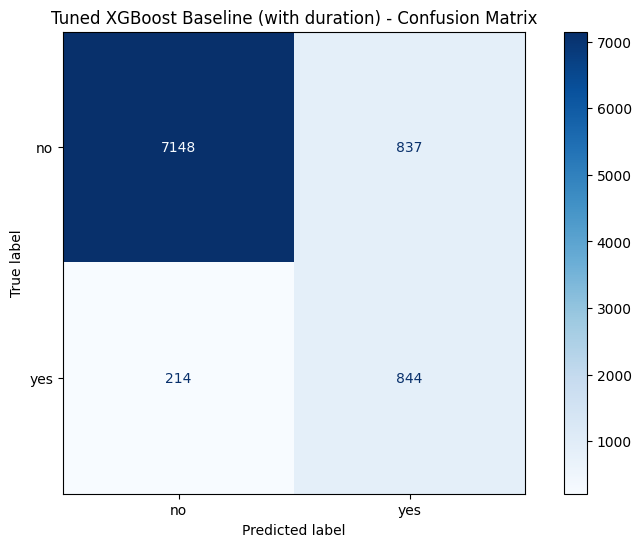

In [ ]:
cm_xgb_dur_tuned = confusion_matrix(y_test_dur, y_pred_xgb_dur_tuned)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb_dur_tuned, display_labels=["no", "yes"]
)
disp.plot(cmap="Blues")
plt.title("Tuned XGBoost Baseline (with duration) - Confusion Matrix")
plt.show()